# RQ1-RQ3 publication figure prototypes

This notebook reads accepted, saved result tables only. It does not load models, run inference, select thresholds, or recompute bootstrap replicates.

Prototype scope:

1. RQ1 six-model performance bar-chart grid.
2. RQ2 six-panel GSV vs Shapley-Lorenz importance bars.
3. RQ3 Female-minus-Male signed-gap point and 95% bootstrap-CI grid.


## 1. Setup and shared visual style

In [1]:
from pathlib import Path
import time
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Image, display


def find_repo_root():
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / 'artifacts' / 'dataset_b').exists() and (candidate / 'notebooks' / 'dataset_b').exists():
            return candidate
    raise FileNotFoundError('Could not locate the DAP391m_GR12 repository root.')


REPO_ROOT = find_repo_root()
OUTPUT_ROOT = REPO_ROOT / 'reports' / 'figures' / 'publication'
PROTOTYPE_DIR = OUTPUT_ROOT / 'prototypes'
SLIDE_DIR = OUTPUT_ROOT / 'slide'
REPORT_DIR = OUTPUT_ROOT / 'report'
for directory in (PROTOTYPE_DIR, SLIDE_DIR, REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = ['lr', 'rf', 'xgboost', 'plain_mlp', 'realmlp', 'tabmmini']
MODEL_LABELS = {
    'lr': 'LR',
    'rf': 'RF',
    'xgboost': 'XGB',
    'plain_mlp': 'PlainMLP',
    'realmlp': 'RealMLP',
    'tabmmini': 'TabMmini',
}
MODEL_COLORS = {
    'lr': '#7F8C8D',
    'rf': '#56B4E9',
    'xgboost': '#0072B2',
    'plain_mlp': '#E69F00',
    'realmlp': '#CC79A7',
    'tabmmini': '#D55E00',
}
METHOD_COLORS = {'gsv': '#2563EB', 'shapley_lorenz': '#F59E0B'}

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#4B5563',
    'axes.labelcolor': '#263238',
    'axes.titlecolor': '#111827',
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#D9DEE5',
    'grid.linestyle': '--',
    'grid.linewidth': 0.7,
    'grid.alpha': 0.65,
    'font.family': 'DejaVu Sans',
    'font.size': 10.5,
    'xtick.color': '#374151',
    'ytick.color': '#374151',
    'savefig.facecolor': 'white',
})


def polish_axis(ax, grid_axis='y'):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(0.9)
    ax.spines['bottom'].set_linewidth(0.9)
    ax.grid(False)
    ax.grid(True, axis=grid_axis)


def save_figure_file(fig, output_path, **savefig_kwargs):
    output_path = Path(output_path)
    temporary_path = output_path.with_name(
        f'.{output_path.stem}.{uuid4().hex}.tmp{output_path.suffix}'
    )
    try:
        fig.savefig(temporary_path, **savefig_kwargs)
        for attempt in range(5):
            try:
                temporary_path.replace(output_path)
                return
            except OSError:
                if attempt == 4:
                    raise
                time.sleep(0.2 * (attempt + 1))
    finally:
        temporary_path.unlink(missing_ok=True)


def export_prototype(fig, stem):
    png_path = PROTOTYPE_DIR / f'{stem}_slide.png'
    svg_path = PROTOTYPE_DIR / f'{stem}_slide.svg'
    save_figure_file(fig, png_path, dpi=200)
    save_figure_file(fig, svg_path)
    print(f'Saved: {png_path.relative_to(REPO_ROOT)}')
    print(f'Saved: {svg_path.relative_to(REPO_ROOT)}')
    display(Image(filename=str(png_path)))
    plt.close(fig)
    return png_path, svg_path

print(f'Repository: {REPO_ROOT}')
print(f'Prototype output: {PROTOTYPE_DIR}')


Repository: D:\FPTU_Study\FA2026\DAP391m_GR12
Prototype output: D:\FPTU_Study\FA2026\DAP391m_GR12\reports\figures\publication\prototypes


## 2. RQ1 prototype - six-model performance overview

Bars show Test point estimates. Whiskers show the stored 95% bootstrap confidence intervals. All six rate axes begin at zero. This interpretation note stays in Markdown so the exported figure needs only one title.

In [2]:
RQ1_FILES = {
    'lr': REPO_ROOT / 'artifacts/dataset_b/lr/final/lr_final_15f_20261002_01/reporting/rq1_metrics_long.csv',
    'rf': REPO_ROOT / 'artifacts/dataset_b/rf/final/rf_final_15f_20261002_01/reporting/rq1_metrics_long.csv',
    'xgboost': REPO_ROOT / 'artifacts/dataset_b/xgboost/final/xgb_final_15f_20261003_01/reporting/rq1_metrics_long.csv',
    'plain_mlp': REPO_ROOT / 'artifacts/dataset_b/plain_mlp/final/plain_mlp_final_15f_20261004_03/reporting/rq1_metrics_long.csv',
    'realmlp': REPO_ROOT / 'artifacts/dataset_b/realmlp/final/realmlp_final_15f_20261004_01/reporting/rq1_metrics_long.csv',
    'tabmmini': REPO_ROOT / 'artifacts/dataset_b/tabmmini/final/tabmmini_final_15f_20261004_01/reporting/rq1_metrics_long.csv',
}
RQ1_METRICS = [
    ('roc_auc_approved', 'ROC-AUC · Approved'),
    ('average_precision_denied', 'Average Precision · Denied'),
    ('balanced_accuracy', 'Balanced Accuracy'),
    ('f1_denied', 'F1 · Denied'),
    ('precision_denied', 'Precision · Denied'),
    ('recall_denied', 'Recall · Denied'),
]

rq1_frames = []
for model_key, source_path in RQ1_FILES.items():
    if not source_path.exists():
        raise FileNotFoundError(source_path)
    frame = pd.read_csv(source_path)
    frame = frame.loc[frame['metric'].isin([metric for metric, _ in RQ1_METRICS])].copy()
    frame['model_key'] = model_key
    rq1_frames.append(frame)

rq1 = pd.concat(rq1_frames, ignore_index=True)
expected_pairs = {(model, metric) for model in MODEL_ORDER for metric, _ in RQ1_METRICS}
actual_pairs = set(zip(rq1['model_key'], rq1['metric']))
assert actual_pairs == expected_pairs, f'RQ1 model/metric coverage mismatch: {expected_pairs ^ actual_pairs}'
assert len(rq1) == len(expected_pairs)
assert rq1[['estimate', 'ci_low', 'ci_high']].notna().all().all()
assert (rq1['ci_low'] <= rq1['estimate']).all() and (rq1['estimate'] <= rq1['ci_high']).all()
assert (rq1['valid_replicates'] == 1000).all()

rq1[['model_key', 'metric', 'estimate', 'ci_low', 'ci_high']].head(12)


,model_key,metric,estimate,ci_low,ci_high
0,lr,average_precision_denied,0.696305,0.689280,0.703901
1,lr,balanced_accuracy,0.738384,0.733361,0.743290
2,lr,f1_denied,0.605050,0.598142,0.611809
3,lr,precision_denied,0.578312,0.571138,0.585331
4,lr,recall_denied,0.634380,0.624899,0.642966
5,lr,roc_auc_approved,0.817944,0.813012,0.822304
6,rf,roc_auc_approved,0.840940,0.836295,0.845353
7,rf,average_precision_denied,0.746677,0.739908,0.753442
8,rf,precision_denied,0.598731,0.592022,0.605133
9,rf,recall_denied,0.691799,0.683568,0.700391


Saved: reports\figures\publication\prototypes\rq1_performance_overview_slide.png
Saved: reports\figures\publication\prototypes\rq1_performance_overview_slide.svg


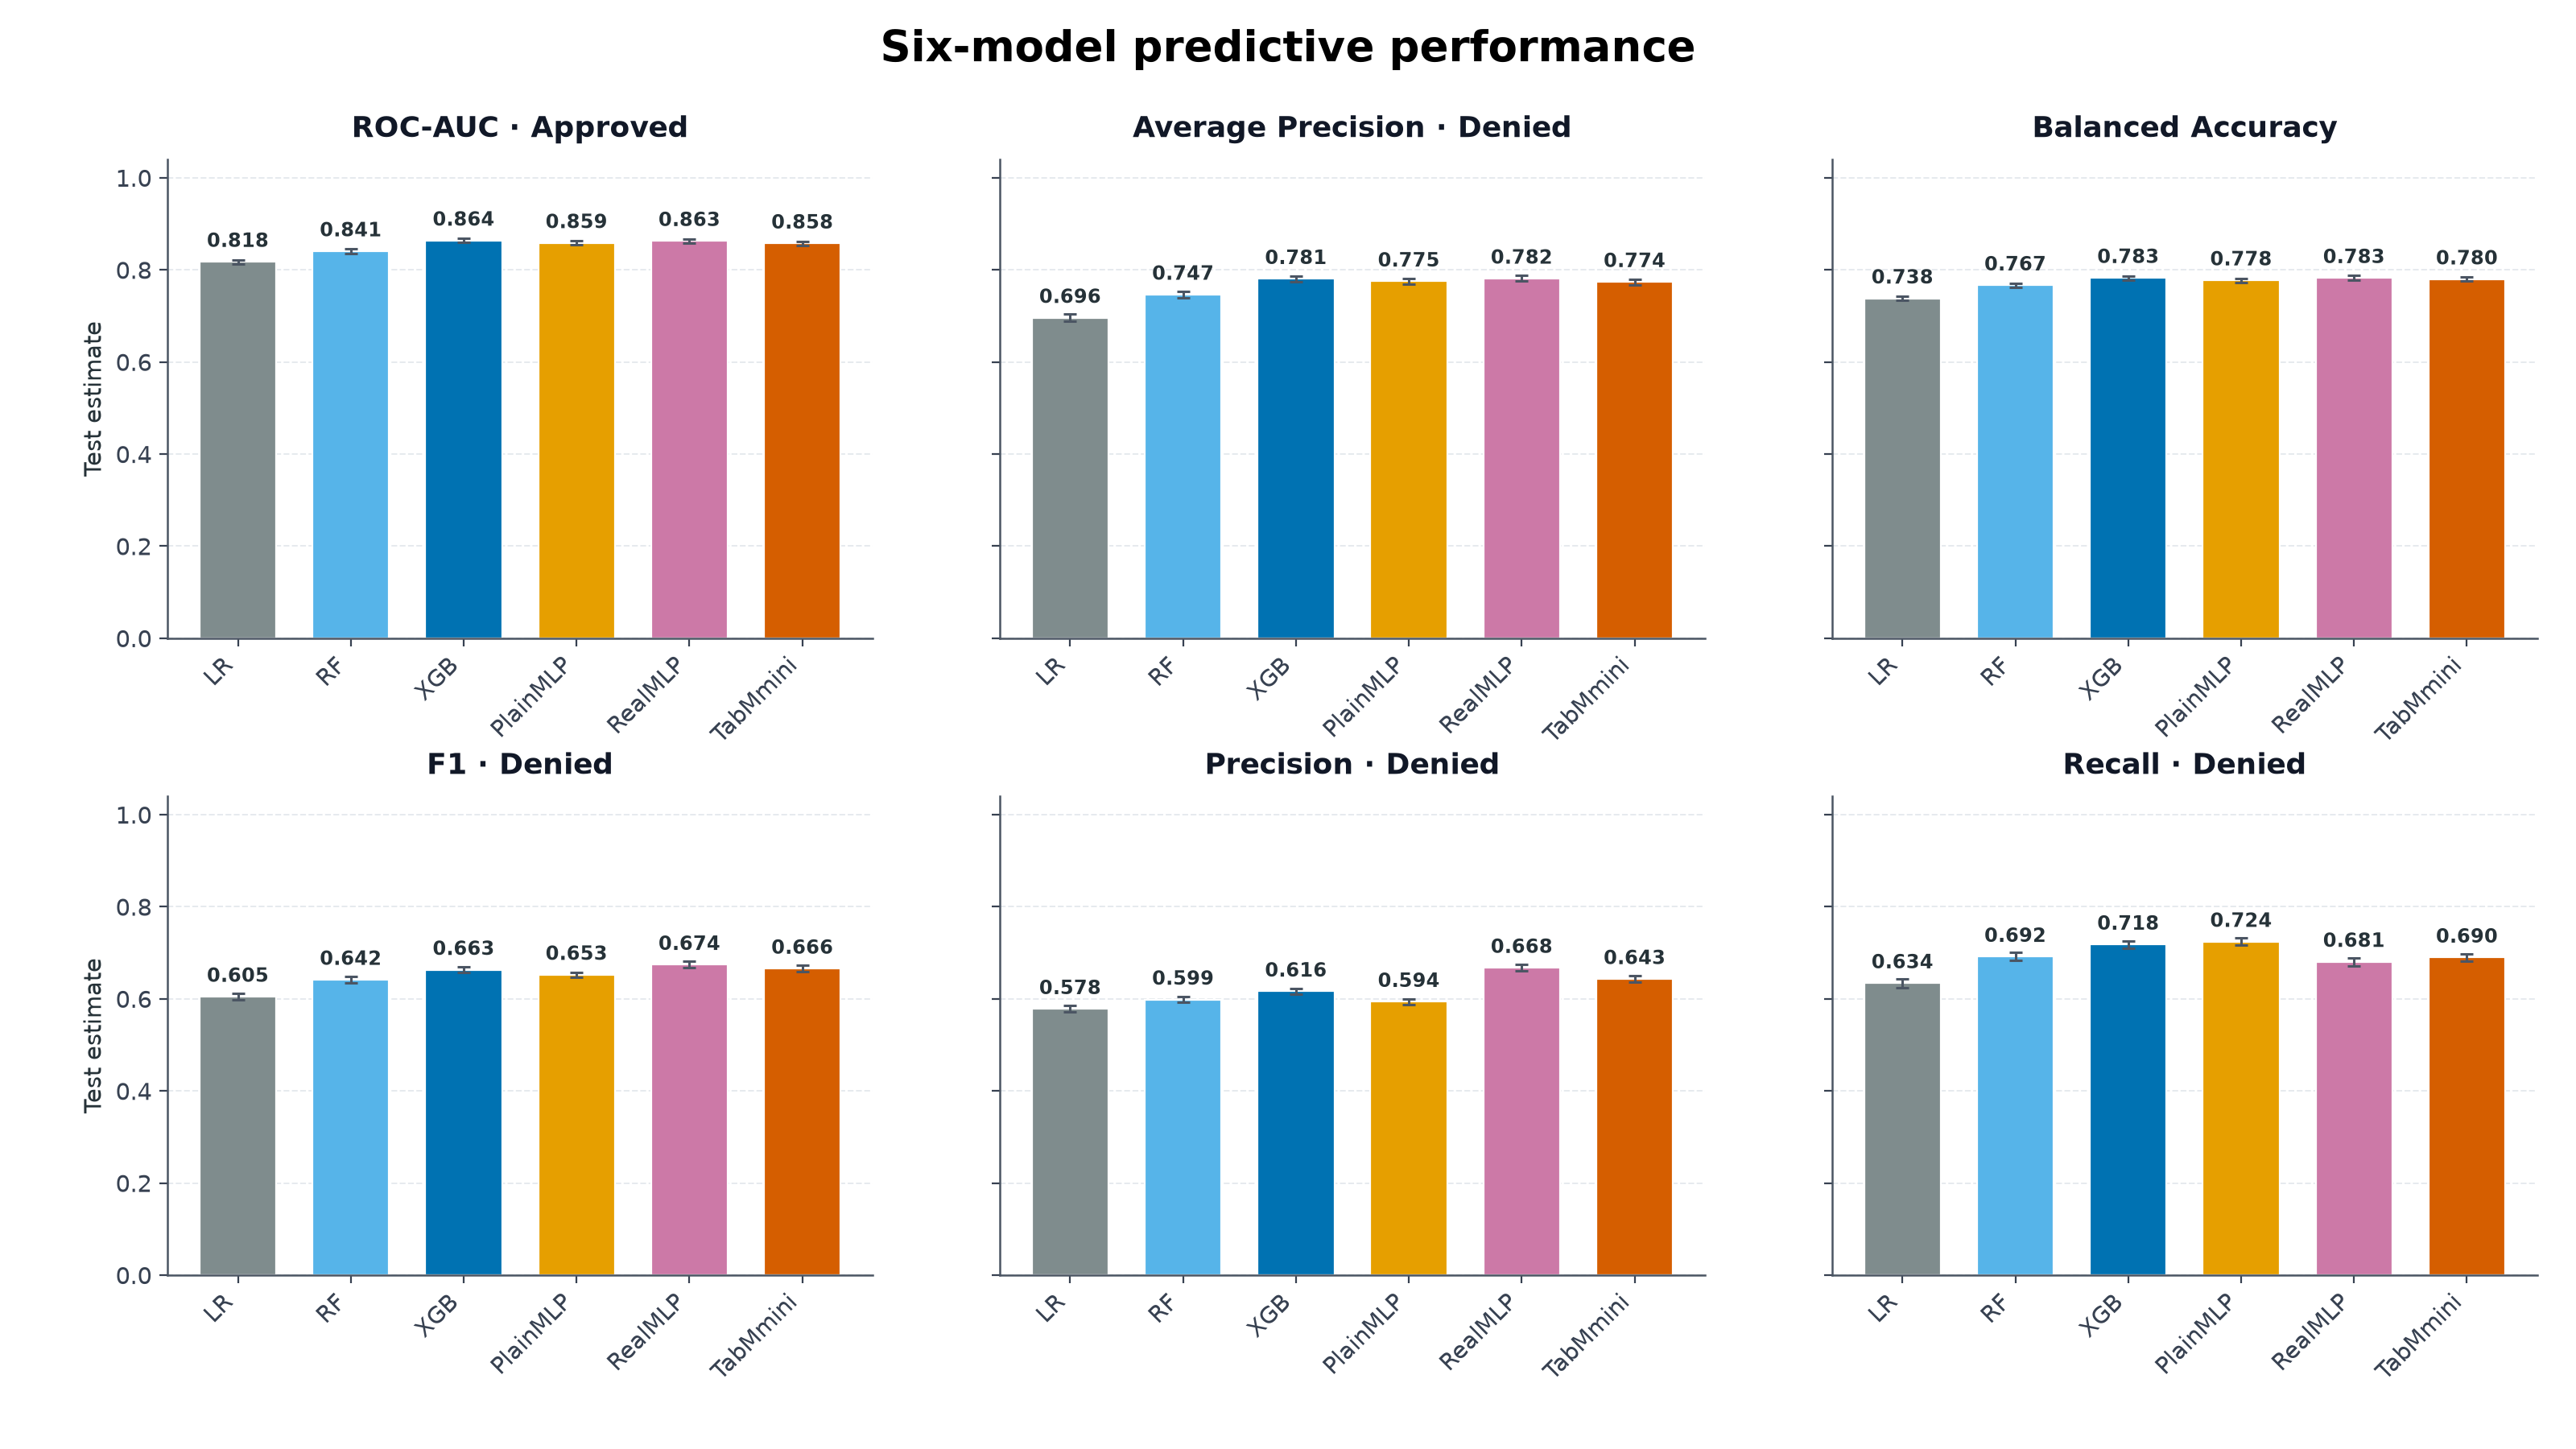

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
x = np.arange(len(MODEL_ORDER))

for ax, (metric, title) in zip(axes.flat, RQ1_METRICS):
    block = rq1.loc[rq1['metric'].eq(metric)].set_index('model_key').loc[MODEL_ORDER]
    estimates = block['estimate'].to_numpy(dtype=float)
    ci_low = block['ci_low'].to_numpy(dtype=float)
    ci_high = block['ci_high'].to_numpy(dtype=float)
    error = np.vstack([estimates - ci_low, ci_high - estimates])
    bars = ax.bar(
        x, estimates, width=0.68, color=[MODEL_COLORS[model] for model in MODEL_ORDER],
        edgecolor='white', linewidth=0.8, yerr=error, capsize=3,
        error_kw={'ecolor': '#4B5563', 'elinewidth': 1.1, 'capthick': 1.1},
    )
    for bar, value in zip(bars, estimates):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.022, f'{value:.3f}',
                ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#263238')
    ax.set_title(title, fontsize=13, pad=10)
    ax.set_xticks(x, [MODEL_LABELS[model] for model in MODEL_ORDER], rotation=45, ha='right')
    ax.set_ylim(0, 1.04)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    polish_axis(ax, grid_axis='y')

axes[0, 0].set_ylabel('Test estimate')
axes[1, 0].set_ylabel('Test estimate')
fig.suptitle('Six-model predictive performance', fontsize=19, fontweight='bold', y=0.98)
fig.subplots_adjust(left=0.065, right=0.985, top=0.89, bottom=0.12, wspace=0.18, hspace=0.33)
rq1_outputs = export_prototype(fig, 'rq1_performance_overview')


## 3. RQ2 prototype - GSV and Shapley-Lorenz importance

The six frozen models are split across two 1 x 3 figures so that every bar can carry a readable value label. Both figures use the same player order and x-axis scale. Importance is normalized separately within each explanation method, following the accepted RQ2 artifact contract.

In [4]:
RQ2_ROOT = REPO_ROOT / 'artifacts/dataset_b/rq2/rq2_cpu_production_20261009_01'
rq2_frames = []
for model_key in MODEL_ORDER:
    source_path = RQ2_ROOT / 'models' / model_key / 'importance.csv'
    if not source_path.exists():
        raise FileNotFoundError(source_path)
    frame = pd.read_csv(source_path)
    frame['model_key'] = model_key
    rq2_frames.append(frame)

rq2 = pd.concat(rq2_frames, ignore_index=True)
assert set(rq2['model_key']) == set(MODEL_ORDER)
assert set(rq2['method']) == {'gsv', 'shapley_lorenz'}
assert rq2.groupby(['model_key', 'method']).size().eq(12).all()
assert rq2['normalized_importance'].notna().all()
assert np.isfinite(rq2['normalized_importance']).all()
assert rq2['normalized_importance'].between(0, 1).all()
assert rq2['result_status'].eq('PASS').all()

player_order = (
    rq2.groupby('player_key', as_index=True)['normalized_importance']
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist()
)
PLAYER_LABELS = {
    'loan_type': 'Loan type',
    'loan_purpose': 'Loan purpose',
    'lien_status': 'Lien status',
    'transaction_characteristics': 'Transaction characteristics',
    'income': 'Income',
    'debt_to_income_ratio': 'Debt-to-income ratio',
    'loan_amount': 'Loan amount',
    'loan_to_value_ratio': 'Loan-to-value ratio',
    'loan_term': 'Loan term',
    'occupancy_type': 'Occupancy type',
    'preapproval': 'Preapproval',
    'special_repayment_structure': 'Special repayment structure',
}
player_order


['debt_to_income_ratio',
 'loan_purpose',
 'loan_to_value_ratio',
 'loan_term',
 'transaction_characteristics',
 'loan_amount',
 'loan_type',
 'income',
 'preapproval',
 'lien_status',
 'special_repayment_structure',
 'occupancy_type']

Saved: reports\figures\publication\prototypes\rq2_gsv_sl_importance_classical_slide.png
Saved: reports\figures\publication\prototypes\rq2_gsv_sl_importance_classical_slide.svg


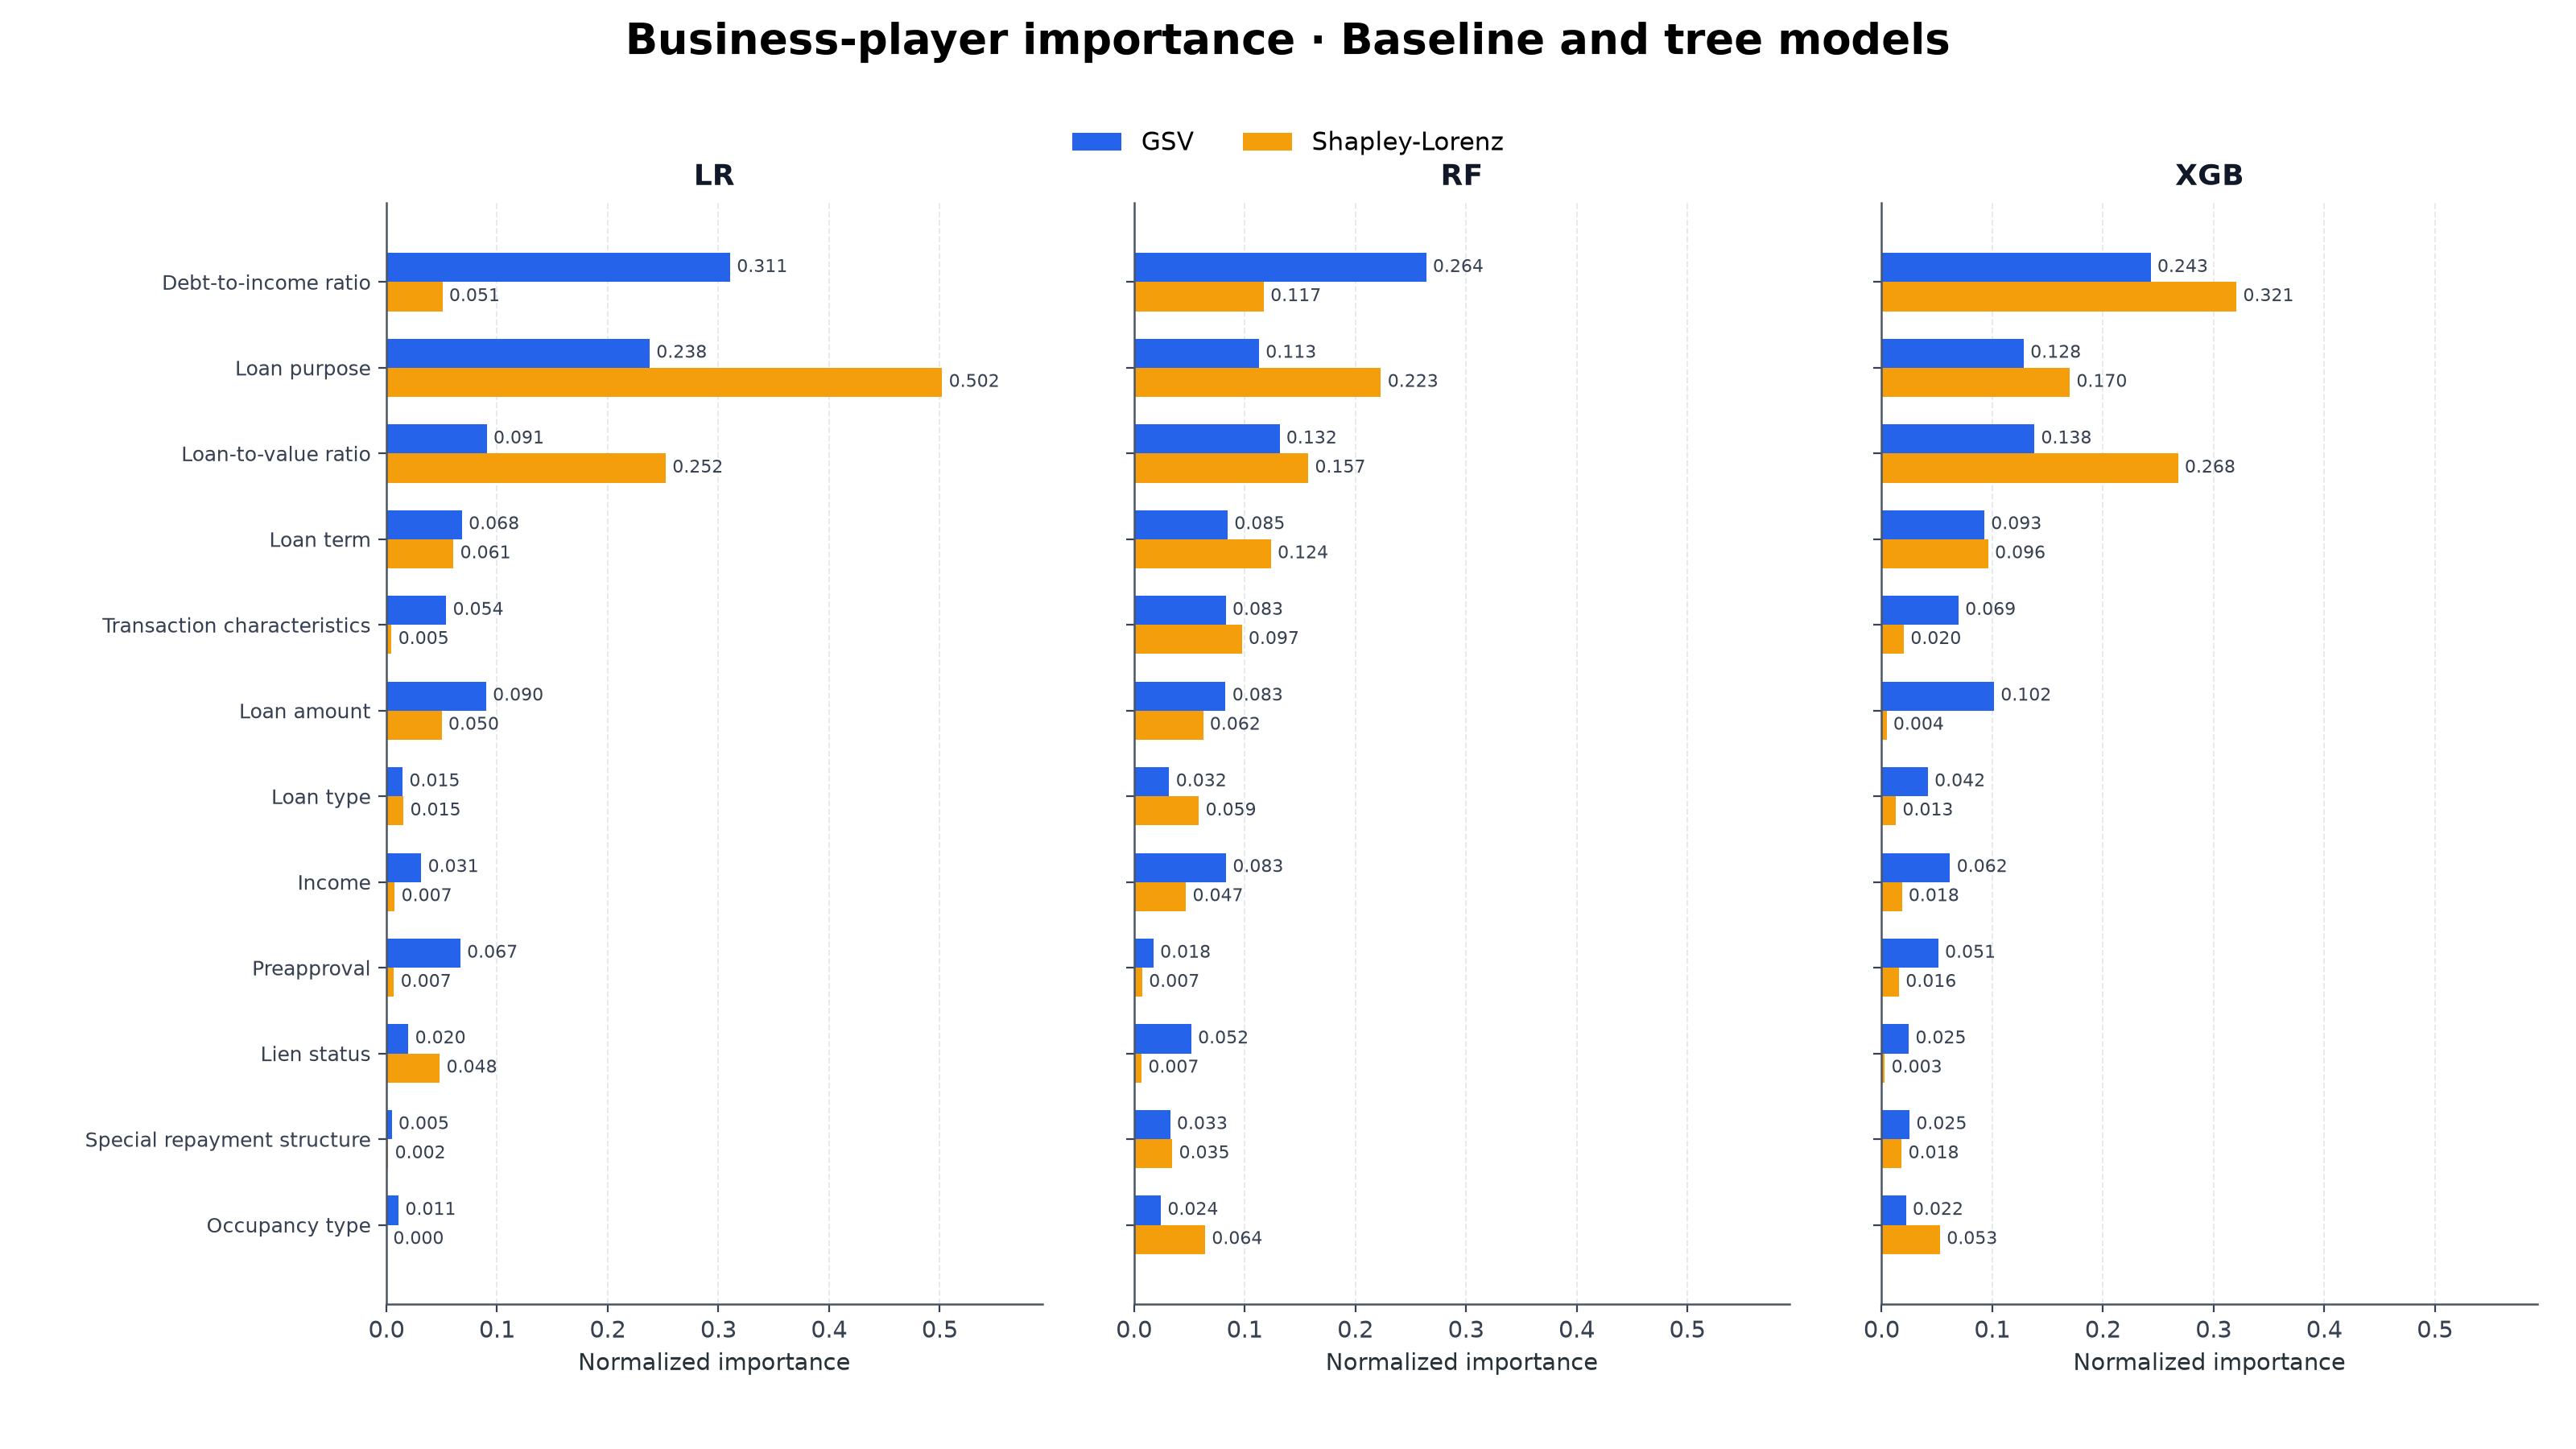

Saved: reports\figures\publication\prototypes\rq2_gsv_sl_importance_neural_slide.png
Saved: reports\figures\publication\prototypes\rq2_gsv_sl_importance_neural_slide.svg


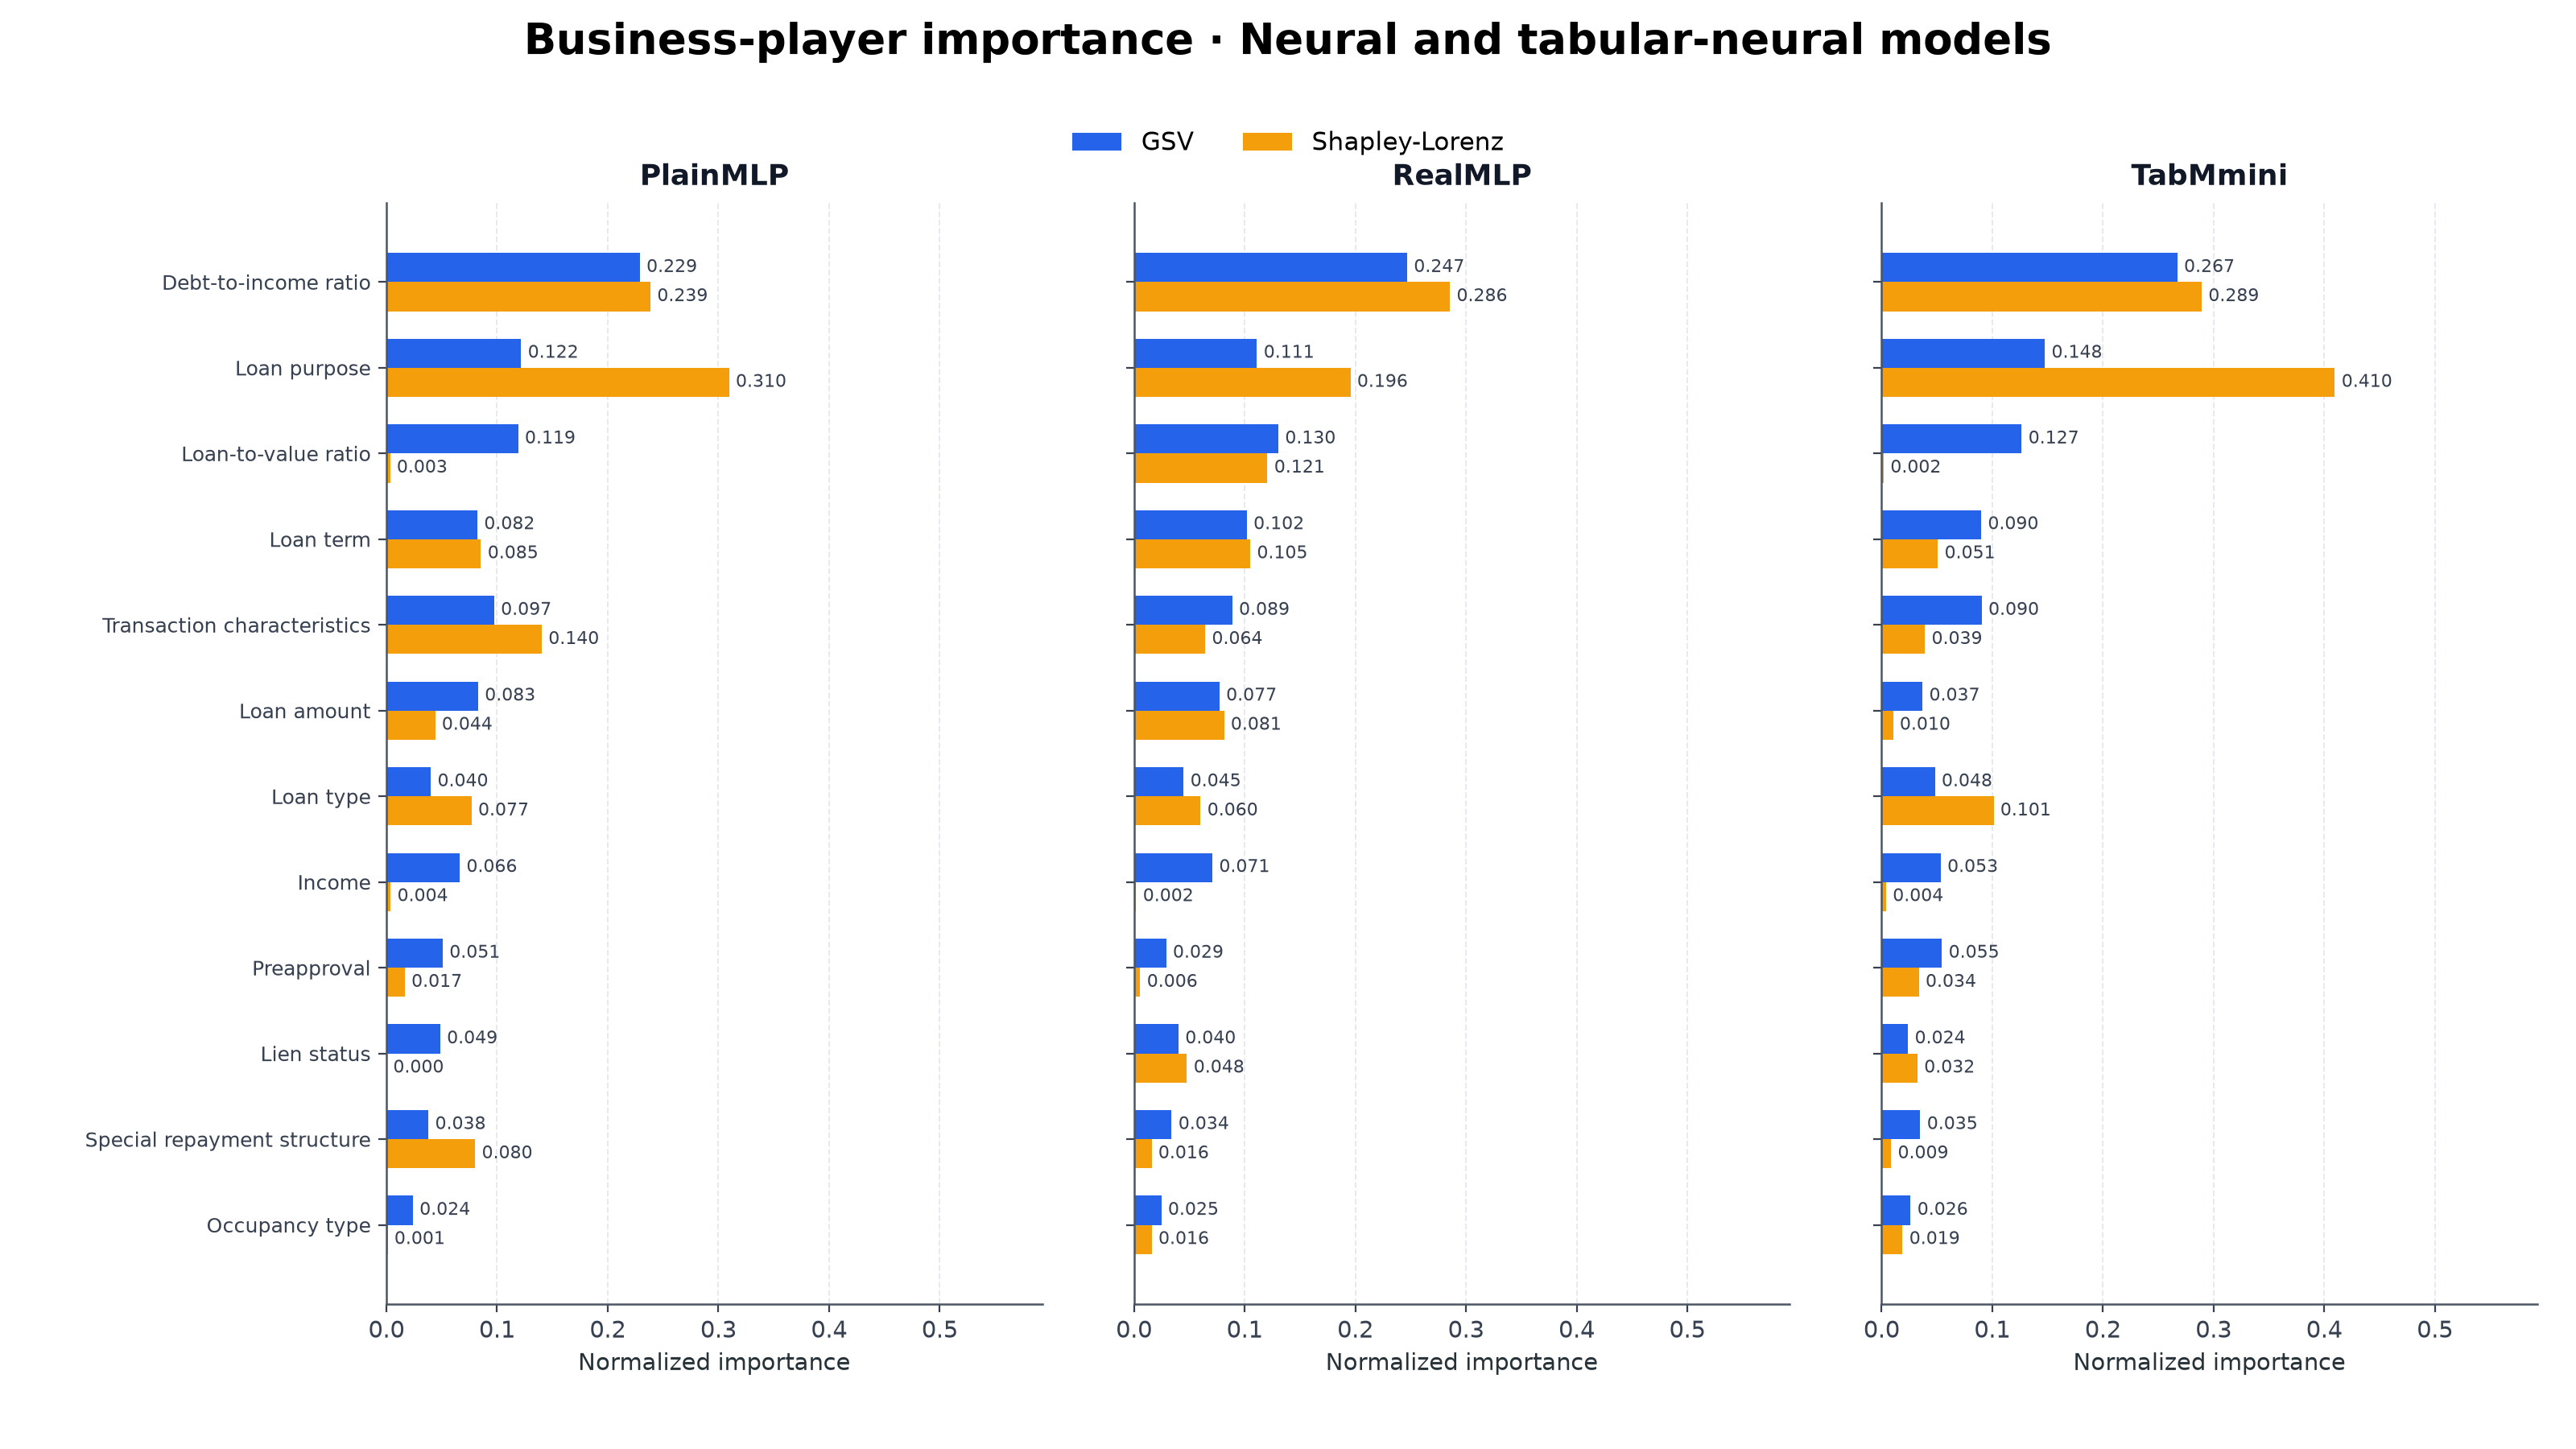

In [5]:
y = np.arange(len(player_order))
bar_height = 0.34
max_importance = float(rq2['normalized_importance'].max())
x_limit = max_importance + max(0.05, max_importance * 0.18)
rq2_model_groups = [
    ('classical', 'Baseline and tree models', ['lr', 'rf', 'xgboost']),
    ('neural', 'Neural and tabular-neural models', ['plain_mlp', 'realmlp', 'tabmmini']),
]

legend_handles = [
    Patch(facecolor=METHOD_COLORS['gsv'], label='GSV'),
    Patch(facecolor=METHOD_COLORS['shapley_lorenz'], label='Shapley-Lorenz'),
]
rq2_outputs = []
for group_slug, group_title, group_models in rq2_model_groups:
    fig, axes = plt.subplots(1, 3, figsize=(16, 9), sharex=True, sharey=True)
    for panel_index, (ax, model_key) in enumerate(zip(axes, group_models)):
        block = rq2.loc[rq2['model_key'].eq(model_key)]
        gsv = block.loc[block['method'].eq('gsv')].set_index('player_key').loc[player_order]
        sl = block.loc[block['method'].eq('shapley_lorenz')].set_index('player_key').loc[player_order]
        gsv_bars = ax.barh(
            y - bar_height / 2, gsv['normalized_importance'], height=bar_height,
            color=METHOD_COLORS['gsv'], label='GSV',
        )
        sl_bars = ax.barh(
            y + bar_height / 2, sl['normalized_importance'], height=bar_height,
            color=METHOD_COLORS['shapley_lorenz'], label='Shapley-Lorenz',
        )
        for bars in (gsv_bars, sl_bars):
            ax.bar_label(
                bars, fmt='%.3f', label_type='edge', padding=3,
                fontsize=7.8, color='#374151',
            )
        ax.set_title(MODEL_LABELS[model_key], fontsize=13, pad=8)
        ax.set_xlim(0, x_limit)
        ax.tick_params(axis='x', labelbottom=True)
        ax.set_xlabel('Normalized importance')
        if panel_index == 0:
            ax.set_yticks(y, [PLAYER_LABELS[player] for player in player_order], fontsize=9)
        else:
            ax.tick_params(axis='y', labelleft=False)
        polish_axis(ax, grid_axis='x')

    axes[0].invert_yaxis()
    fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.925),
               ncol=2, frameon=False, fontsize=11)
    fig.suptitle(
        f'Business-player importance · {group_title}',
        fontsize=19, fontweight='bold', y=0.985,
    )
    fig.subplots_adjust(left=0.15, right=0.985, top=0.86, bottom=0.10, wspace=0.14)
    rq2_outputs.extend(export_prototype(fig, f'rq2_gsv_sl_importance_{group_slug}'))


## 4. RQ3 prototype - Female minus Male signed gaps

Points show the accepted Test-set gap estimates. Vertical whiskers show stored 95% percentile bootstrap confidence intervals. Approved is the positive outcome, and the horizontal zero line indicates no observed group difference under the displayed metric. This interpretation note stays in Markdown rather than inside the exported figure.

In [6]:
RQ3_SOURCE = REPO_ROOT / 'artifacts/dataset_b/rq3/rq3_fairness_20261010_01/bootstrap_summary.csv'
if not RQ3_SOURCE.exists():
    raise FileNotFoundError(RQ3_SOURCE)
rq3_all = pd.read_csv(RQ3_SOURCE)
RQ3_METRICS = [
    ('selection_rate_gap_signed', 'Selection-rate gap'),
    ('tpr_approved_gap_signed', 'TPR Approved gap'),
    ('fpr_approved_gap_signed', 'FPR Approved gap'),
    ('fnr_approved_gap_signed', 'FNR Approved gap'),
]
rq3 = rq3_all.loc[
    rq3_all['result_type'].eq('pairwise')
    & rq3_all['attribute'].eq('applicant_sex')
    & rq3_all['target_group'].eq('Female')
    & rq3_all['reference_group'].eq('Male')
    & rq3_all['metric'].isin([metric for metric, _ in RQ3_METRICS])
].copy()

expected_pairs = {(model, metric) for model in MODEL_ORDER for metric, _ in RQ3_METRICS}
actual_pairs = set(zip(rq3['model'], rq3['metric']))
assert actual_pairs == expected_pairs, f'RQ3 model/metric coverage mismatch: {expected_pairs ^ actual_pairs}'
assert len(rq3) == len(expected_pairs)
assert rq3['ci_status'].eq('defined').all()
assert (rq3['valid_replicates'] == 1000).all()
assert rq3[['point_estimate', 'ci_lower', 'ci_upper']].notna().all().all()
assert (rq3['ci_lower'] <= rq3['point_estimate']).all() and (rq3['point_estimate'] <= rq3['ci_upper']).all()

rq3[['model', 'metric', 'point_estimate', 'ci_lower', 'ci_upper']].head(12)


,model,metric,point_estimate,ci_lower,ci_upper
98,lr,selection_rate_gap_signed,-0.017655,-0.026350,-0.008889
100,lr,tpr_approved_gap_signed,-0.006576,-0.015436,0.001715
102,lr,fpr_approved_gap_signed,-0.030429,-0.049945,-0.013424
104,lr,fnr_approved_gap_signed,0.006576,-0.001715,0.015436
266,rf,selection_rate_gap_signed,-0.010378,-0.019903,-0.001987
268,rf,tpr_approved_gap_signed,0.001855,-0.006030,0.010047
270,rf,fpr_approved_gap_signed,-0.024176,-0.041543,-0.005782
272,rf,fnr_approved_gap_signed,-0.001855,-0.010047,0.006030
434,xgboost,selection_rate_gap_signed,-0.014894,-0.024166,-0.006389
436,xgboost,tpr_approved_gap_signed,-0.005188,-0.013224,0.002777


Saved: reports\figures\publication\prototypes\rq3_sex_gap_ci_slide.png
Saved: reports\figures\publication\prototypes\rq3_sex_gap_ci_slide.svg


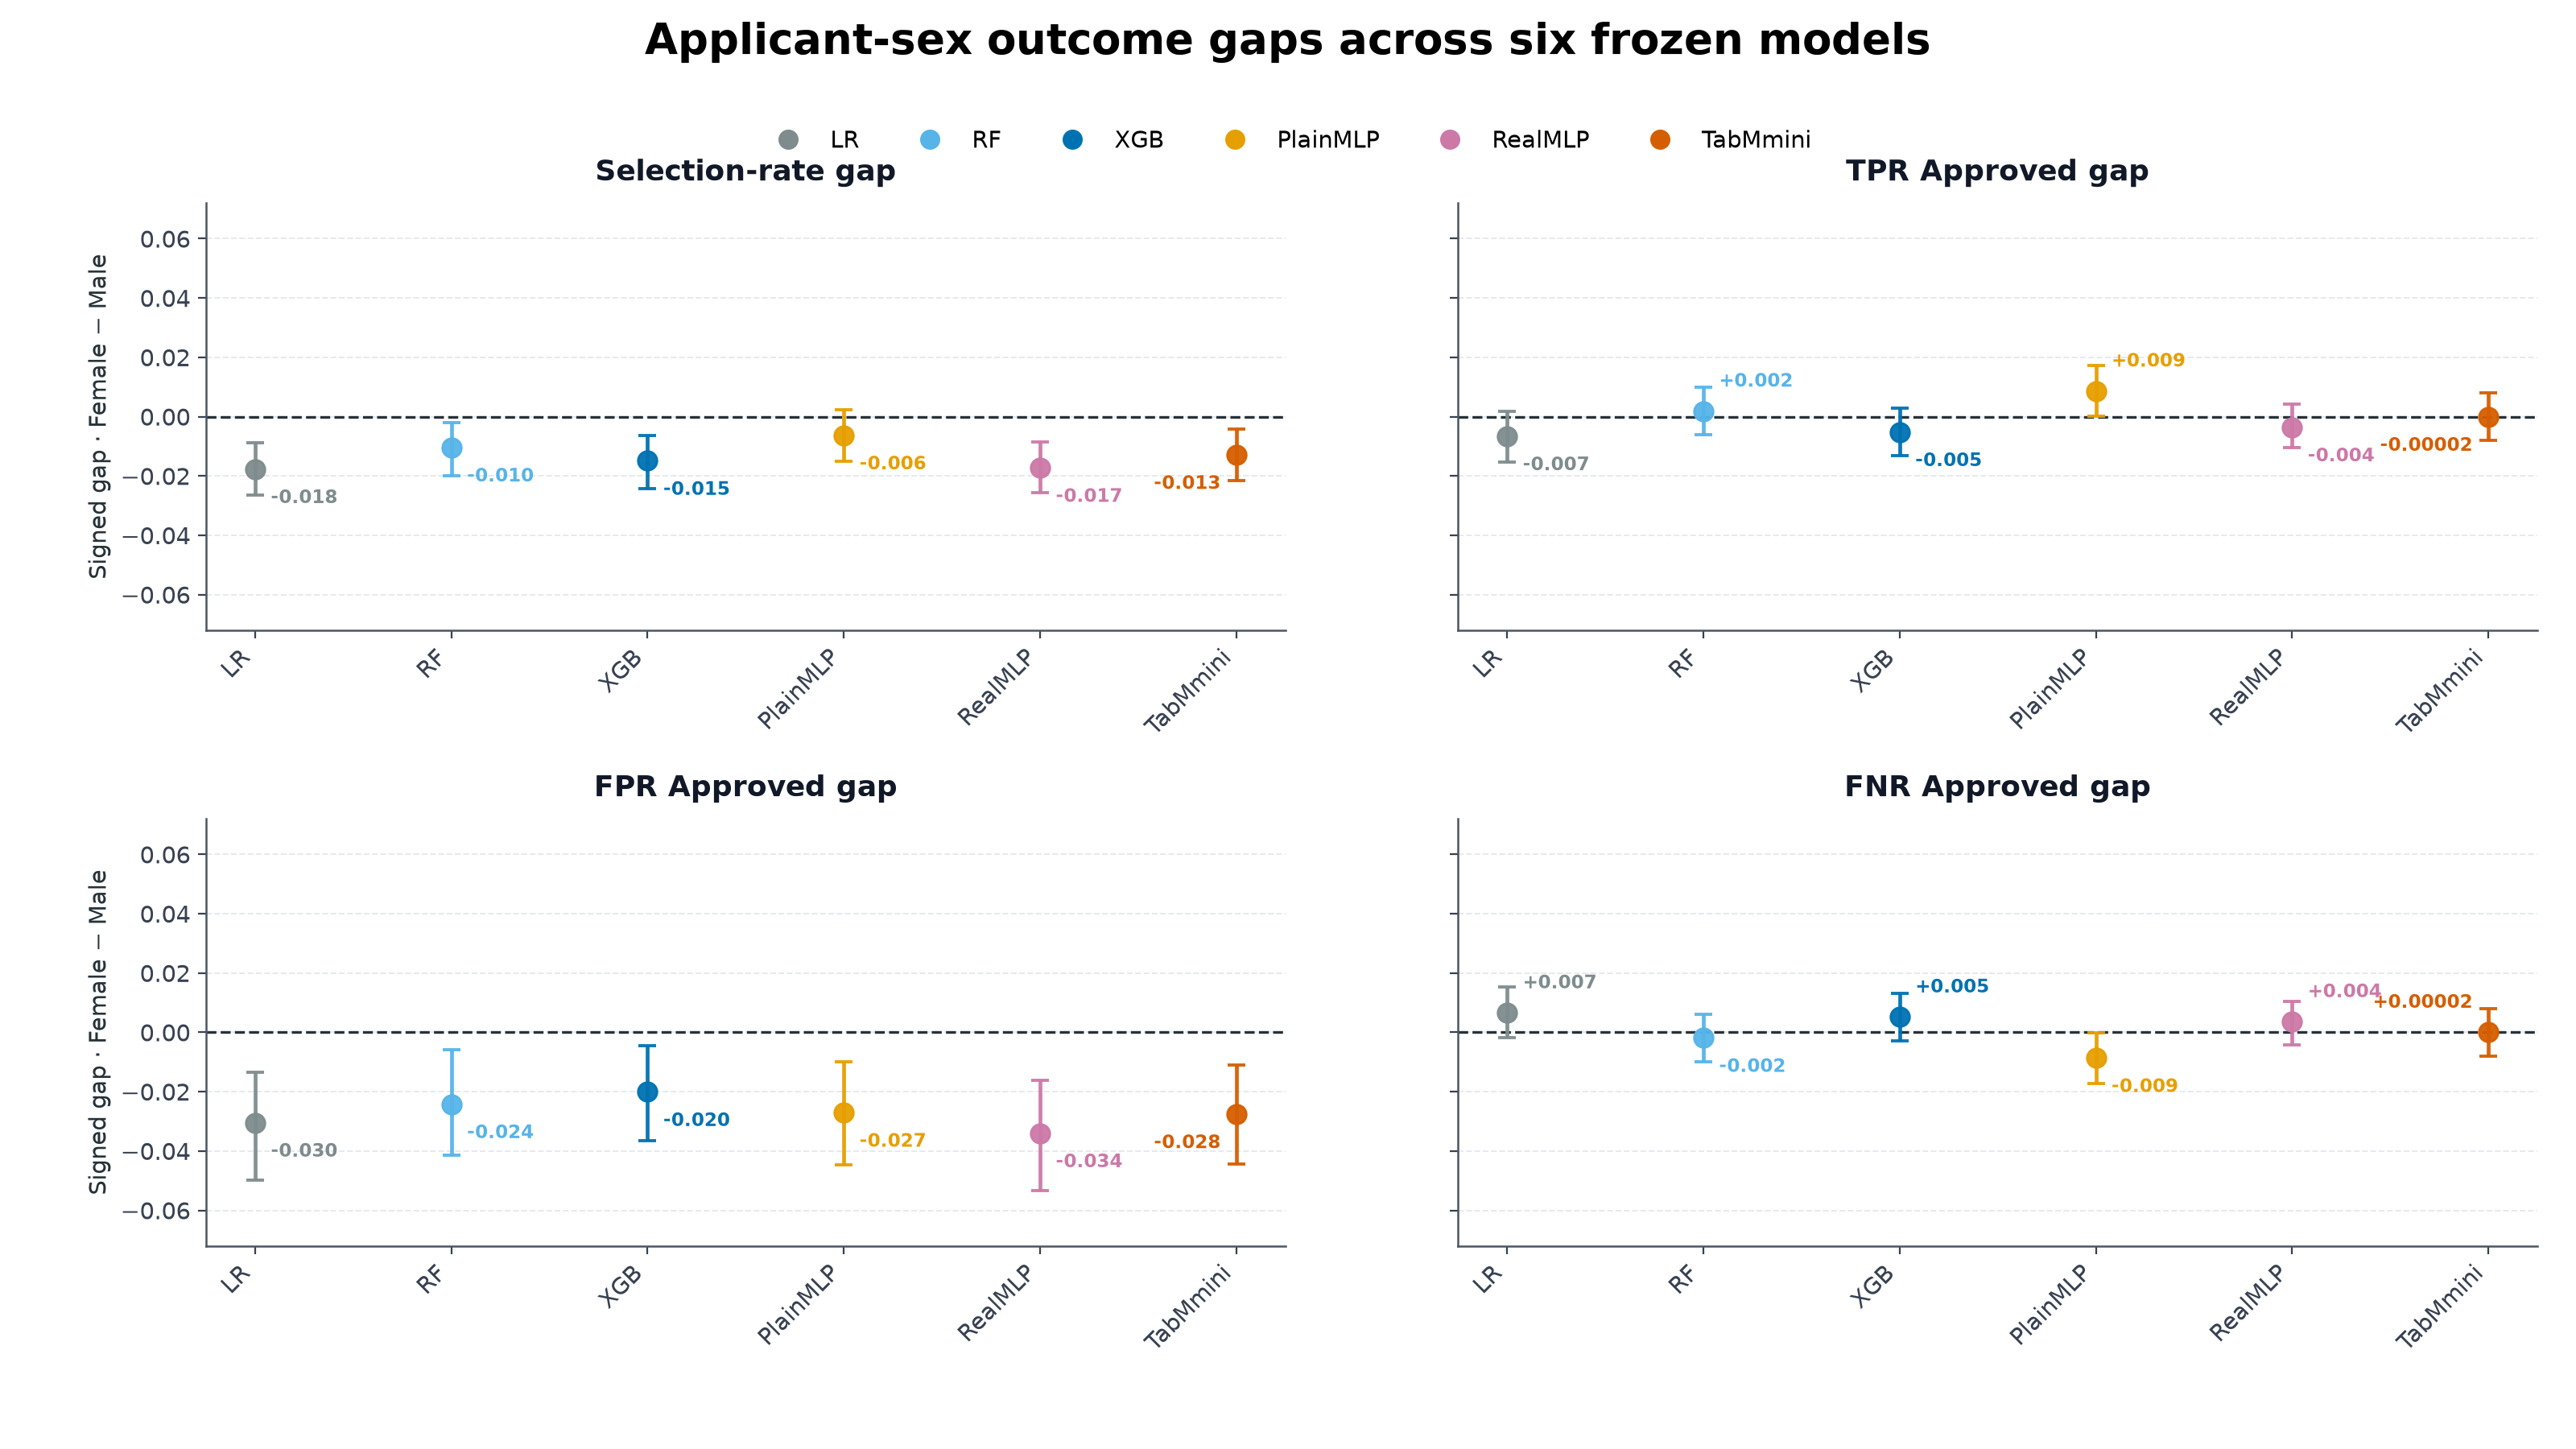

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
x = np.arange(len(MODEL_ORDER))
max_abs = float(np.nanmax(np.abs(rq3[['ci_lower', 'ci_upper']].to_numpy(dtype=float))))
y_limit = max_abs * 1.35

def format_signed_gap(value):
    return f'{value:+.5f}' if abs(value) < 0.001 else f'{value:+.3f}'

for ax, (metric, title) in zip(axes.flat, RQ3_METRICS):
    block = rq3.loc[rq3['metric'].eq(metric)].set_index('model').loc[MODEL_ORDER]
    values = block['point_estimate'].to_numpy(dtype=float)
    lower = block['ci_lower'].to_numpy(dtype=float)
    upper = block['ci_upper'].to_numpy(dtype=float)
    for model_index, model_key in enumerate(MODEL_ORDER):
        error = np.array([[values[model_index] - lower[model_index]],
                          [upper[model_index] - values[model_index]]])
        ax.errorbar(
            model_index, values[model_index], yerr=error, fmt='o',
            markersize=8.5, color=MODEL_COLORS[model_key], ecolor=MODEL_COLORS[model_key],
            elinewidth=1.7, capsize=4, capthick=1.4, alpha=0.95, zorder=3,
        )
        vertical_offset = 9 if values[model_index] >= 0 else -9
        vertical_alignment = 'bottom' if values[model_index] >= 0 else 'top'
        is_last_model = model_index == len(MODEL_ORDER) - 1
        horizontal_offset = -7 if is_last_model else 7
        horizontal_alignment = 'right' if is_last_model else 'left'
        ax.annotate(
            format_signed_gap(values[model_index]),
            xy=(model_index, values[model_index]),
            xytext=(horizontal_offset, vertical_offset),
            textcoords='offset points',
            ha=horizontal_alignment, va=vertical_alignment,
            fontsize=8.2, fontweight='bold', color=MODEL_COLORS[model_key],
        )
    ax.axhline(
    y=0,
    color='#263238',
    linewidth=1.2,
    linestyle='--',
    zorder=1,
)
    ax.set_title(title, fontsize=13, pad=10)
    ax.set_ylim(-y_limit, y_limit)
    ax.set_xticks(x, [MODEL_LABELS[model] for model in MODEL_ORDER], rotation=45, ha='right')
    ax.tick_params(axis='x', labelbottom=True)
    polish_axis(ax, grid_axis='y')

axes[0, 0].set_ylabel('Signed gap · Female − Male')
axes[1, 0].set_ylabel('Signed gap · Female − Male')
model_handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=MODEL_COLORS[model],
           markeredgecolor=MODEL_COLORS[model], markersize=8, label=MODEL_LABELS[model])
    for model in MODEL_ORDER
]
fig.legend(handles=model_handles, loc='upper center', bbox_to_anchor=(0.5, 0.925),
           ncol=6, frameon=False, fontsize=10.5)
fig.suptitle('Applicant-sex outcome gaps across six frozen models',
             fontsize=19, fontweight='bold', y=0.985)
fig.subplots_adjust(left=0.08, right=0.985, top=0.86, bottom=0.14, wspace=0.16, hspace=0.44)
rq3_outputs = export_prototype(fig, 'rq3_sex_gap_ci')


## 5. Prototype output summary

The approved Stage 2 prototypes are retained unchanged in `prototypes/`. Stage 3 below exports the complete slide and report profiles from the same accepted source tables.

In [8]:
prototype_files = sorted(path.relative_to(REPO_ROOT) for path in PROTOTYPE_DIR.glob('*') if path.is_file())
assert len(prototype_files) == 8, f'Expected eight prototype exports, found {len(prototype_files)}'
pd.DataFrame({'prototype_file': [str(path) for path in prototype_files]})


,prototype_file
0,reports\figures\publication\prototypes\rq1_per...
1,reports\figures\publication\prototypes\rq1_per...
2,reports\figures\publication\prototypes\rq2_gsv...
3,reports\figures\publication\prototypes\rq2_gsv...
4,reports\figures\publication\prototypes\rq2_gsv...
5,reports\figures\publication\prototypes\rq2_gsv...
6,reports\figures\publication\prototypes\rq3_sex...
7,reports\figures\publication\prototypes\rq3_sex...


## 6. Stage 3 - complete publication figure set

The cells below only read accepted reporting CSV/JSON artifacts. No model is loaded, no prediction is generated, and no bootstrap replicate is recomputed. Each figure is exported to both `slide/` and `report/` as PNG and SVG.

In [9]:
import json
from matplotlib.colors import Normalize

PROFILES = {
    'slide': {'dpi': 200, 'title': 19, 'panel': 13, 'tick': 10, 'label': 10.5},
    'report': {'dpi': 300, 'title': 14, 'panel': 11, 'tick': 9, 'label': 9.5},
}

def export_figure(fig, stem, profile):
    target = SLIDE_DIR if profile == 'slide' else REPORT_DIR
    png_path = target / f'{stem}.png'
    svg_path = target / f'{stem}.svg'
    save_figure_file(fig, png_path, dpi=PROFILES[profile]['dpi'])
    save_figure_file(fig, svg_path)
    return [png_path, svg_path]

def finish_figure(fig, stem, profile, show_slide=True):
    paths = export_figure(fig, stem, profile)
    if profile == 'slide' and show_slide:
        display(Image(filename=str(paths[0])))
    plt.close(fig)
    return paths

def ordered_metric(frame, metric, model_column='model_key'):
    return frame.loc[frame['metric'].eq(metric)].set_index(model_column).loc[MODEL_ORDER]

def model_legend(fontsize=10):
    return [Line2D([0], [0], marker='o', color='none', markerfacecolor=MODEL_COLORS[m],
                   markeredgecolor=MODEL_COLORS[m], markersize=8, label=MODEL_LABELS[m])
            for m in MODEL_ORDER]

rq1_all_frames = []
calibration_frames = []
confusion_frames = []
for model_key, metric_path in RQ1_FILES.items():
    metrics = pd.read_csv(metric_path)
    metrics['model_key'] = model_key
    rq1_all_frames.append(metrics)
    calibration = pd.read_csv(metric_path.parent / 'calibration_curve.csv')
    calibration['model_key'] = model_key
    calibration_frames.append(calibration)
    confusion = pd.read_csv(metric_path.parent / 'confusion_matrix.csv')
    confusion['model_key'] = model_key
    confusion_frames.append(confusion)
rq1_all = pd.concat(rq1_all_frames, ignore_index=True)
calibration = pd.concat(calibration_frames, ignore_index=True)
confusion = pd.concat(confusion_frames, ignore_index=True)

rq2_bootstrap = pd.concat([pd.read_csv(RQ2_ROOT / 'models' / m / 'bootstrap.csv') for m in MODEL_ORDER], ignore_index=True)
rq2_stability = pd.read_csv(RQ2_ROOT / 'cross_model_stability.csv')
rq2_runtime = pd.read_csv(RQ2_ROOT / 'runtime.csv')

RQ3_ROOT = RQ3_SOURCE.parent
rq3_status = json.loads((RQ3_ROOT / 'status.json').read_text(encoding='utf-8'))
rq3_gap_metrics = pd.read_csv(RQ3_ROOT / 'gap_metrics.csv')
rq3_group_metrics = pd.read_csv(RQ3_ROOT / 'group_metrics.csv')

required_rq1 = {metric for metric, _ in RQ1_METRICS} | {'brier_score_approved', 'recall_approved'}
assert set(MODEL_ORDER) == set(rq1_all['model_key'])
assert required_rq1.issubset(set(rq1_all['metric']))
assert rq1_all.loc[rq1_all['metric'].isin(required_rq1)].groupby(['model_key', 'metric']).size().eq(1).all()
assert (rq1_all['ci_low'] <= rq1_all['estimate']).all() and (rq1_all['estimate'] <= rq1_all['ci_high']).all()
assert calibration.groupby('model_key').size().between(9, 10).all()  # Stored non-empty quantile bins; RF has nine.
assert calibration[['mean_p_approved', 'observed_approval_rate']].apply(lambda s: s.between(0, 1).all()).all()
assert confusion.groupby('model_key').size().eq(4).all()
assert len(rq2) == 144 and len(rq2_bootstrap) == 24 and len(rq2_stability) == 60 and len(rq2_runtime) == 6
assert rq2_bootstrap['ci_available'].astype(str).str.lower().eq('true').all()
assert (rq2_bootstrap['ci_lower'] <= rq2_bootstrap['point_estimate']).all()
assert (rq2_bootstrap['point_estimate'] <= rq2_bootstrap['ci_upper']).all()
assert rq3_status['status'] == 'PASS' and set(rq3_status['model_status'].values()) == {'PASS'}
assert set(MODEL_ORDER) == set(rq3_all['model'])
defined_rq3 = rq3_all.loc[rq3_all['ci_status'].eq('defined')]
assert (defined_rq3['ci_lower'] <= defined_rq3['ci_upper']).all()

stage3_outputs = []
print('Stage 3 source validation: PASS')


Stage 3 source validation: PASS


## 7. RQ1 final figures

Brier Score is isolated because lower is better. Recall Approved is also isolated so it does not dilute the six-metric Denied-focused overview. Calibration curves and confusion matrices use only the saved reporting tables.

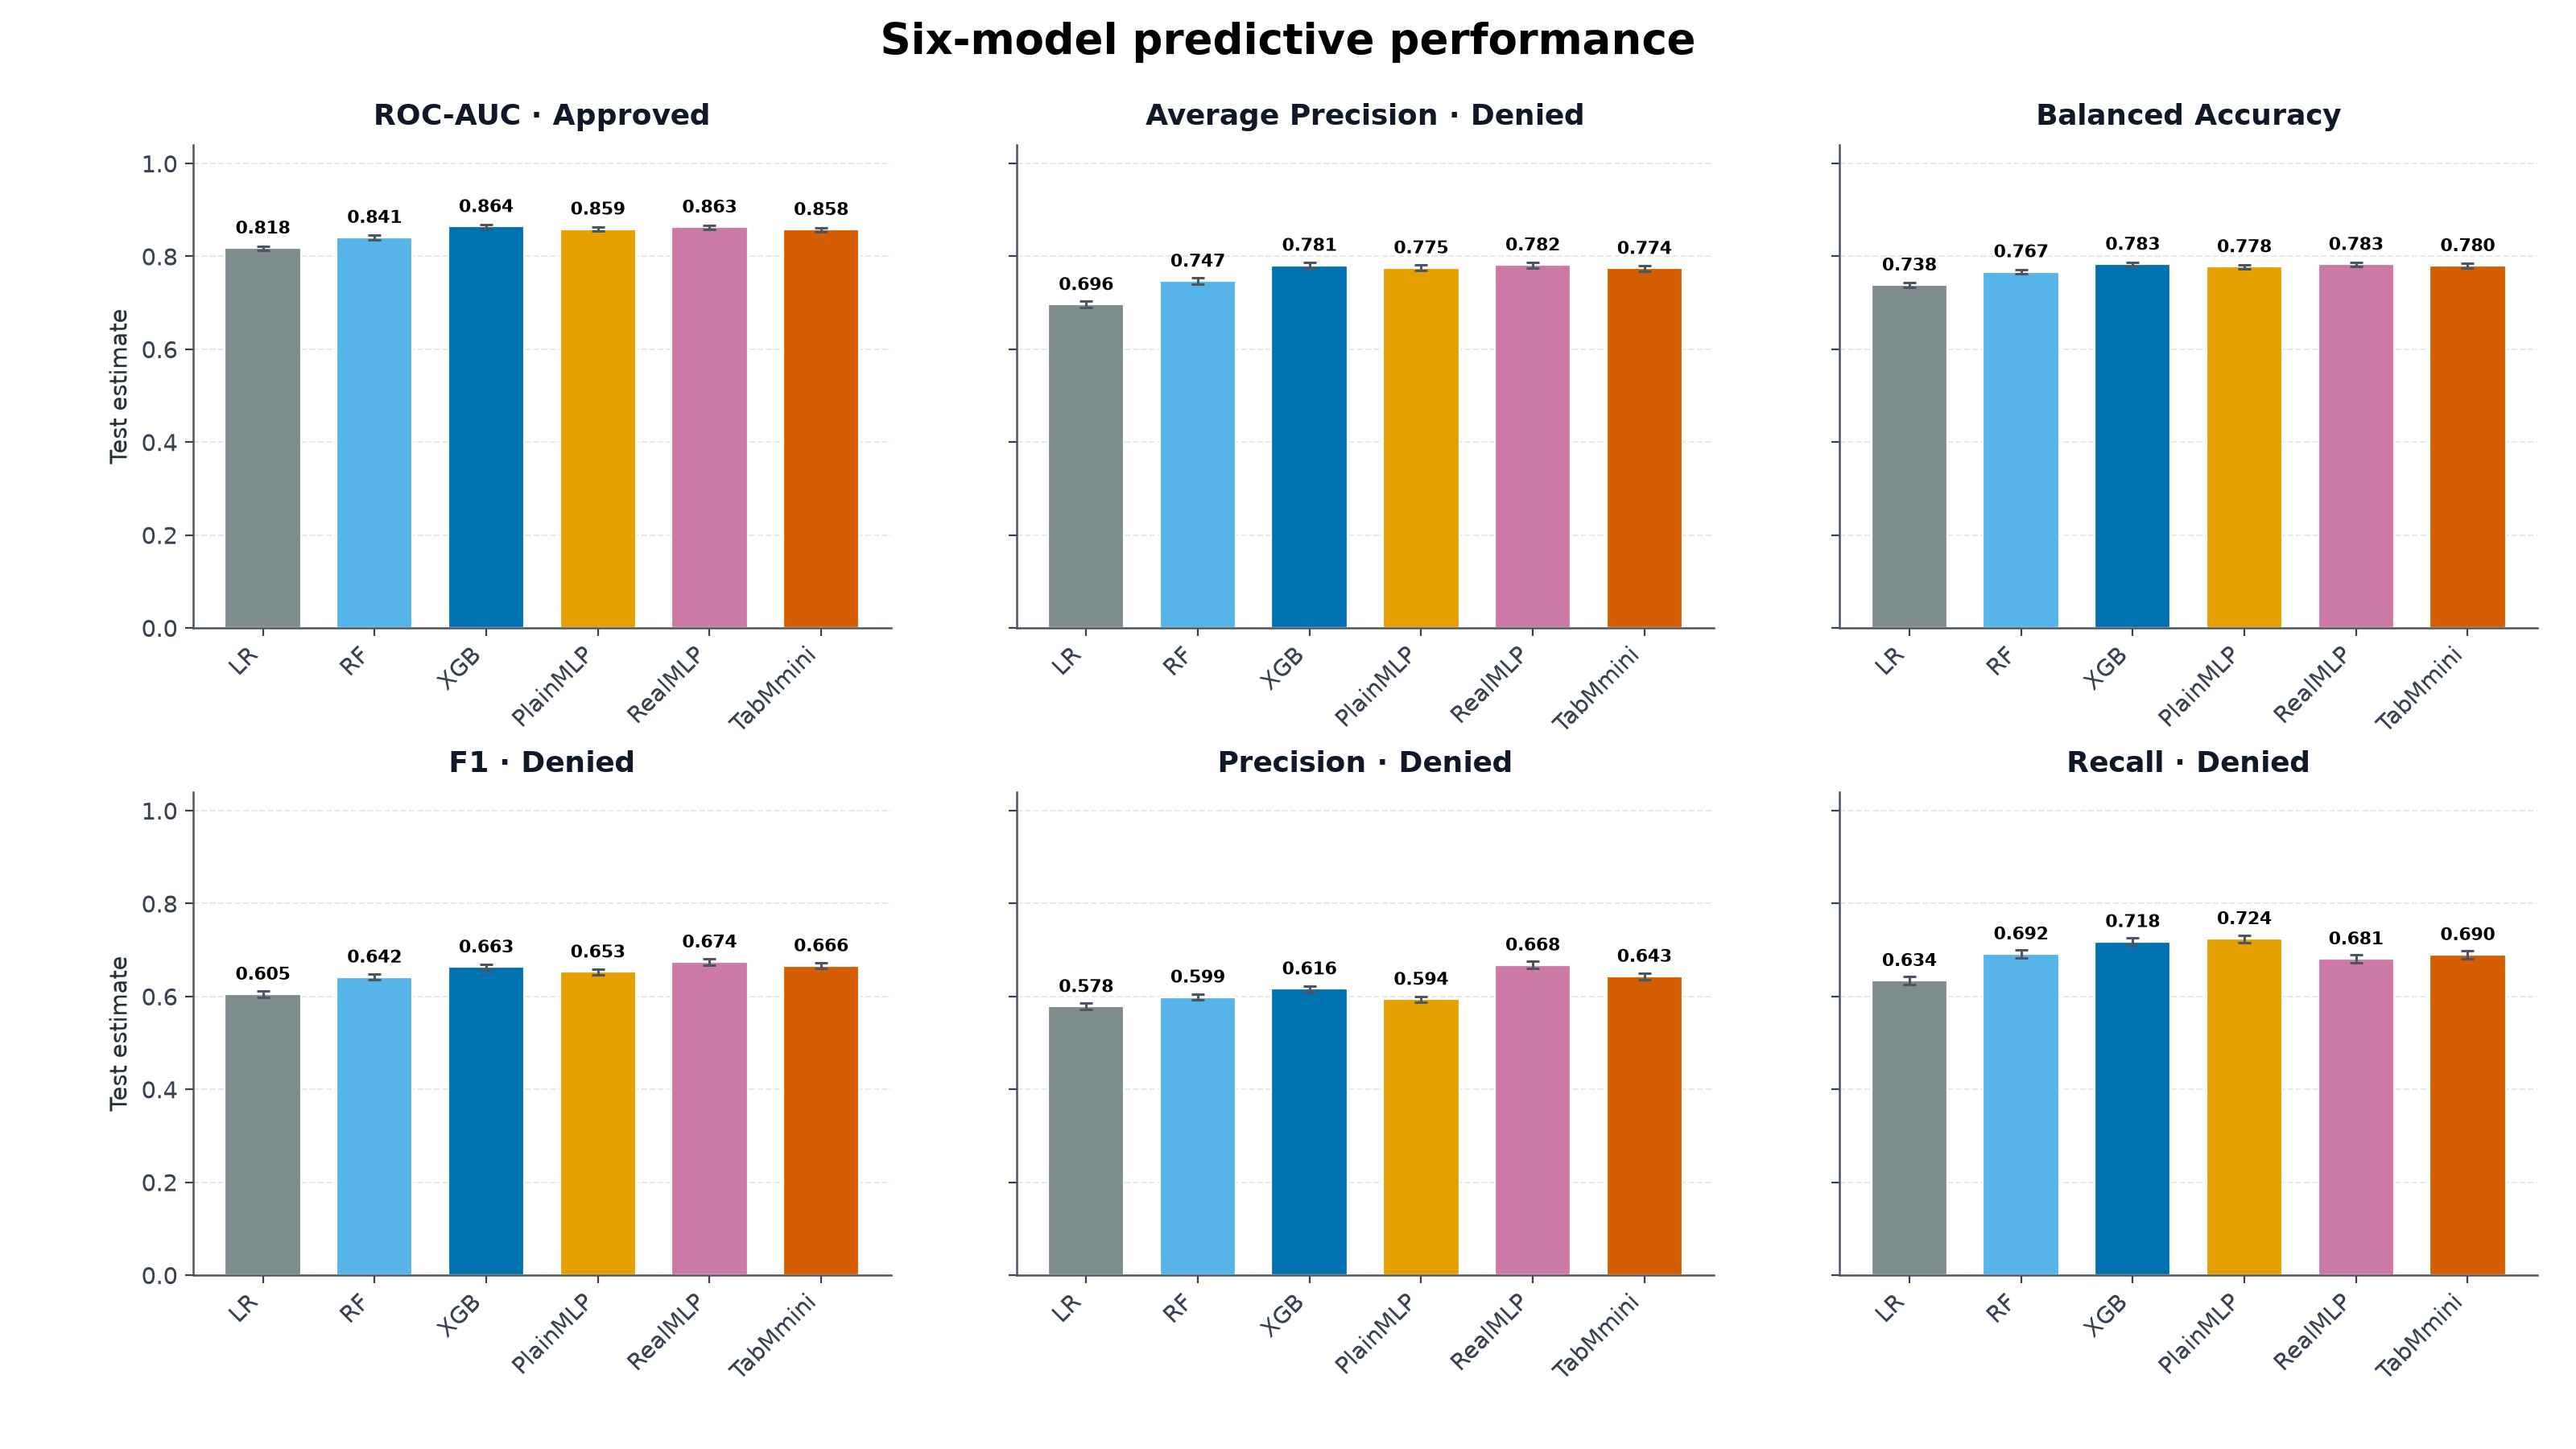

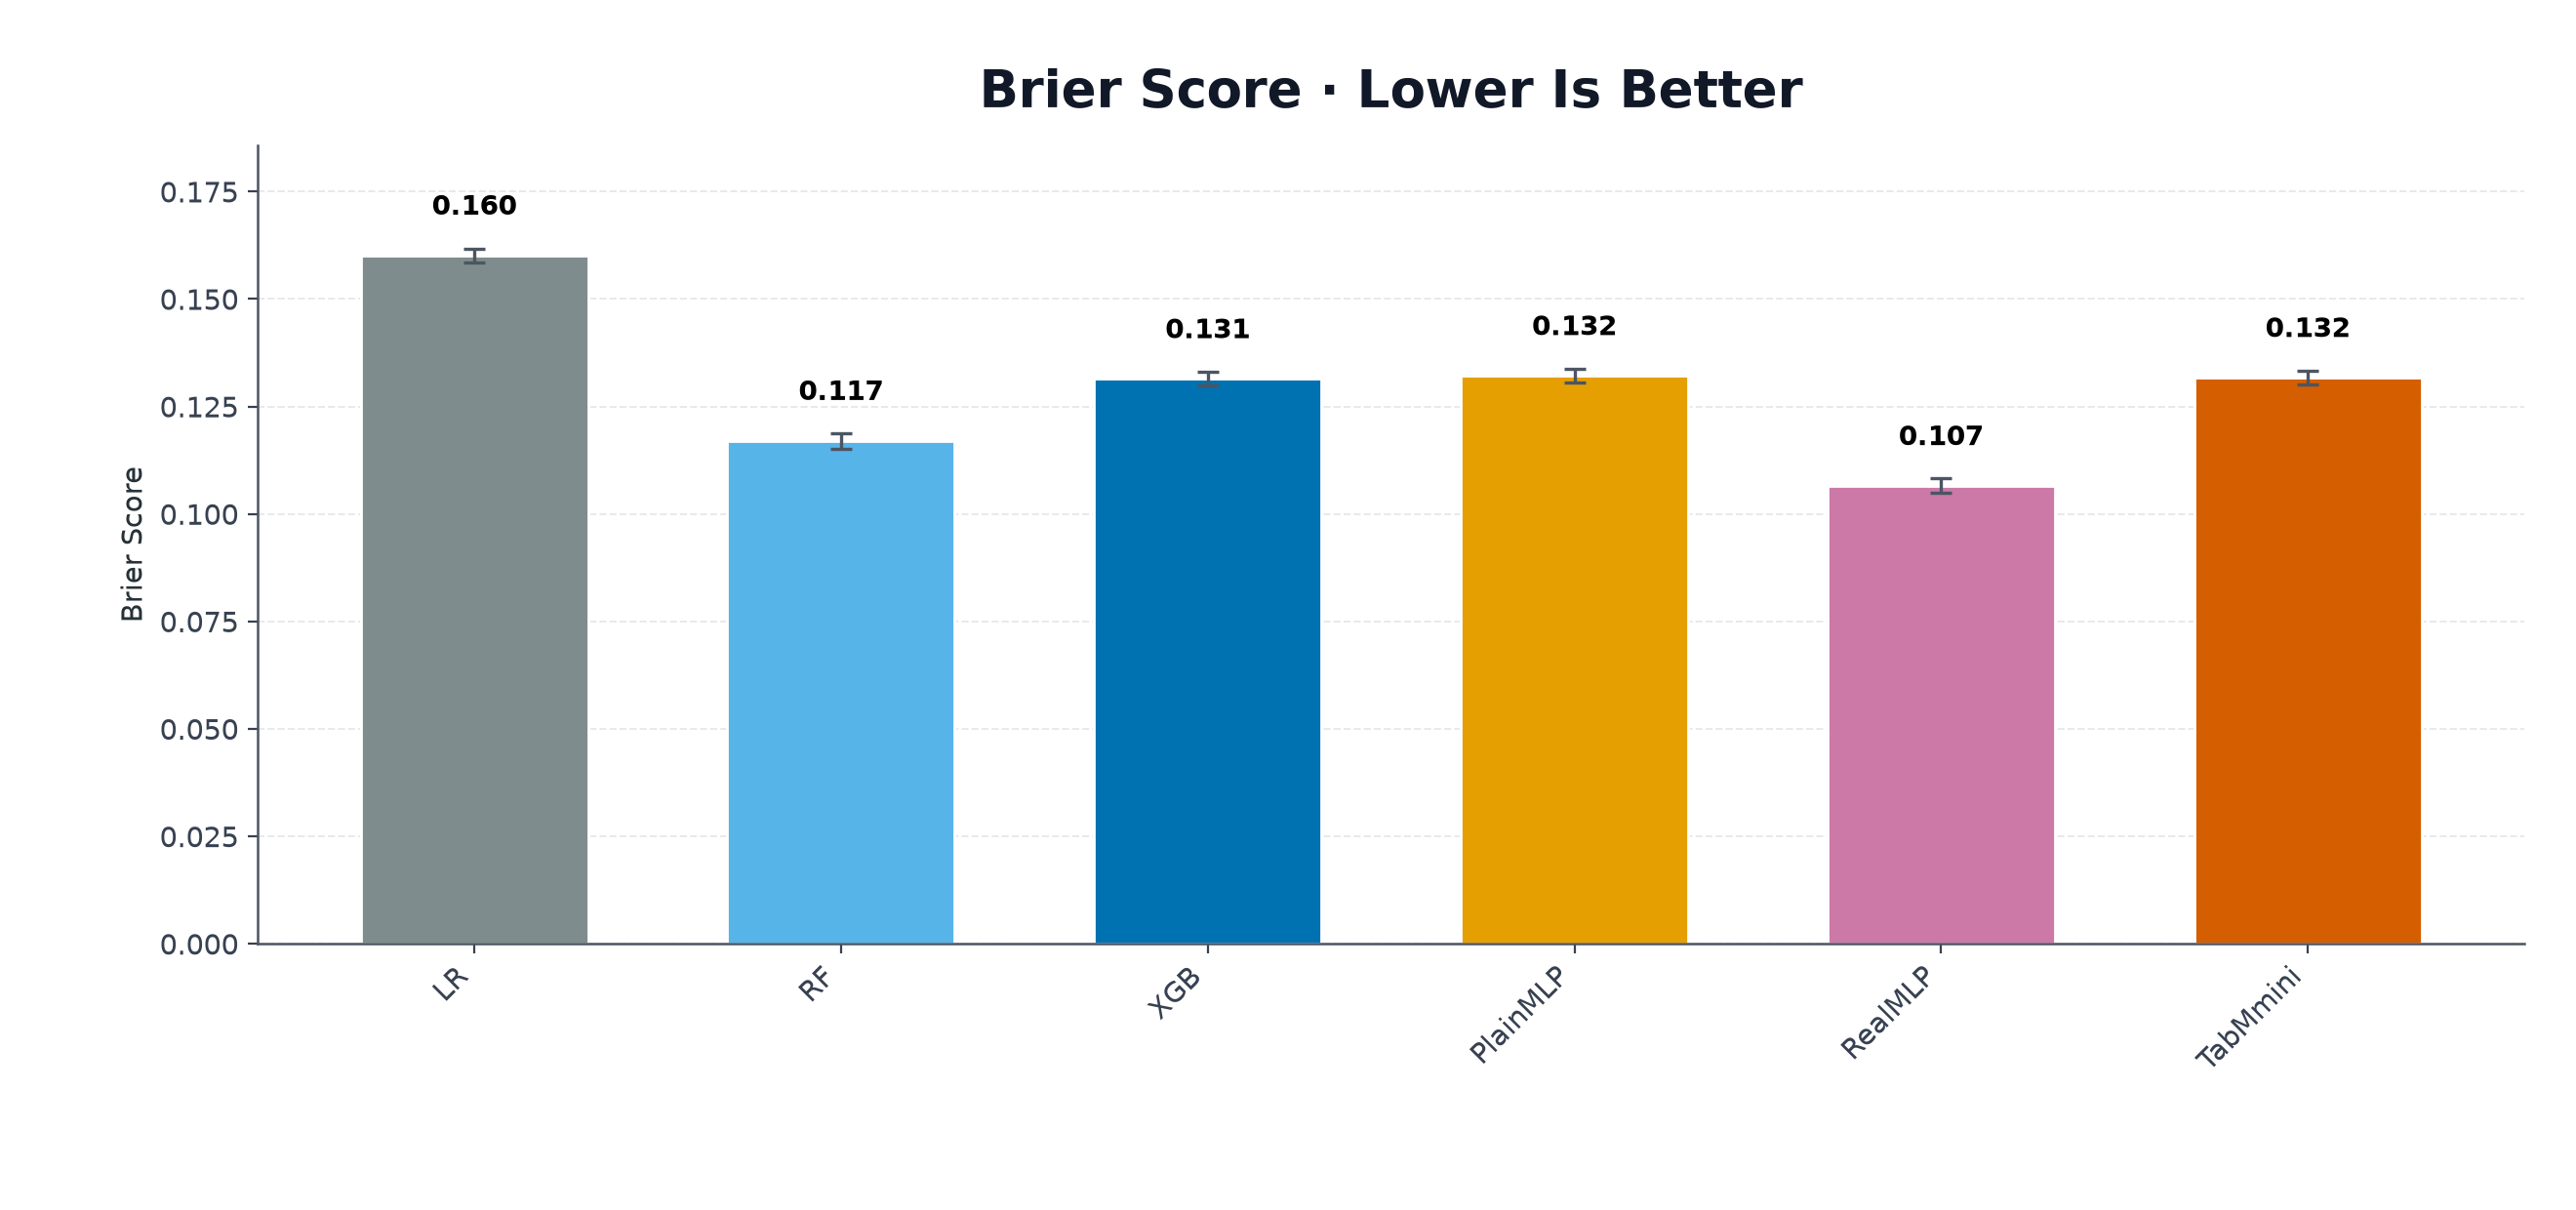

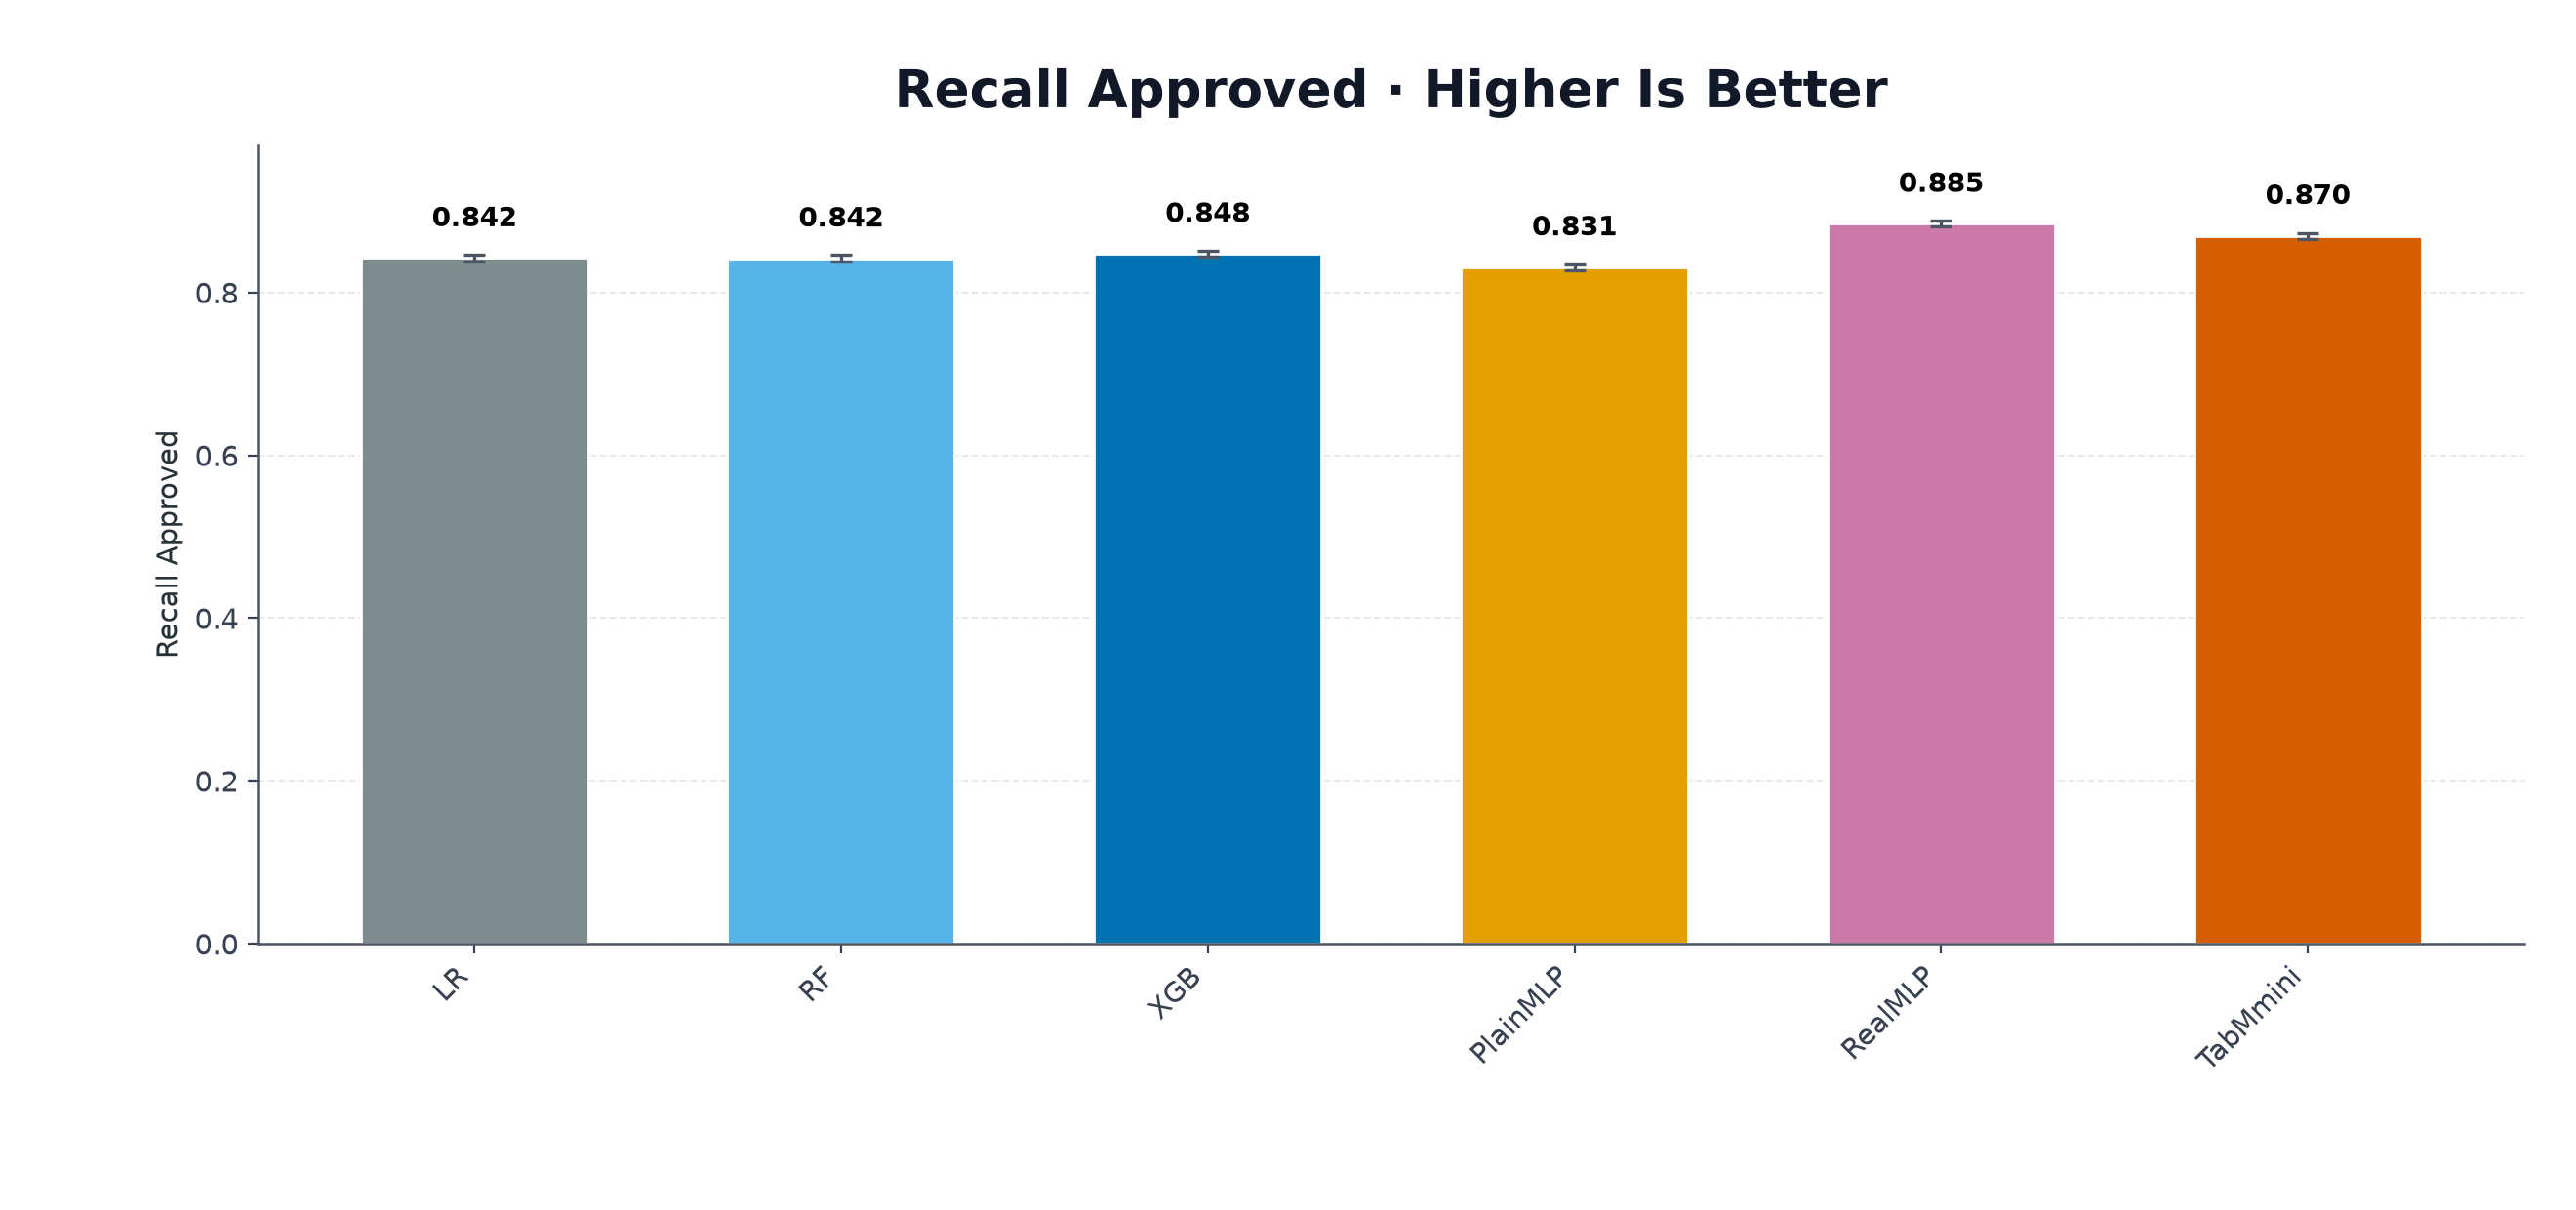

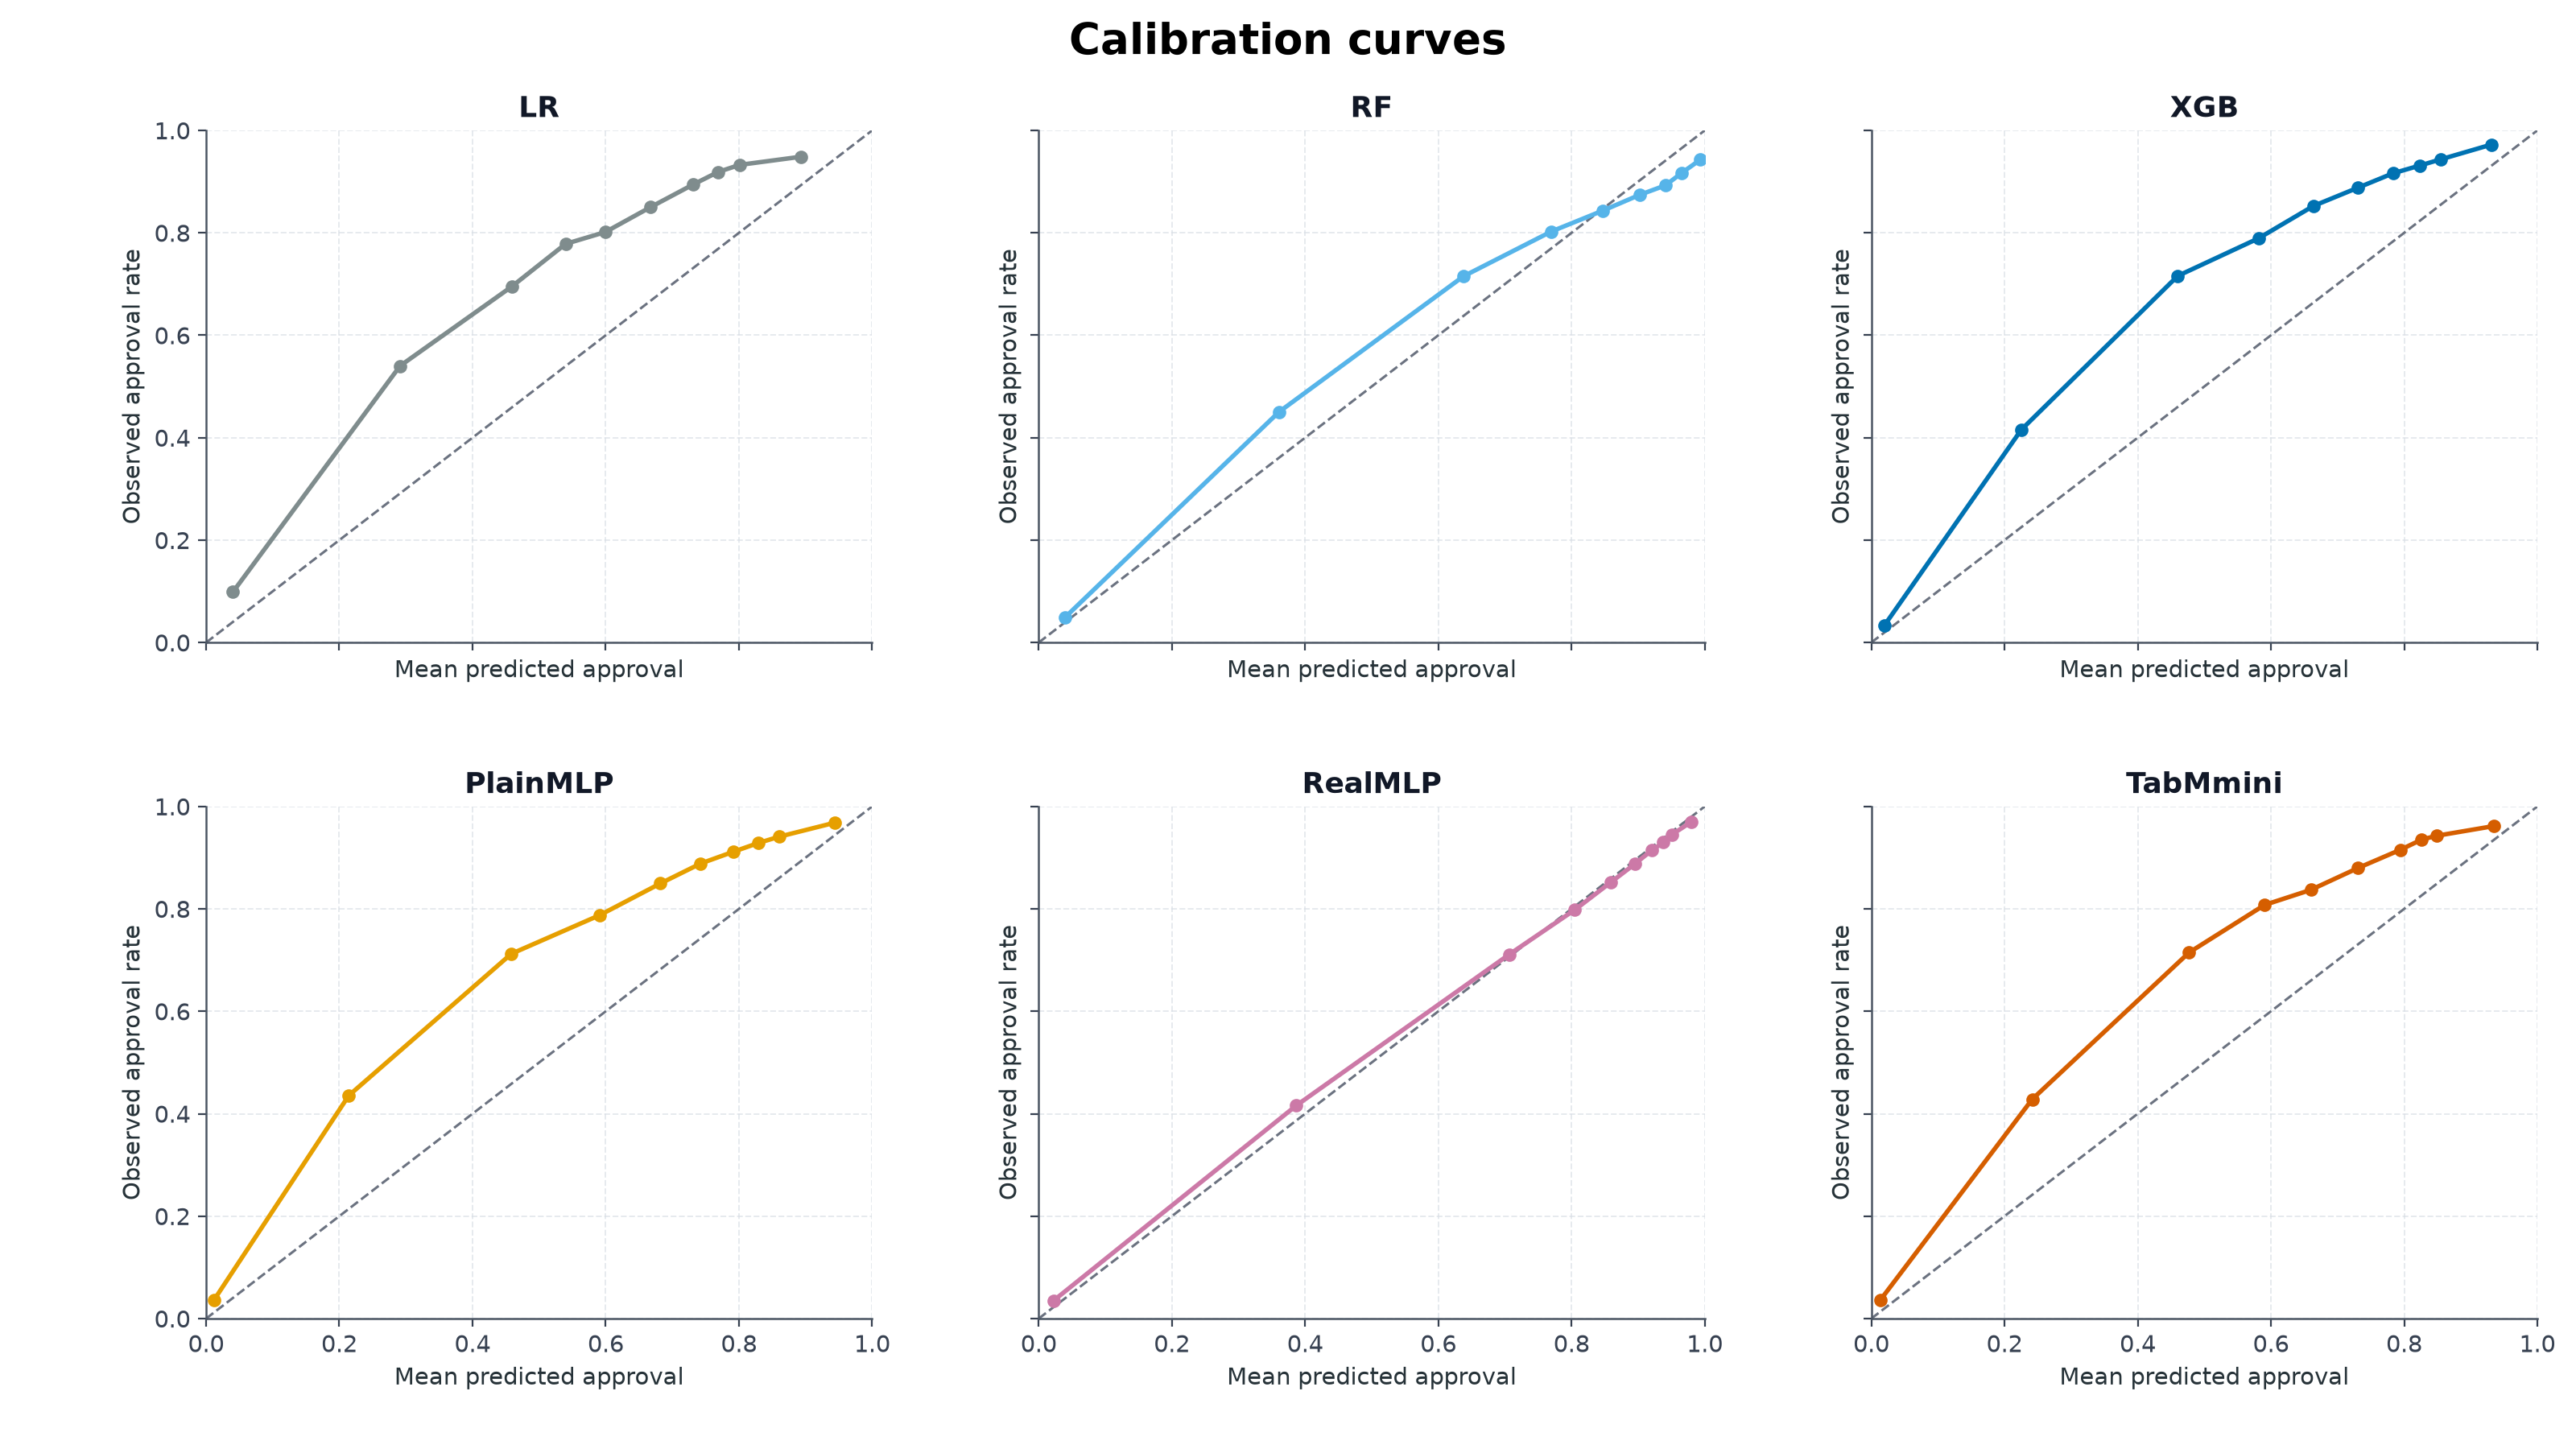

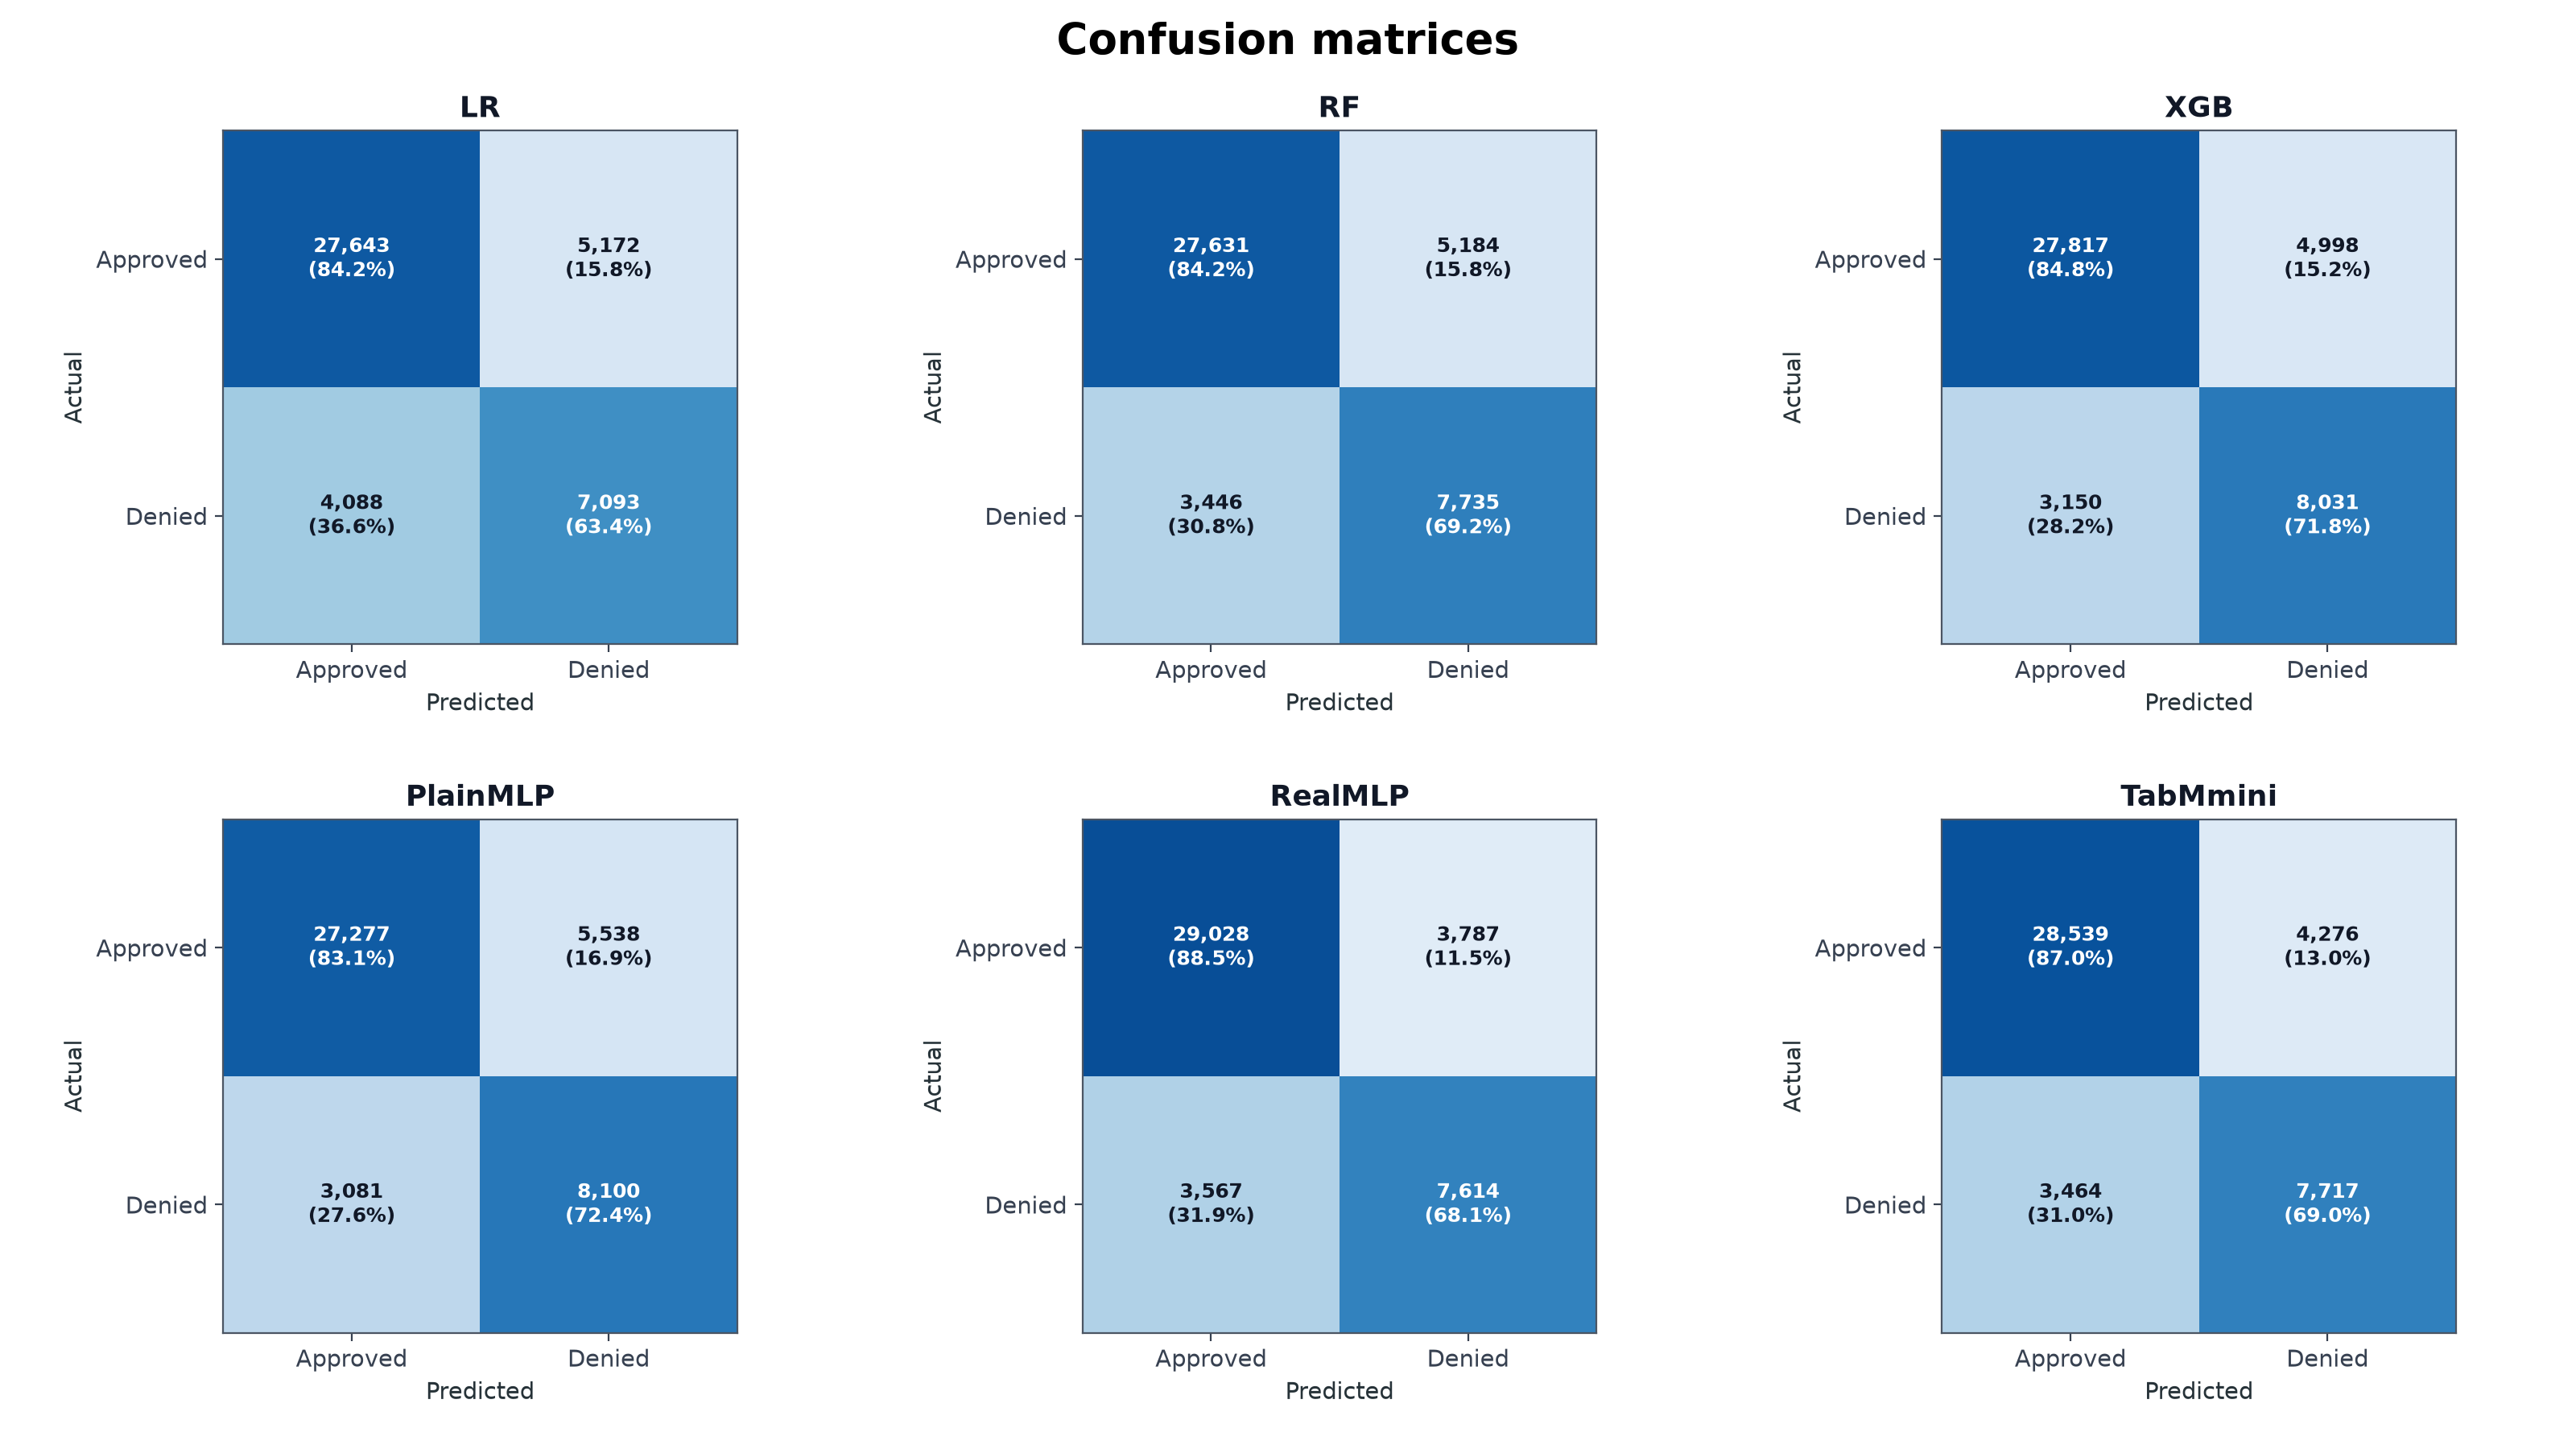

In [10]:
def plot_rq1_overview(profile):
    is_slide = profile == 'slide'
    figsize = (16, 9) if is_slide else (7.2, 11.5)
    shape = (2, 3) if is_slide else (3, 2)
    fig, axes = plt.subplots(*shape, figsize=figsize, sharey=True)
    x = np.arange(len(MODEL_ORDER))
    for ax, (metric, title) in zip(axes.flat, RQ1_METRICS):
        block = ordered_metric(rq1_all, metric)
        values = block['estimate'].to_numpy(float)
        errors = np.vstack([values - block['ci_low'].to_numpy(float), block['ci_high'].to_numpy(float) - values])
        bars = ax.bar(x, values, width=0.68, color=[MODEL_COLORS[m] for m in MODEL_ORDER],
                      edgecolor='white', linewidth=0.8, yerr=errors, capsize=3,
                      error_kw={'ecolor': '#4B5563', 'elinewidth': 1.1, 'capthick': 1.1})
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, value + 0.022, f'{value:.3f}',
                    ha='center', va='bottom', fontsize=8 if is_slide else 9, fontweight='bold')
        ax.set_title(title, fontsize=PROFILES[profile]['panel'], pad=9)
        ax.set_xticks(x, [MODEL_LABELS[m] for m in MODEL_ORDER], rotation=45, ha='right')
        ax.set_ylim(0, 1.04); ax.set_yticks(np.arange(0, 1.01, 0.2)); polish_axis(ax, 'y')
    for ax in axes[:, 0]: ax.set_ylabel('Test estimate')
    fig.suptitle('Six-model predictive performance' if is_slide else 'Predictive performance (95% bootstrap CI)',
                 fontsize=PROFILES[profile]['title'], fontweight='bold', y=0.985)
    fig.subplots_adjust(left=0.075 if is_slide else 0.11, right=0.985, top=0.90 if is_slide else 0.93,
                        bottom=0.12 if is_slide else 0.07, wspace=0.18 if is_slide else 0.22, hspace=0.34 if is_slide else 0.64)
    return fig

def plot_single_rq1_metric(profile, metric, panel_title, figure_title, lower_is_better=False):
    is_slide = profile == 'slide'; fig, ax = plt.subplots(figsize=(13.2, 6.2) if is_slide else (7.2, 4.6))
    block = ordered_metric(rq1_all, metric); x = np.arange(len(MODEL_ORDER)); values = block['estimate'].to_numpy(float)
    errors = np.vstack([values-block['ci_low'].to_numpy(float), block['ci_high'].to_numpy(float)-values])
    bars = ax.bar(x, values, width=0.62, color=[MODEL_COLORS[m] for m in MODEL_ORDER], edgecolor='white',
                  yerr=errors, capsize=4, error_kw={'ecolor':'#4B5563','elinewidth':1.2,'capthick':1.2})
    margin = max(0.008, float(values.max()) * 0.035)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x()+bar.get_width()/2, value+margin, f'{value:.3f}', ha='center', va='bottom',
                fontsize=10 if is_slide else 9, fontweight='bold')
    ax.set_xticks(x, [MODEL_LABELS[m] for m in MODEL_ORDER], rotation=45, ha='right')
    ax.set_ylim(0, max(float(block['ci_high'].max()) + 3*margin, 0.05)); ax.set_ylabel(panel_title); polish_axis(ax, 'y')
    ax.set_title(figure_title + (' · Lower Is Better' if lower_is_better else ' · Higher Is Better'),
                 fontsize=PROFILES[profile]['title'], pad=14)
    fig.subplots_adjust(left=0.10 if is_slide else 0.13, right=0.98, top=0.88, bottom=0.22)
    return fig

def plot_calibration(profile):
    is_slide = profile == 'slide'; figsize=(16,9) if is_slide else (7.2,9.3); shape=(2,3) if is_slide else (3,2)
    fig, axes = plt.subplots(*shape, figsize=figsize, sharex=True, sharey=True)
    for ax, model in zip(axes.flat, MODEL_ORDER):
        block=calibration.loc[calibration['model_key'].eq(model)].sort_values('bin')
        ax.plot([0,1],[0,1], '--', color='#6B7280', linewidth=1.1, label='Perfect calibration')
        ax.plot(block['mean_p_approved'], block['observed_approval_rate'], '-o', color=MODEL_COLORS[model],
                linewidth=2, markersize=5)
        ax.set_title(MODEL_LABELS[model], fontsize=PROFILES[profile]['panel']); ax.set_xlim(0,1); ax.set_ylim(0,1)
        ax.set_xlabel('Mean predicted approval'); ax.set_ylabel('Observed approval rate'); polish_axis(ax, 'both')
    fig.suptitle('Calibration curves' if is_slide else 'Decile calibration curves on the held-out Test set',
                 fontsize=PROFILES[profile]['title'], fontweight='bold', y=0.985)
    fig.subplots_adjust(left=0.08 if is_slide else 0.12, right=0.985, top=0.91, bottom=0.09, wspace=0.25, hspace=0.32)
    return fig

def plot_confusion(profile):
    is_slide=profile=='slide'; figsize=(16,9) if is_slide else (7.2,9.3); shape=(2,3) if is_slide else (3,2)
    fig, axes=plt.subplots(*shape, figsize=figsize)
    for ax, model in zip(axes.flat, MODEL_ORDER):
        block=confusion.loc[confusion['model_key'].eq(model)]
        matrix=block.pivot(index='actual_class', columns='predicted_class', values='count').reindex(index=['approved','denied'], columns=['approved','denied'])
        values=matrix.to_numpy(float); shares=values/values.sum(axis=1, keepdims=True)
        image=ax.imshow(shares, vmin=0, vmax=1, cmap='Blues')
        for i in range(2):
            for j in range(2):
                ax.text(j,i,f'{int(values[i,j]):,}\n({shares[i,j]:.1%})',ha='center',va='center',
                        fontsize=9 if is_slide else 9,color='white' if shares[i,j] > 0.55 else '#111827',fontweight='bold')
        ax.set_xticks([0,1],['Approved','Denied']); ax.set_yticks([0,1],['Approved','Denied'])
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(MODEL_LABELS[model],fontsize=PROFILES[profile]['panel']); ax.grid(False)
    fig.suptitle('Confusion matrices' if is_slide else 'Test-set confusion matrices (count and row share)',
                 fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.06 if is_slide else 0.10,right=0.98,top=0.91,bottom=0.08,wspace=0.32,hspace=0.34)
    return fig

for profile in PROFILES:
    stage3_outputs += finish_figure(plot_rq1_overview(profile), 'rq1_performance_overview', profile)
    stage3_outputs += finish_figure(plot_single_rq1_metric(profile,'brier_score_approved','Brier Score','Brier Score',True), 'rq1_brier_score', profile)
    stage3_outputs += finish_figure(plot_single_rq1_metric(profile,'recall_approved','Recall Approved','Recall Approved'), 'rq1_recall_approved', profile)
    stage3_outputs += finish_figure(plot_calibration(profile), 'rq1_calibration_curves', profile)
    stage3_outputs += finish_figure(plot_confusion(profile), 'rq1_confusion_matrices_appendix', profile)


## 8. RQ2 final figures

The importance charts retain the approved split into classical and neural model groups for readability. Rank heatmaps, agreement intervals, rank dispersion, and runtime use the accepted production CSVs without recalculation.

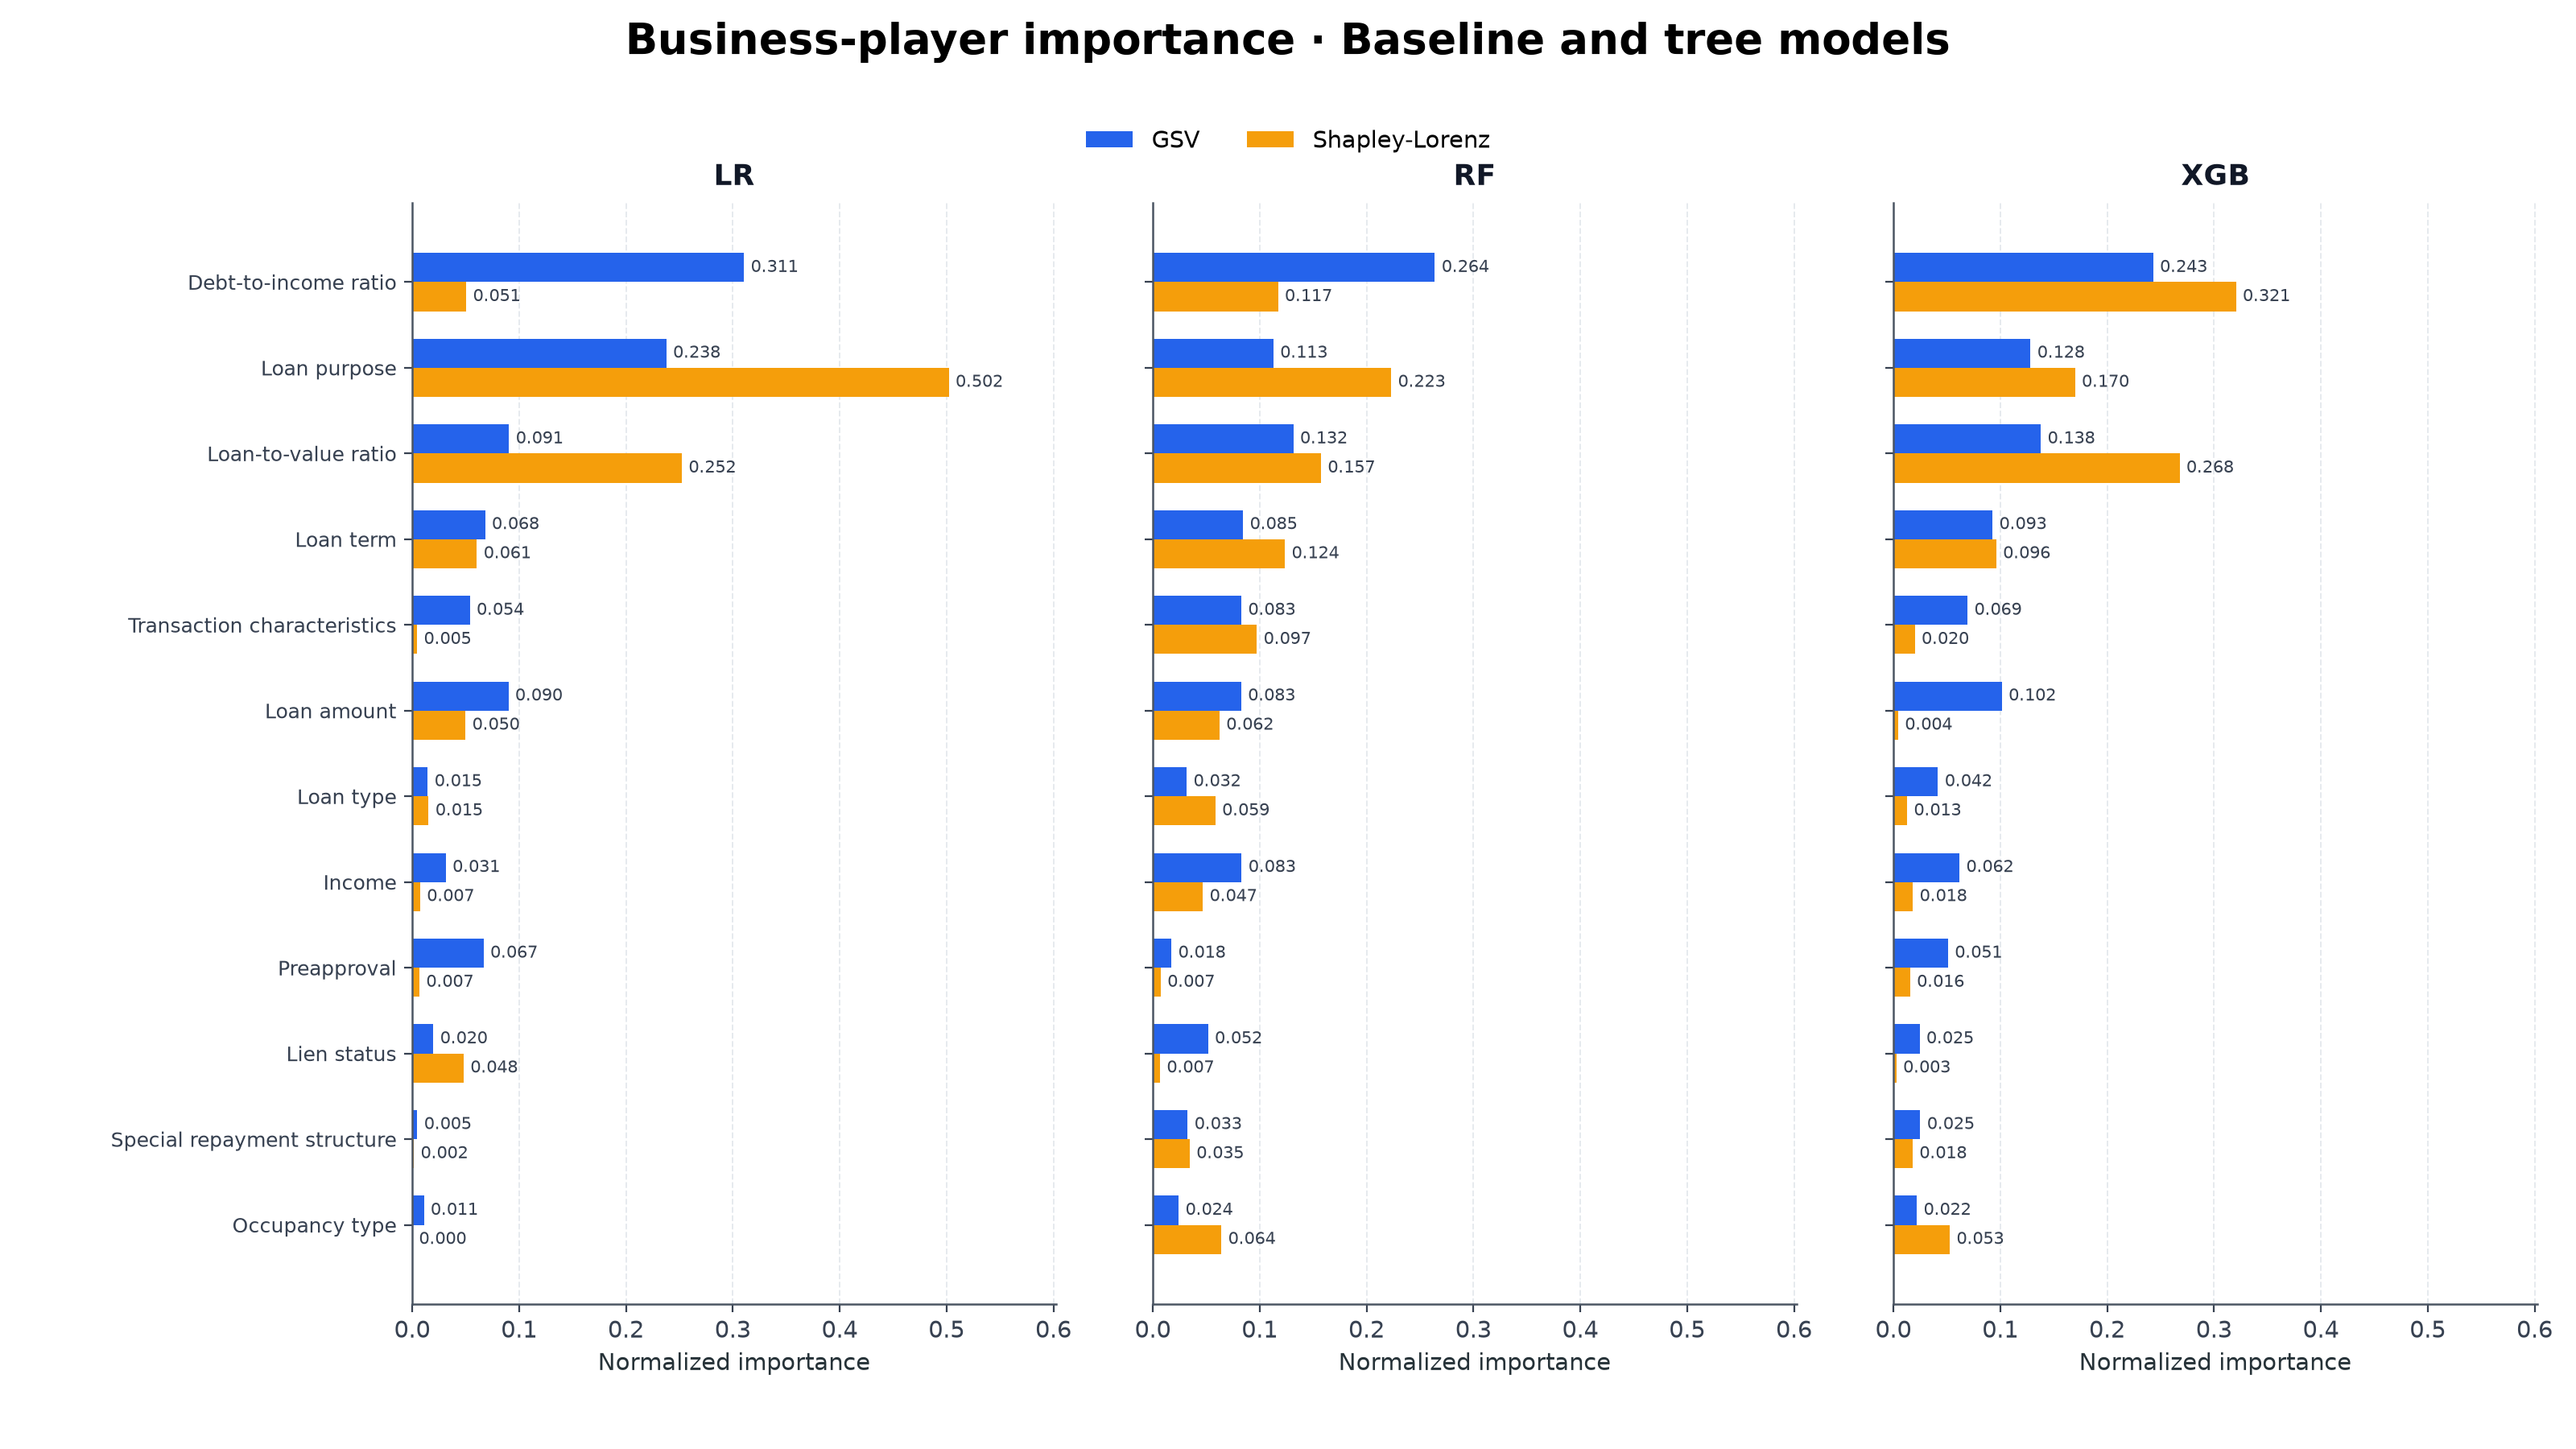

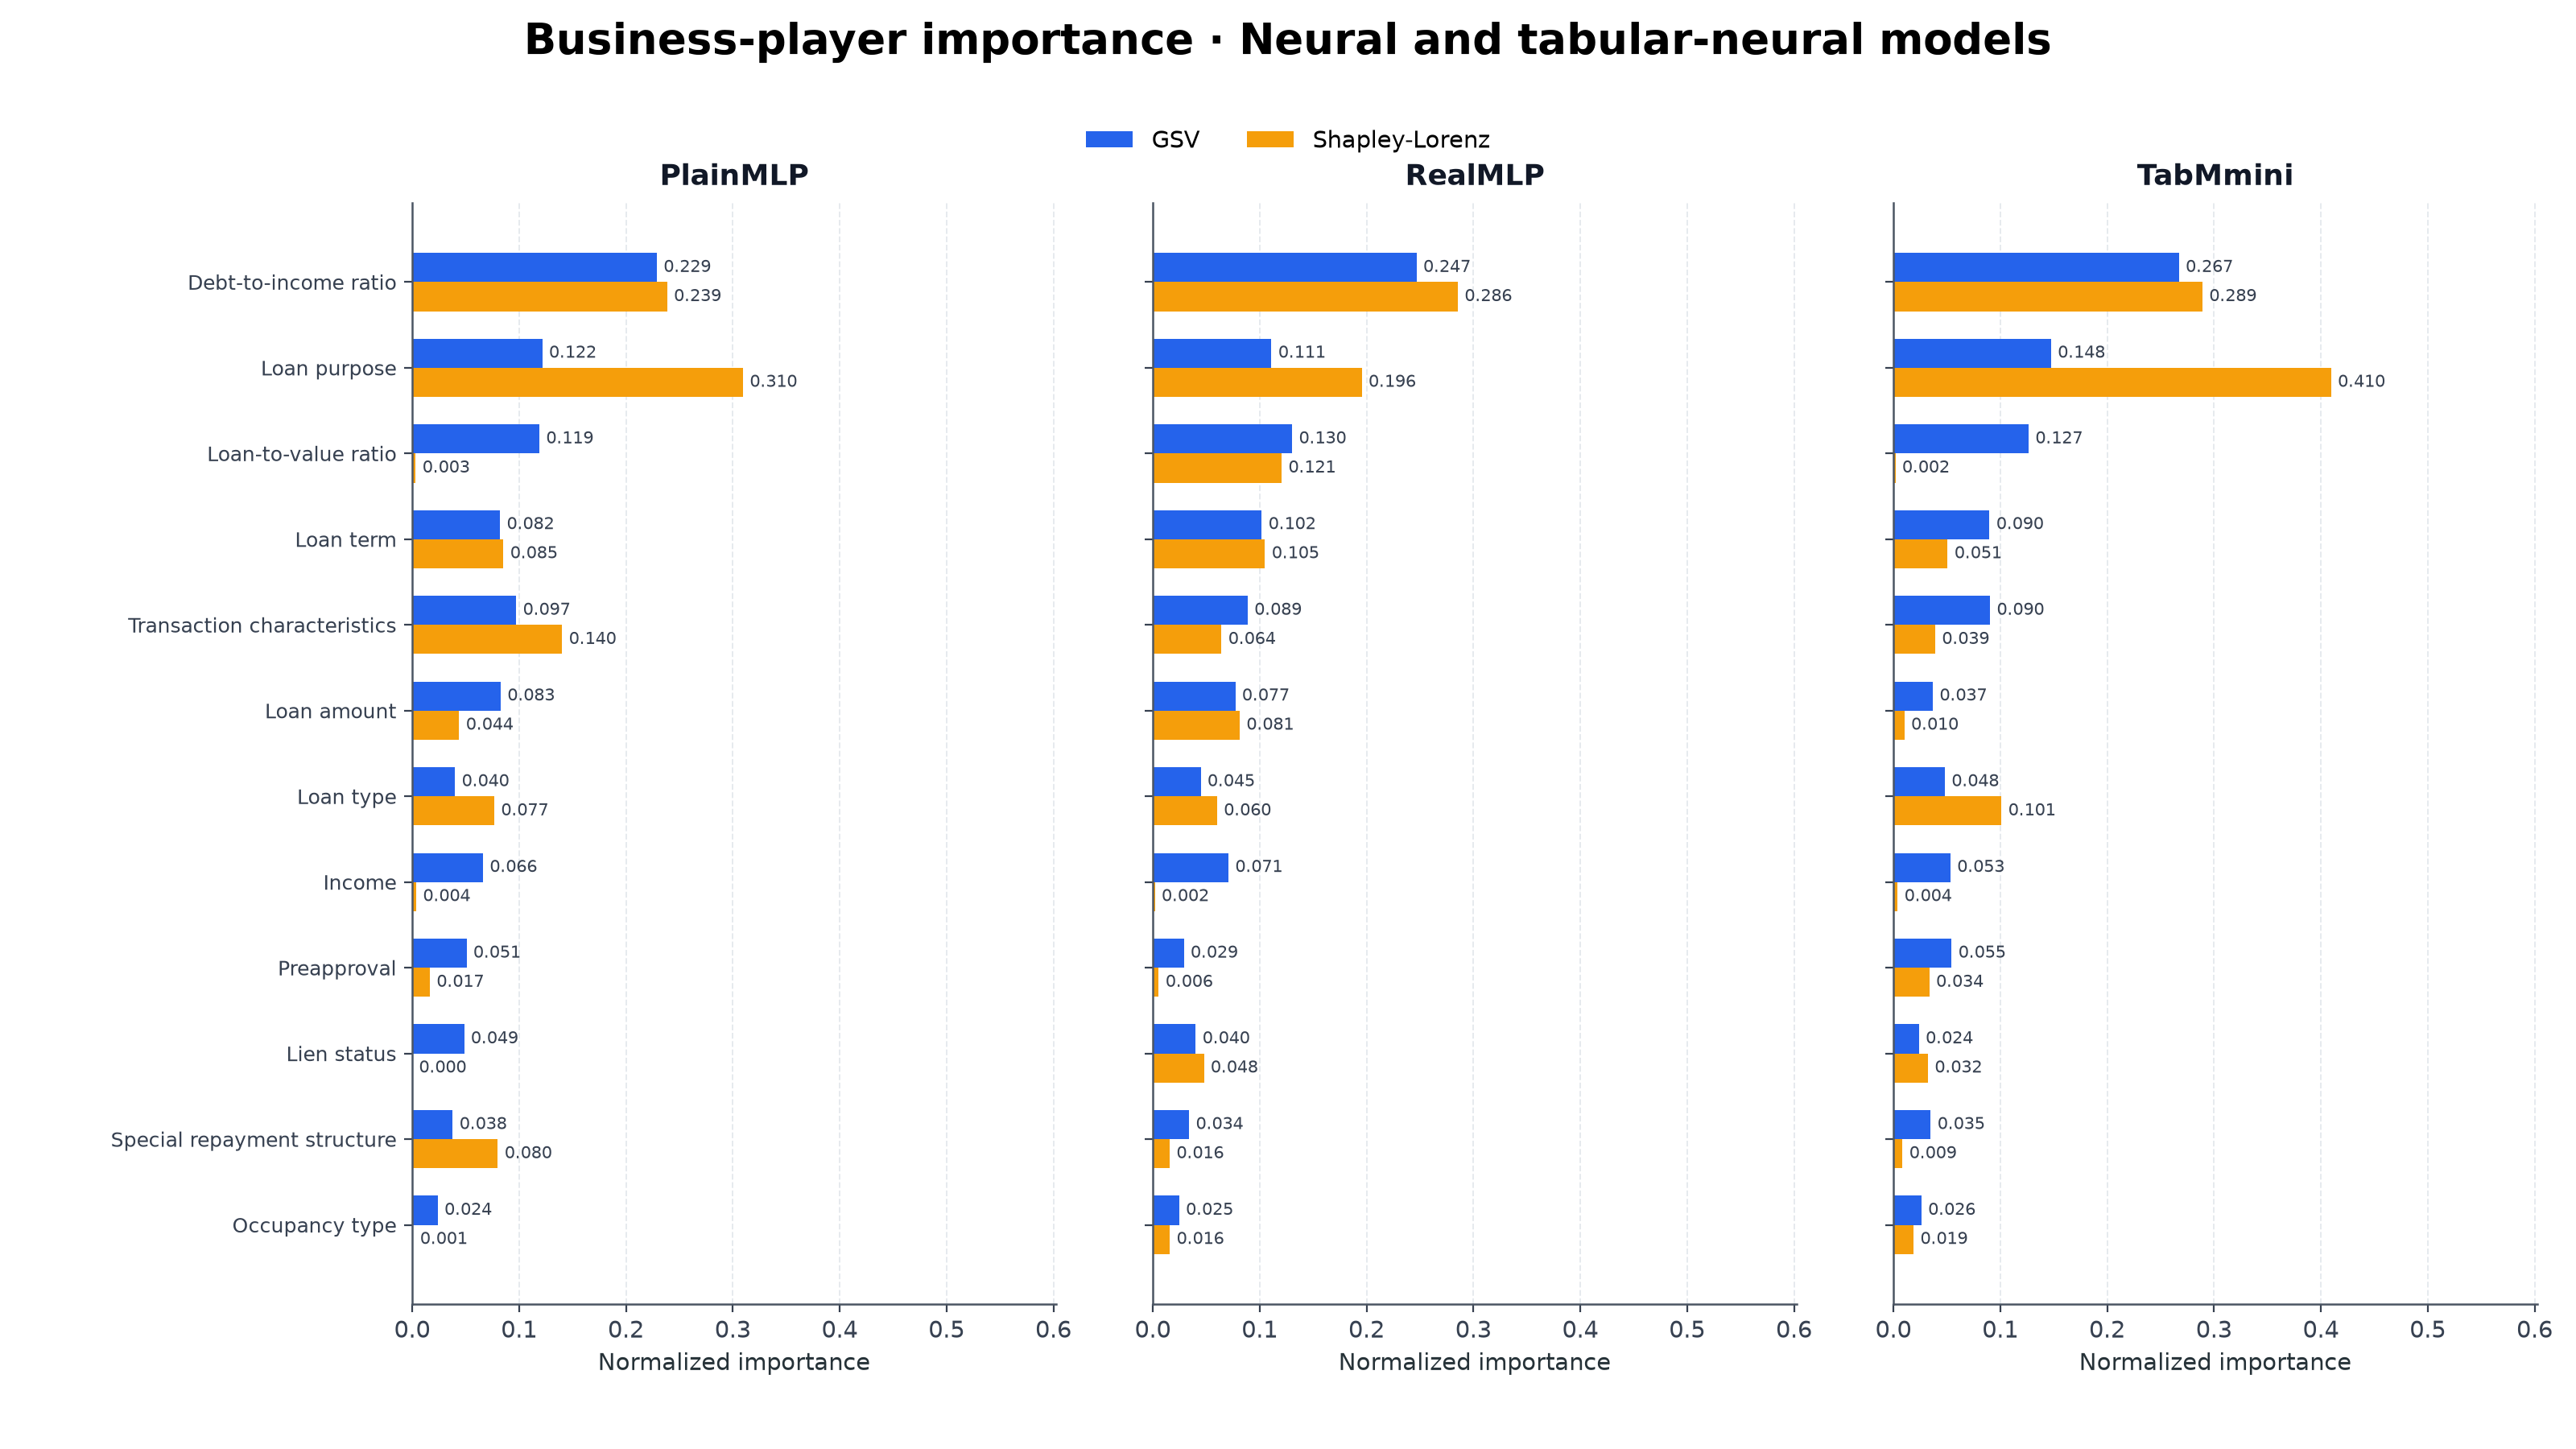

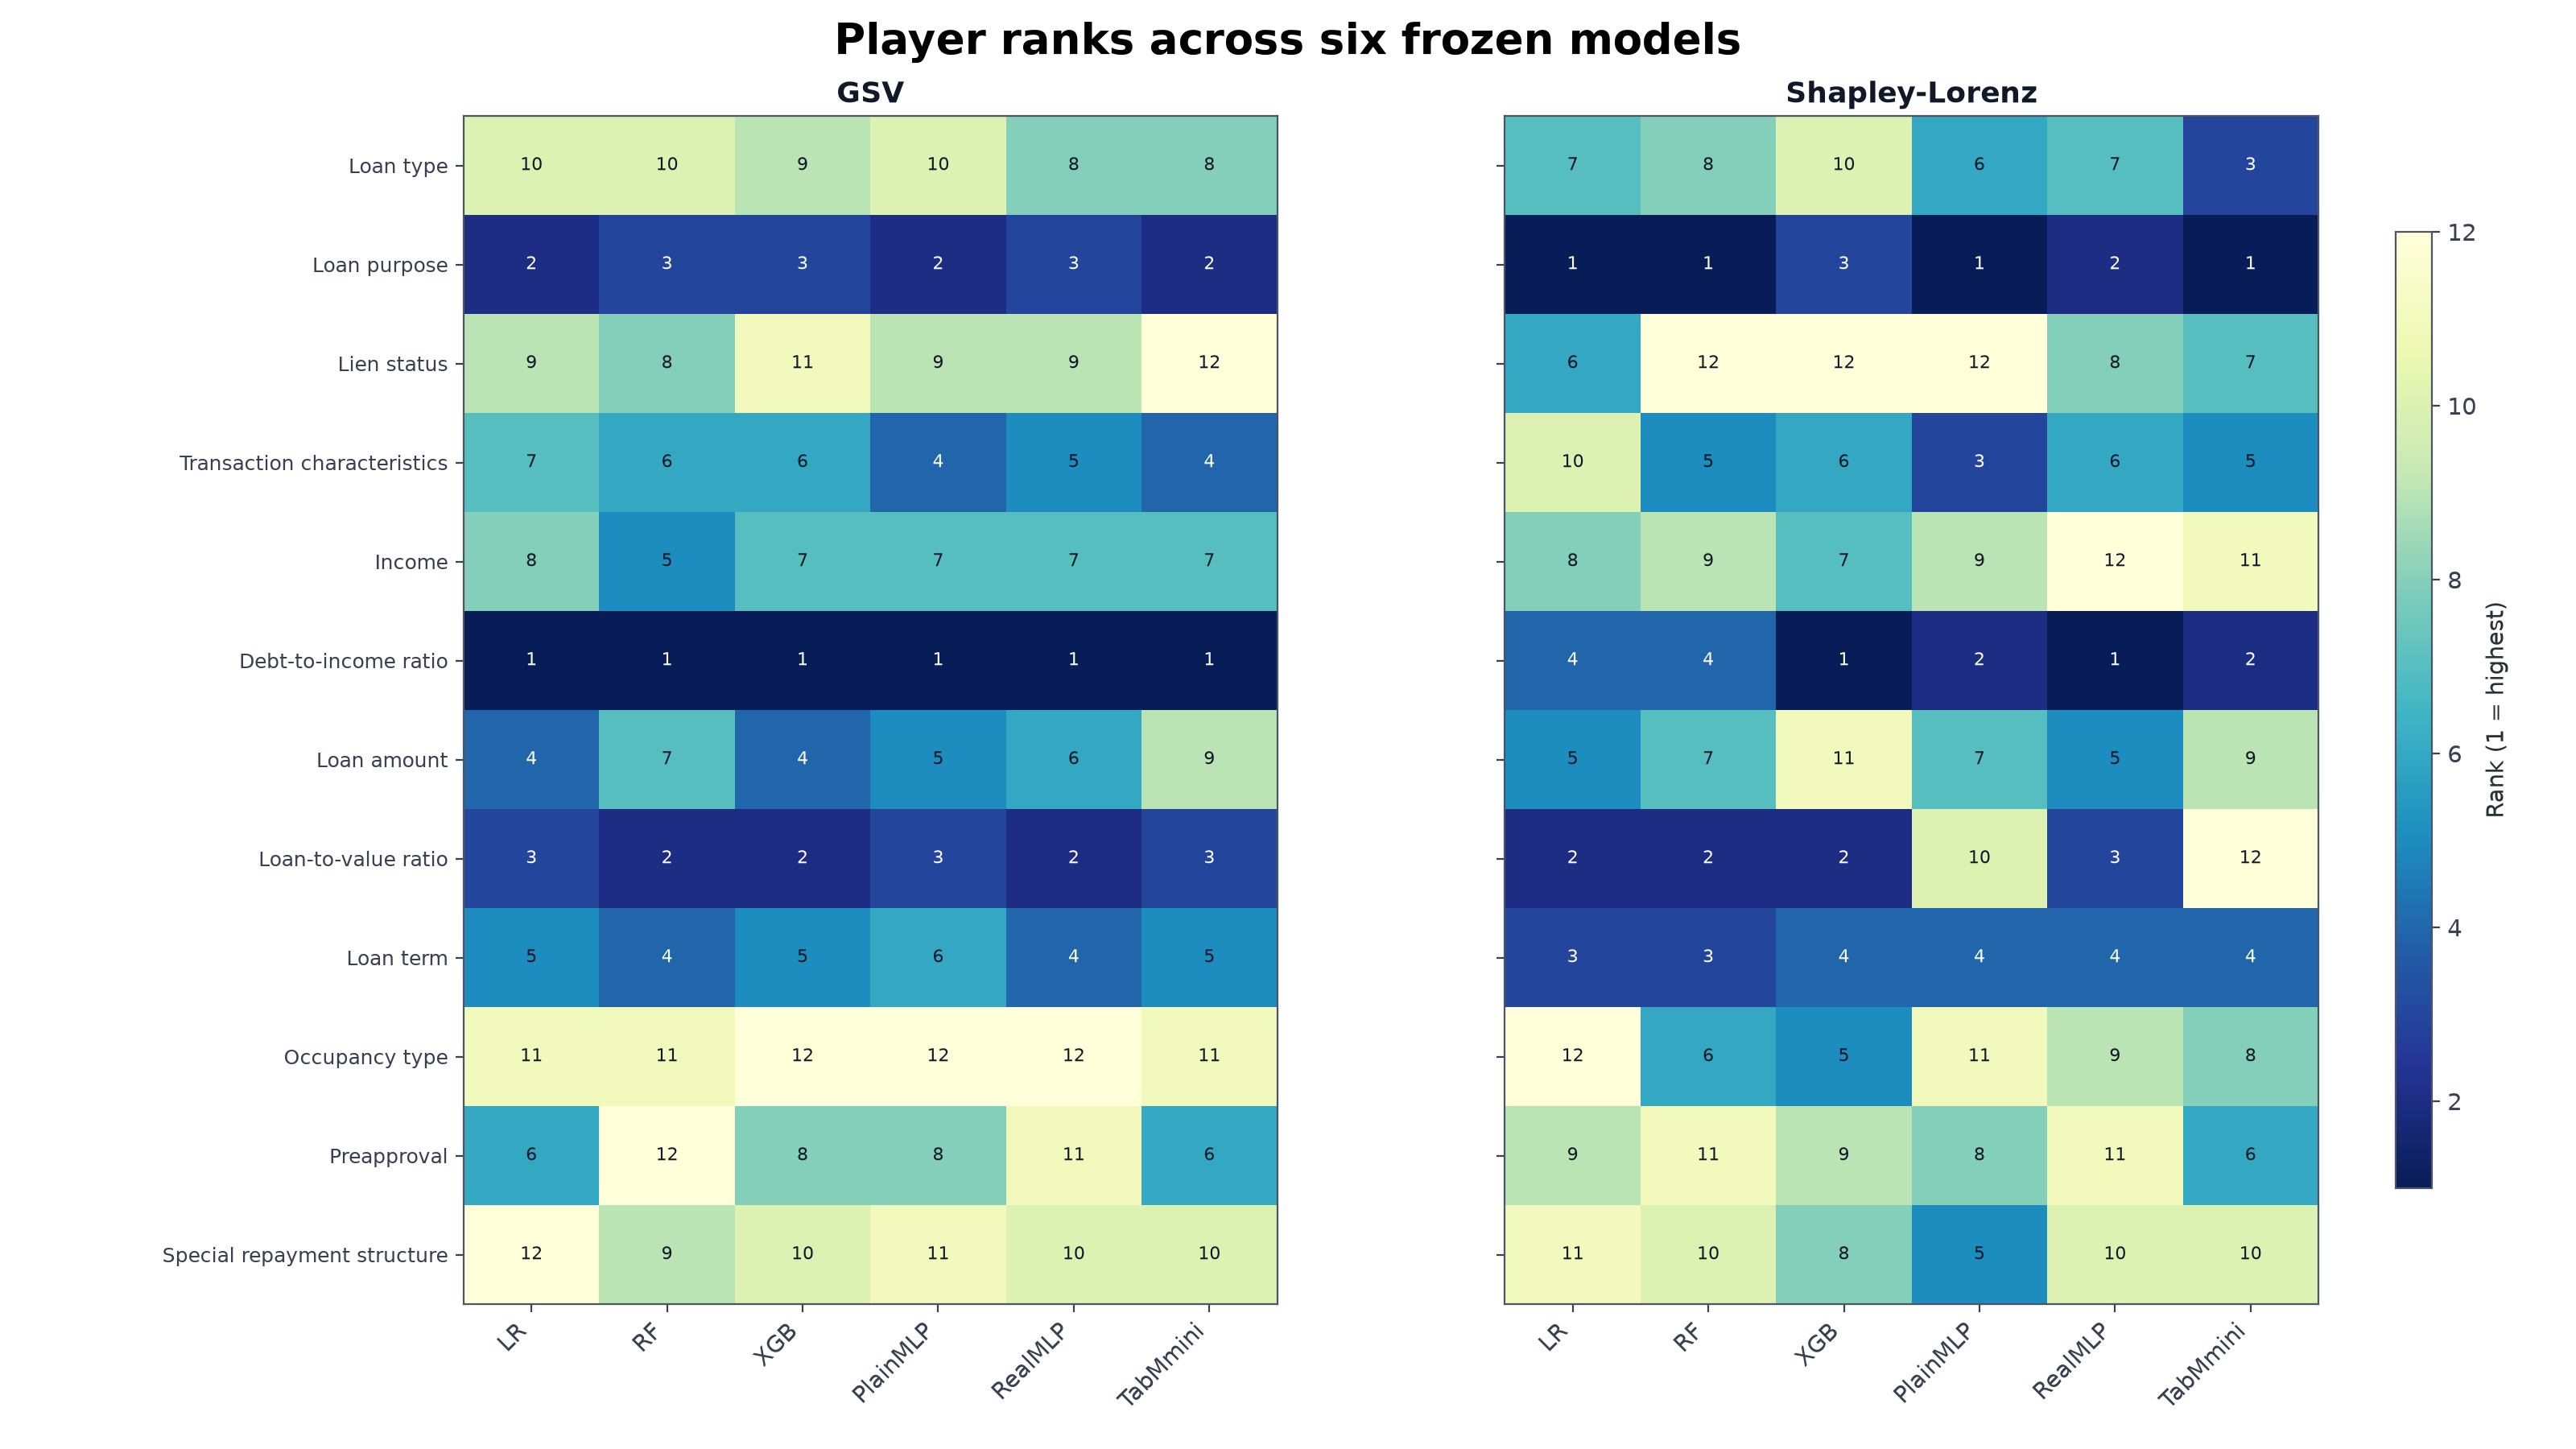

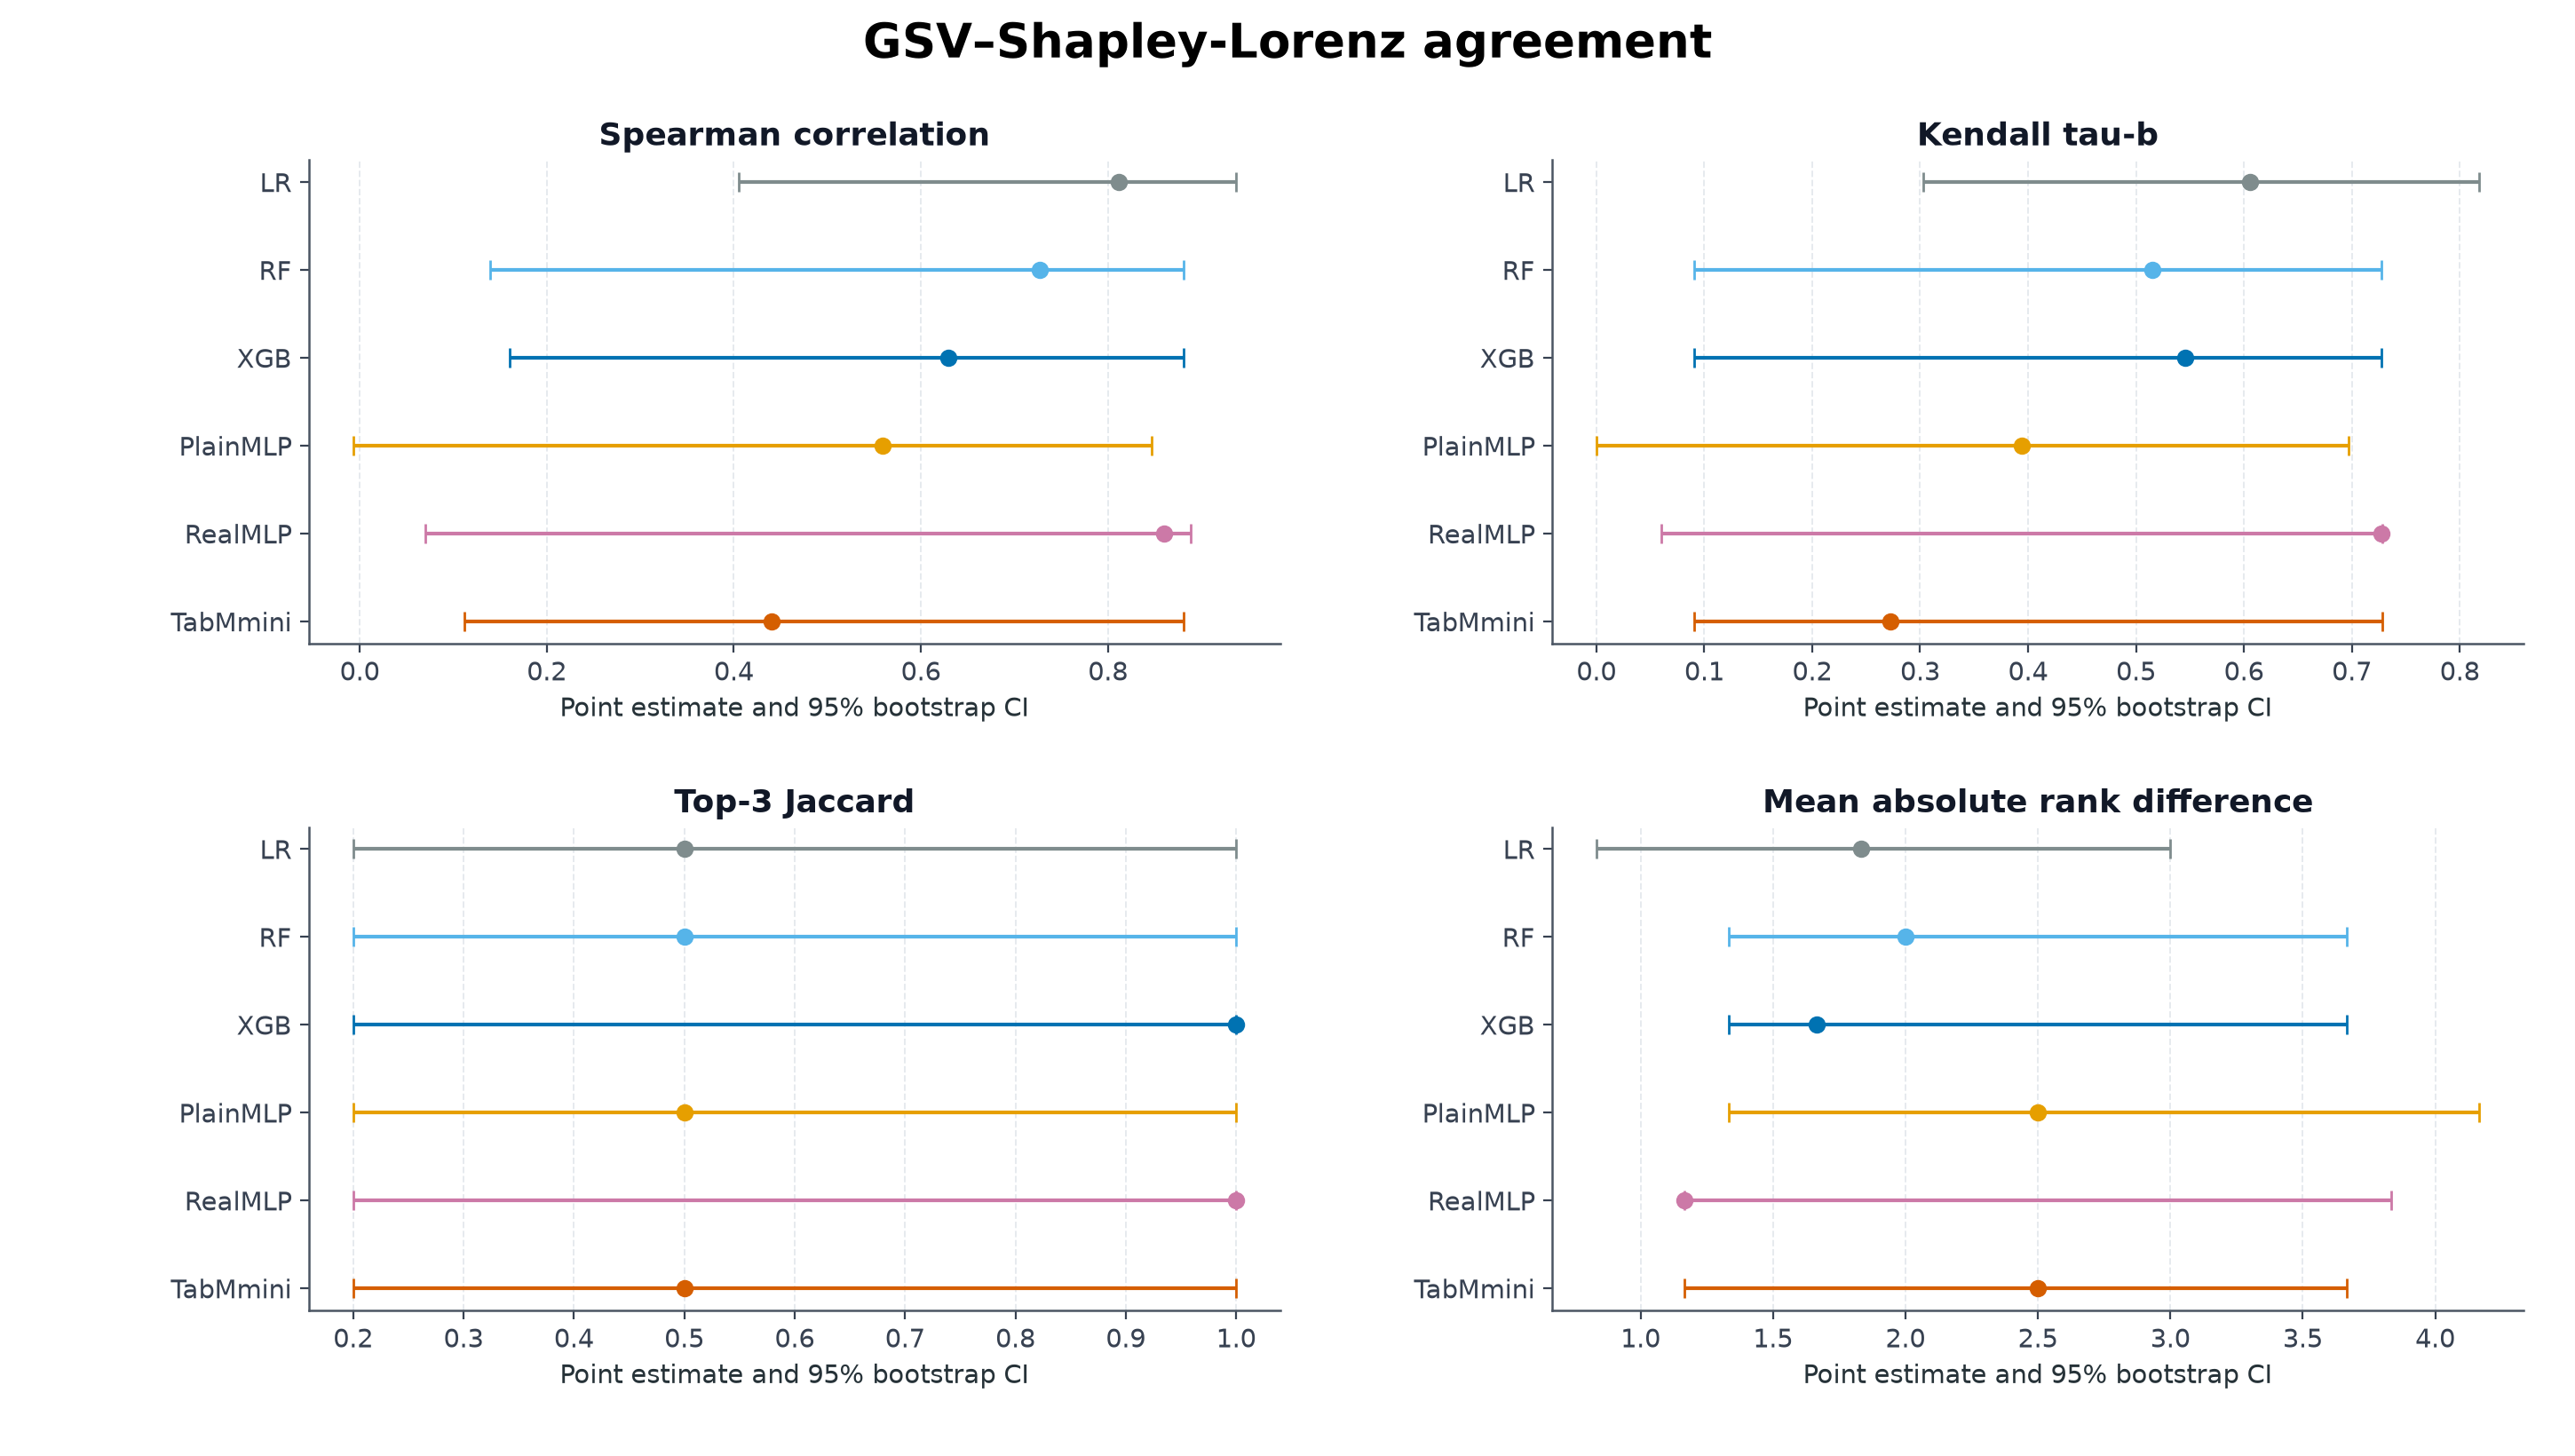

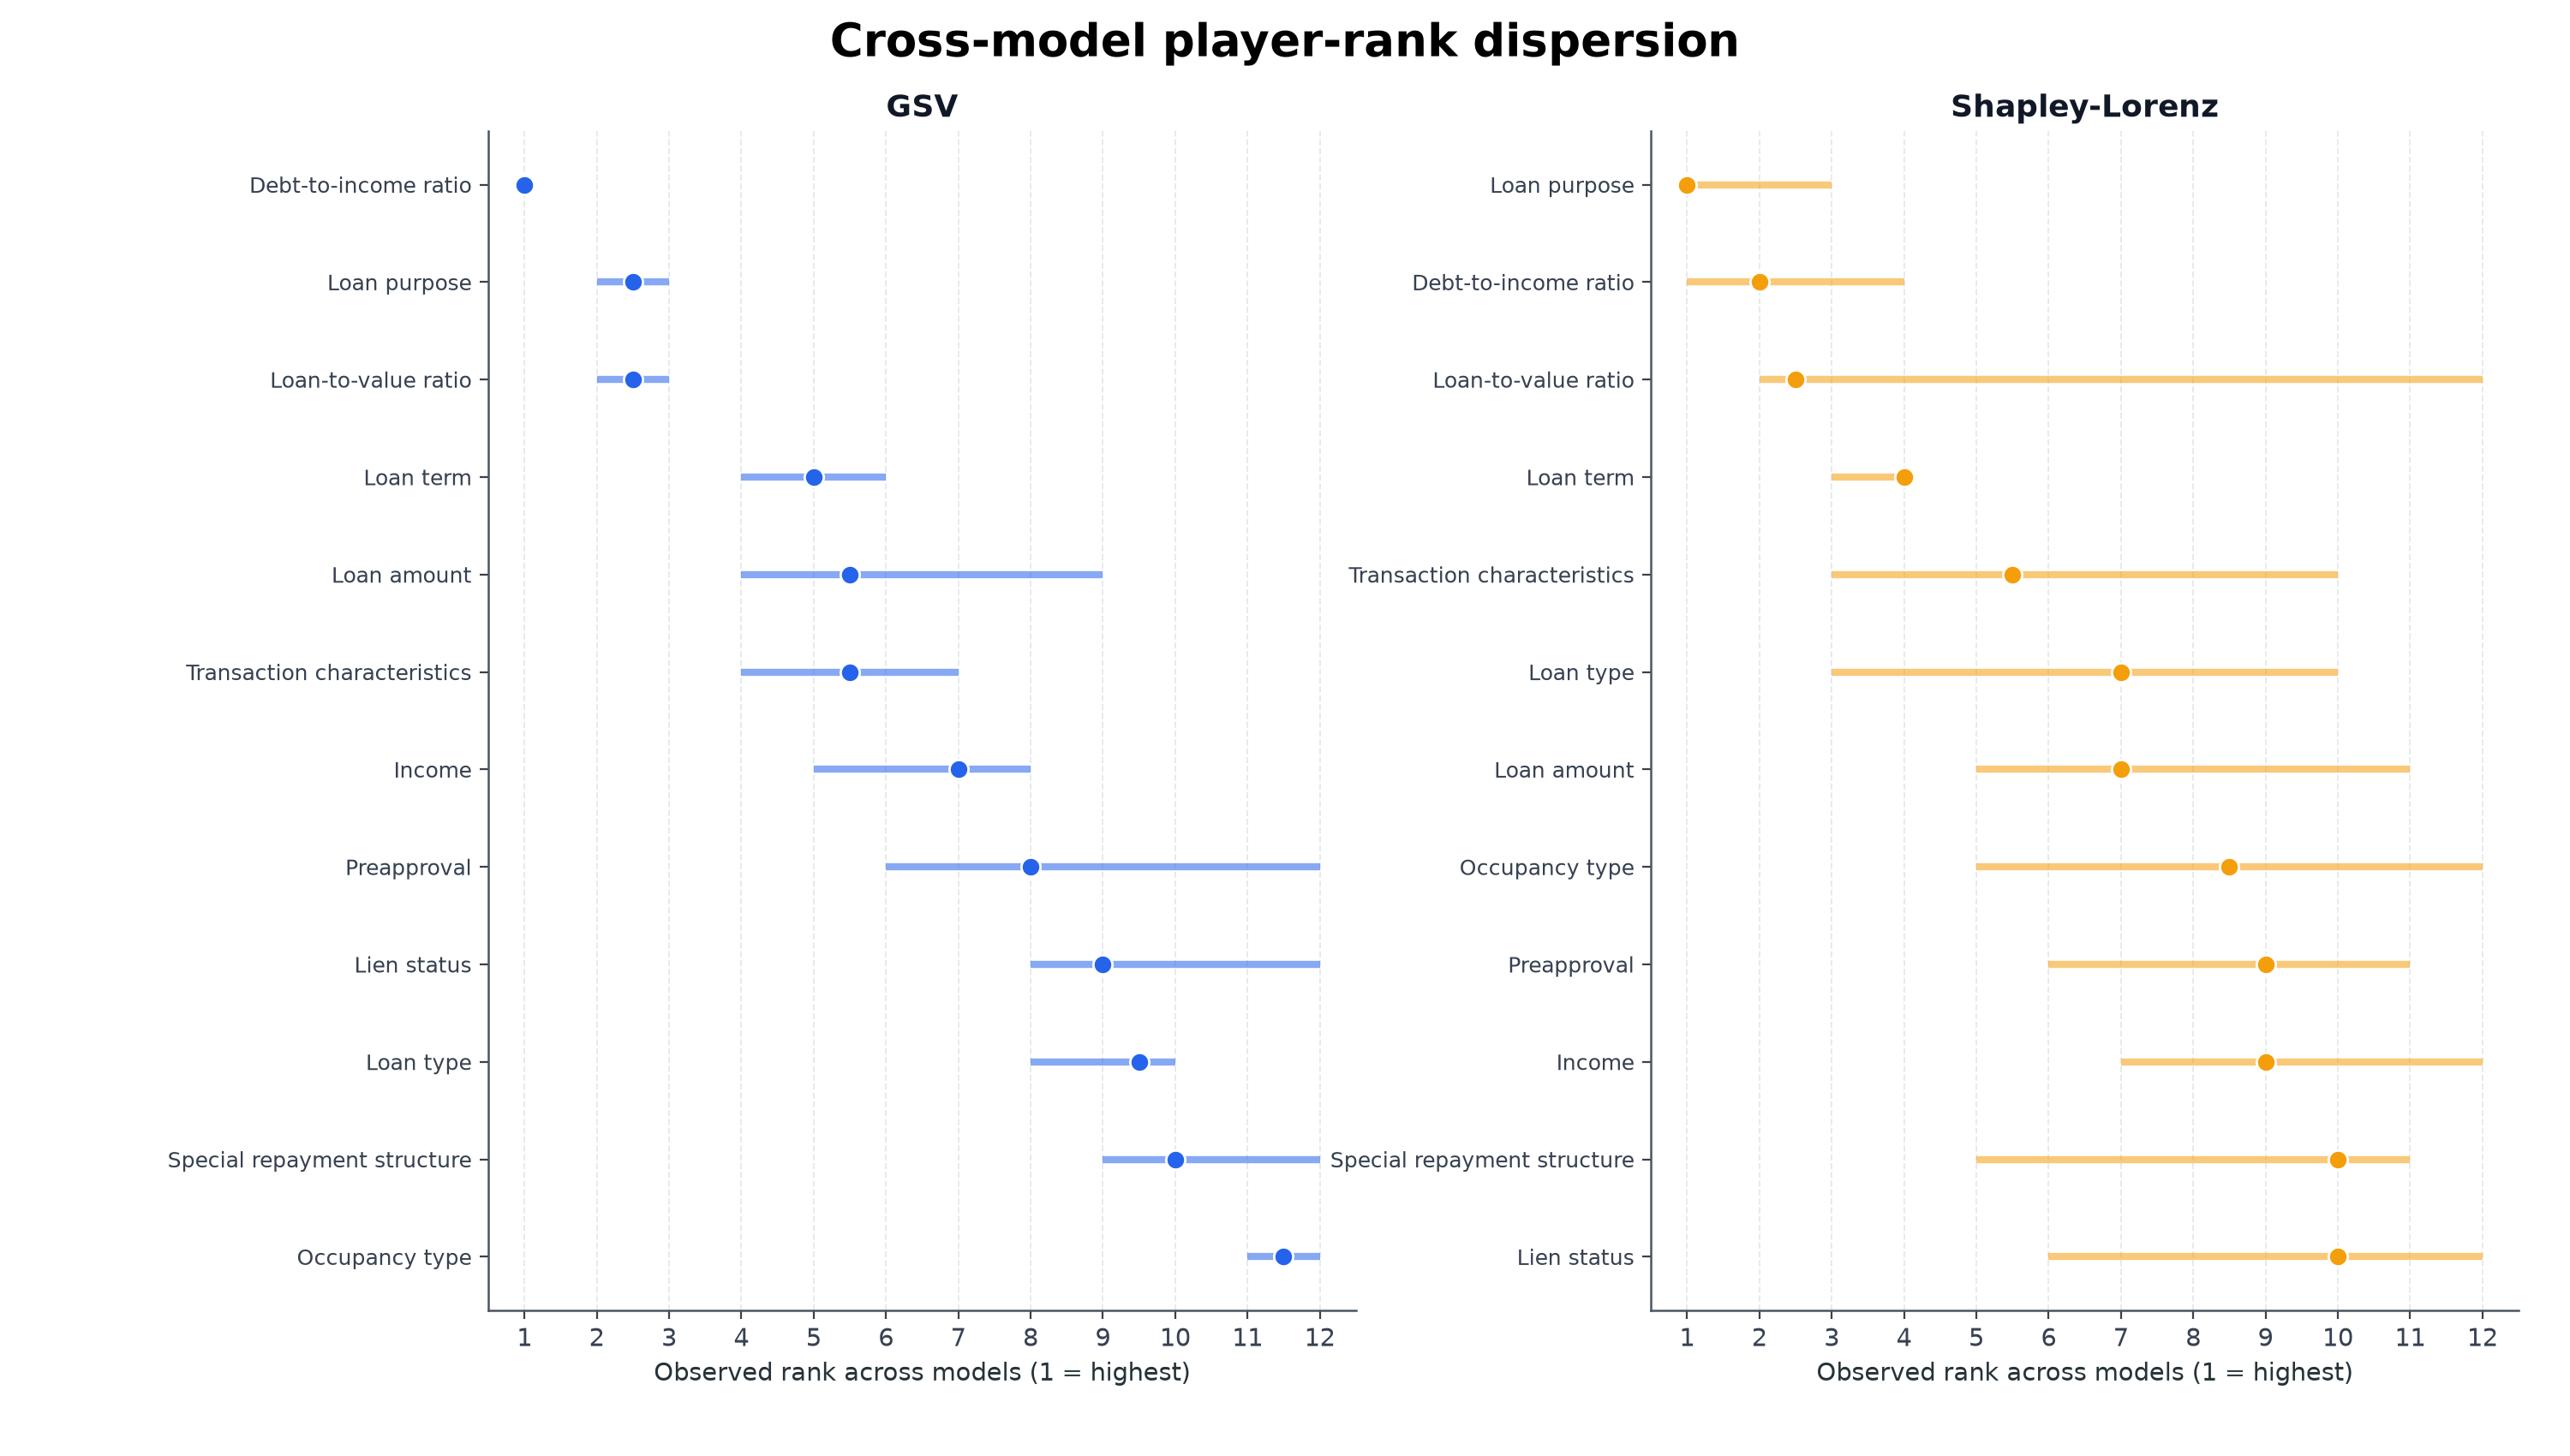

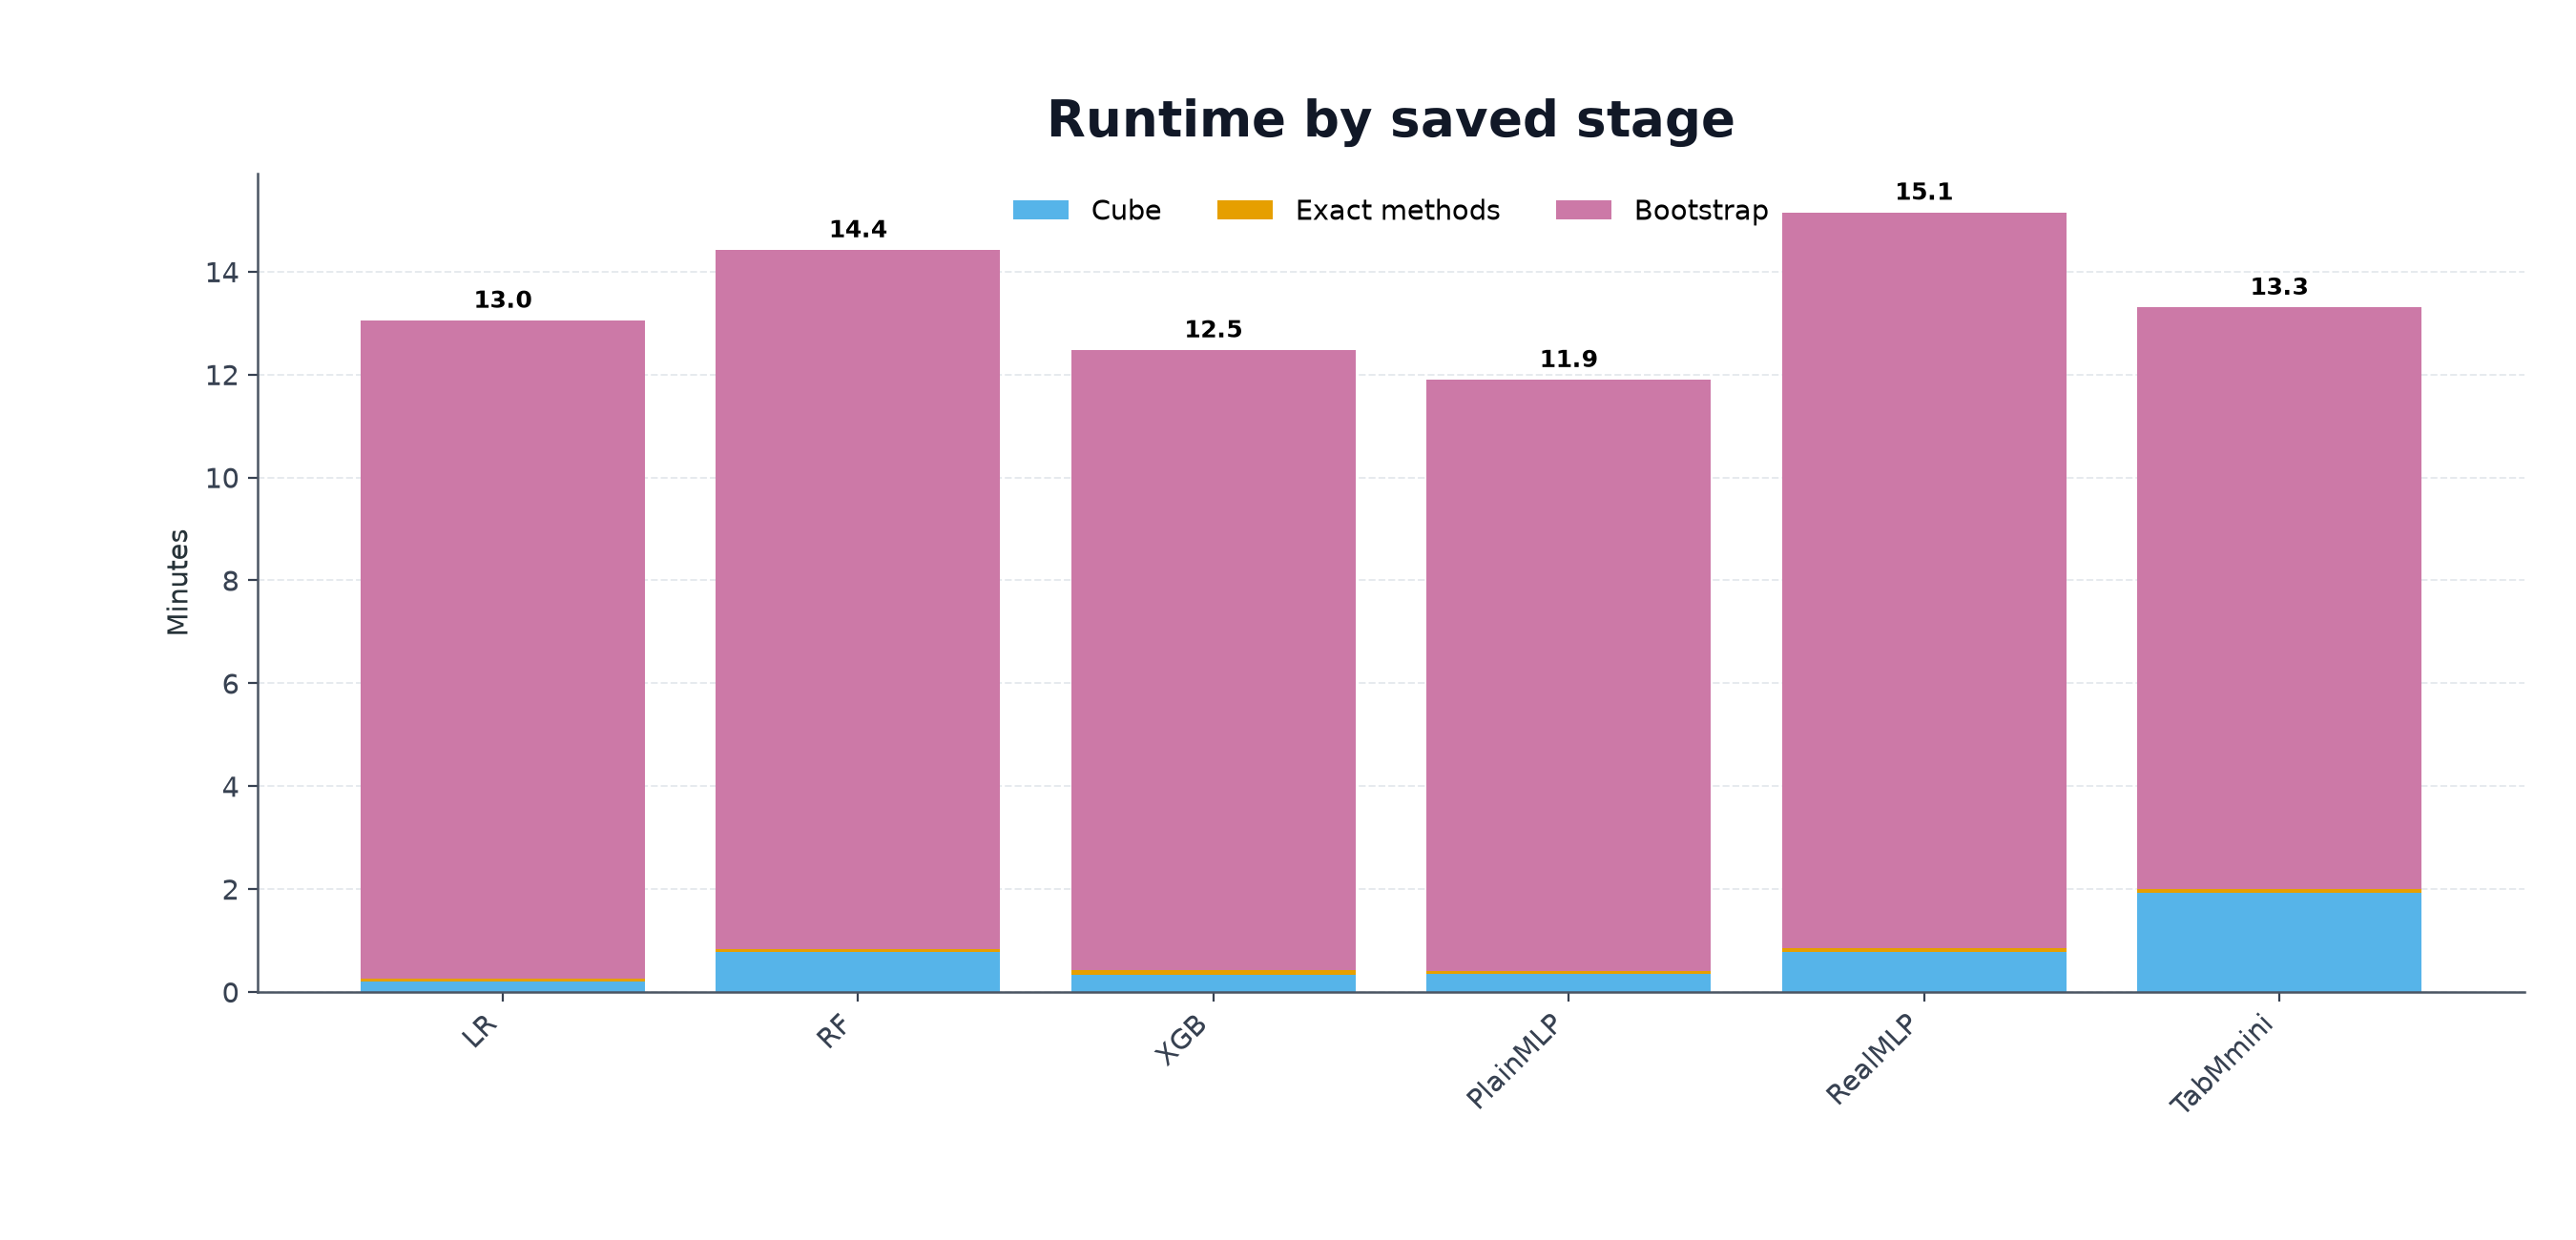

In [11]:
RQ2_METRICS = [
    ('spearman','Spearman correlation'), ('kendall_tau_b','Kendall tau-b'),
    ('top_k_jaccard','Top-3 Jaccard'), ('mean_absolute_rank_difference','Mean absolute rank difference'),
]
METHOD_LABELS = {'gsv':'GSV','shapley_lorenz':'Shapley-Lorenz'}

def plot_rq2_importance(profile, group_slug, group_title, group_models):
    is_slide=profile=='slide'
    if is_slide:
        fig, axes=plt.subplots(1,3,figsize=(16,9),sharex=True,sharey=True)
    else:
        fig, axes=plt.subplots(3,1,figsize=(7.2,10.2),sharex=True,sharey=True)
    axes=np.atleast_1d(axes); y=np.arange(len(player_order)); height=0.34
    x_limit=float(rq2['normalized_importance'].max())*1.20
    for index,(ax,model) in enumerate(zip(axes,group_models)):
        block=rq2.loc[rq2['model_key'].eq(model)]
        gsv=block.loc[block['method'].eq('gsv')].set_index('player_key').loc[player_order]
        sl=block.loc[block['method'].eq('shapley_lorenz')].set_index('player_key').loc[player_order]
        bars1=ax.barh(y-height/2,gsv['normalized_importance'],height=height,color=METHOD_COLORS['gsv'])
        bars2=ax.barh(y+height/2,sl['normalized_importance'],height=height,color=METHOD_COLORS['shapley_lorenz'])
        for bars in (bars1,bars2): ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=7.7 if is_slide else 9,color='#374151')
        ax.set_title(MODEL_LABELS[model],fontsize=PROFILES[profile]['panel'],pad=8); ax.set_xlim(0,x_limit); ax.set_xlabel('Normalized importance')
        ax.set_yticks(y,[PLAYER_LABELS[p] for p in player_order],fontsize=9); ax.tick_params(axis='x',labelbottom=True); polish_axis(ax,'x')
    axes[0].invert_yaxis()
    handles=[Patch(facecolor=METHOD_COLORS['gsv'],label='GSV'),Patch(facecolor=METHOD_COLORS['shapley_lorenz'],label='Shapley-Lorenz')]
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(0.5,0.925 if is_slide else 0.955),ncol=2,frameon=False)
    fig.suptitle(f'Business-player importance · {group_title}' if is_slide else f'Importance · {group_title}',
                 fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.16 if is_slide else 0.28,right=0.985,top=0.86 if is_slide else 0.91,bottom=0.10 if is_slide else 0.07,
                        wspace=0.15,hspace=0.36 if not is_slide else 0.2)
    return fig

def plot_rank_heatmaps(profile):
    is_slide=profile=='slide'
    fig, axes=plt.subplots(1,2,figsize=(16,9)) if is_slide else plt.subplots(2,1,figsize=(7.2,10.2))
    axes=np.atleast_1d(axes); player_index=(rq2[['player_index','player_key']].drop_duplicates().sort_values('player_index')['player_key'].tolist())
    for panel_index,(ax,method) in enumerate(zip(axes,['gsv','shapley_lorenz'])):
        matrix=rq2.loc[rq2['method'].eq(method)].pivot(index='player_key',columns='model_key',values='rank').loc[player_index,MODEL_ORDER]
        image=ax.imshow(matrix.to_numpy(),vmin=1,vmax=len(player_index),cmap='YlGnBu_r',aspect='auto')
        ax.set_xticks(range(6),[MODEL_LABELS[m] for m in MODEL_ORDER],rotation=45,ha='right')
        ax.set_yticks(range(len(player_index)),[PLAYER_LABELS[p] for p in player_index],fontsize=9)
        if is_slide and panel_index == 1: ax.tick_params(axis='y', labelleft=False)
        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                value=matrix.iloc[i,j]; ax.text(j,i,f'{value:.0f}',ha='center',va='center',fontsize=8 if is_slide else 9,
                    color='white' if value <= 4 else '#111827')
        ax.set_title(METHOD_LABELS[method],fontsize=PROFILES[profile]['panel']); ax.grid(False)
    colorbar_axis=fig.add_axes([0.93,0.18,0.014,0.66] if is_slide else [0.89,0.18,0.016,0.66])
    fig.colorbar(image,cax=colorbar_axis,label='Rank (1 = highest)')
    fig.suptitle('Player ranks across six frozen models',fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.18 if is_slide else 0.26,right=0.90 if is_slide else 0.85,top=0.92,bottom=0.10,hspace=0.32,wspace=0.28)
    return fig

def plot_agreement(profile):
    is_slide=profile=='slide'; fig,axes=plt.subplots(2,2,figsize=(14.5,8.2) if is_slide else (7.2,7.8))
    for ax,(metric,title) in zip(axes.flat,RQ2_METRICS):
        block=rq2_bootstrap.loc[rq2_bootstrap['metric'].eq(metric)].set_index('model_key').loc[MODEL_ORDER]
        y=np.arange(6); values=block['point_estimate'].to_numpy(float)
        errors=np.vstack([values-block['ci_lower'].to_numpy(float),block['ci_upper'].to_numpy(float)-values])
        for i,m in enumerate(MODEL_ORDER): ax.errorbar(values[i],i,xerr=errors[:,i:i+1],fmt='o',color=MODEL_COLORS[m],ecolor=MODEL_COLORS[m],capsize=4)
        ax.set_yticks(y,[MODEL_LABELS[m] for m in MODEL_ORDER]); ax.invert_yaxis(); ax.set_title(title,fontsize=PROFILES[profile]['panel'])
        ax.set_xlabel('Point estimate and 95% bootstrap CI'); polish_axis(ax,'x')
    fig.suptitle('GSV–Shapley-Lorenz agreement',fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.12 if is_slide else 0.18,right=0.98,top=0.89,bottom=0.10,wspace=0.28,hspace=0.38)
    return fig

def plot_rank_dispersion(profile):
    is_slide=profile=='slide'; fig,axes=plt.subplots(1,2,figsize=(15,8.5)) if is_slide else plt.subplots(2,1,figsize=(7.2,10.0))
    axes=np.atleast_1d(axes)
    for ax,method in zip(axes,['gsv','shapley_lorenz']):
        d=(rq2.loc[rq2['method'].eq(method)].groupby('player_key')['rank'].agg(rank_min='min',rank_median='median',rank_max='max')
           .sort_values(['rank_median','rank_min']))
        y=np.arange(len(d)); ax.hlines(y,d['rank_min'],d['rank_max'],color=METHOD_COLORS[method],linewidth=3,alpha=0.55)
        ax.scatter(d['rank_median'],y,color=METHOD_COLORS[method],edgecolor='white',s=64,zorder=3)
        ax.set_yticks(y,[PLAYER_LABELS[p] for p in d.index],fontsize=9); ax.invert_yaxis(); ax.set_xticks(range(1,13)); ax.set_xlim(0.5,12.5)
        ax.set_xlabel('Observed rank across models (1 = highest)'); ax.set_title(METHOD_LABELS[method],fontsize=PROFILES[profile]['panel']); polish_axis(ax,'x')
    fig.suptitle('Cross-model player-rank dispersion',fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.19 if is_slide else 0.28,right=0.98,top=0.91,bottom=0.10,wspace=0.34,hspace=0.32)
    return fig

def plot_rq2_runtime(profile):
    is_slide=profile=='slide'; fig,ax=plt.subplots(figsize=(13.5,6.5) if is_slide else (7.2,4.8))
    block=rq2_runtime.set_index('model_key').loc[MODEL_ORDER]; bottom=np.zeros(6)
    parts=[('cube_seconds','Cube','#56B4E9'),('method_seconds','Exact methods','#E69F00'),('bootstrap_seconds','Bootstrap','#CC79A7')]
    for column,label,color in parts:
        values=block[column].to_numpy(float)/60; ax.bar(np.arange(6),values,bottom=bottom,label=label,color=color); bottom+=values
    for i,total in enumerate(block['total_seconds'].to_numpy(float)/60): ax.text(i,total+0.25,f'{total:.1f}',ha='center',fontsize=9,fontweight='bold')
    ax.set_xticks(np.arange(6),[MODEL_LABELS[m] for m in MODEL_ORDER],rotation=45,ha='right'); ax.set_ylabel('Minutes'); polish_axis(ax,'y')
    ax.legend(ncol=3,frameon=False,loc='upper center'); ax.set_title('Runtime by saved stage',fontsize=PROFILES[profile]['title'],pad=14)
    fig.subplots_adjust(left=0.10 if is_slide else 0.13,right=0.98,top=0.86,bottom=0.20)
    return fig

rq2_groups=[('classical','Baseline and tree models',['lr','rf','xgboost']),('neural','Neural and tabular-neural models',['plain_mlp','realmlp','tabmmini'])]
for profile in PROFILES:
    for slug,title,models in rq2_groups:
        stage3_outputs += finish_figure(plot_rq2_importance(profile,slug,title,models),f'rq2_gsv_sl_importance_{slug}',profile)
    stage3_outputs += finish_figure(plot_rank_heatmaps(profile),'rq2_rank_heatmaps',profile)
    stage3_outputs += finish_figure(plot_agreement(profile),'rq2_agreement_ci',profile)
    stage3_outputs += finish_figure(plot_rank_dispersion(profile),'rq2_rank_dispersion',profile)
    stage3_outputs += finish_figure(plot_rq2_runtime(profile),'rq2_runtime_appendix',profile)


## 9. RQ3 final figures

All signed gaps use target minus reference. The primary comparisons are Female − Male, Black − White, and Asian − White. Dashed zero lines mark parity. Calibration residual gaps are kept separate from outcome-rate gaps, and performance–disparity plots show both stored RQ1 and RQ3 confidence intervals.

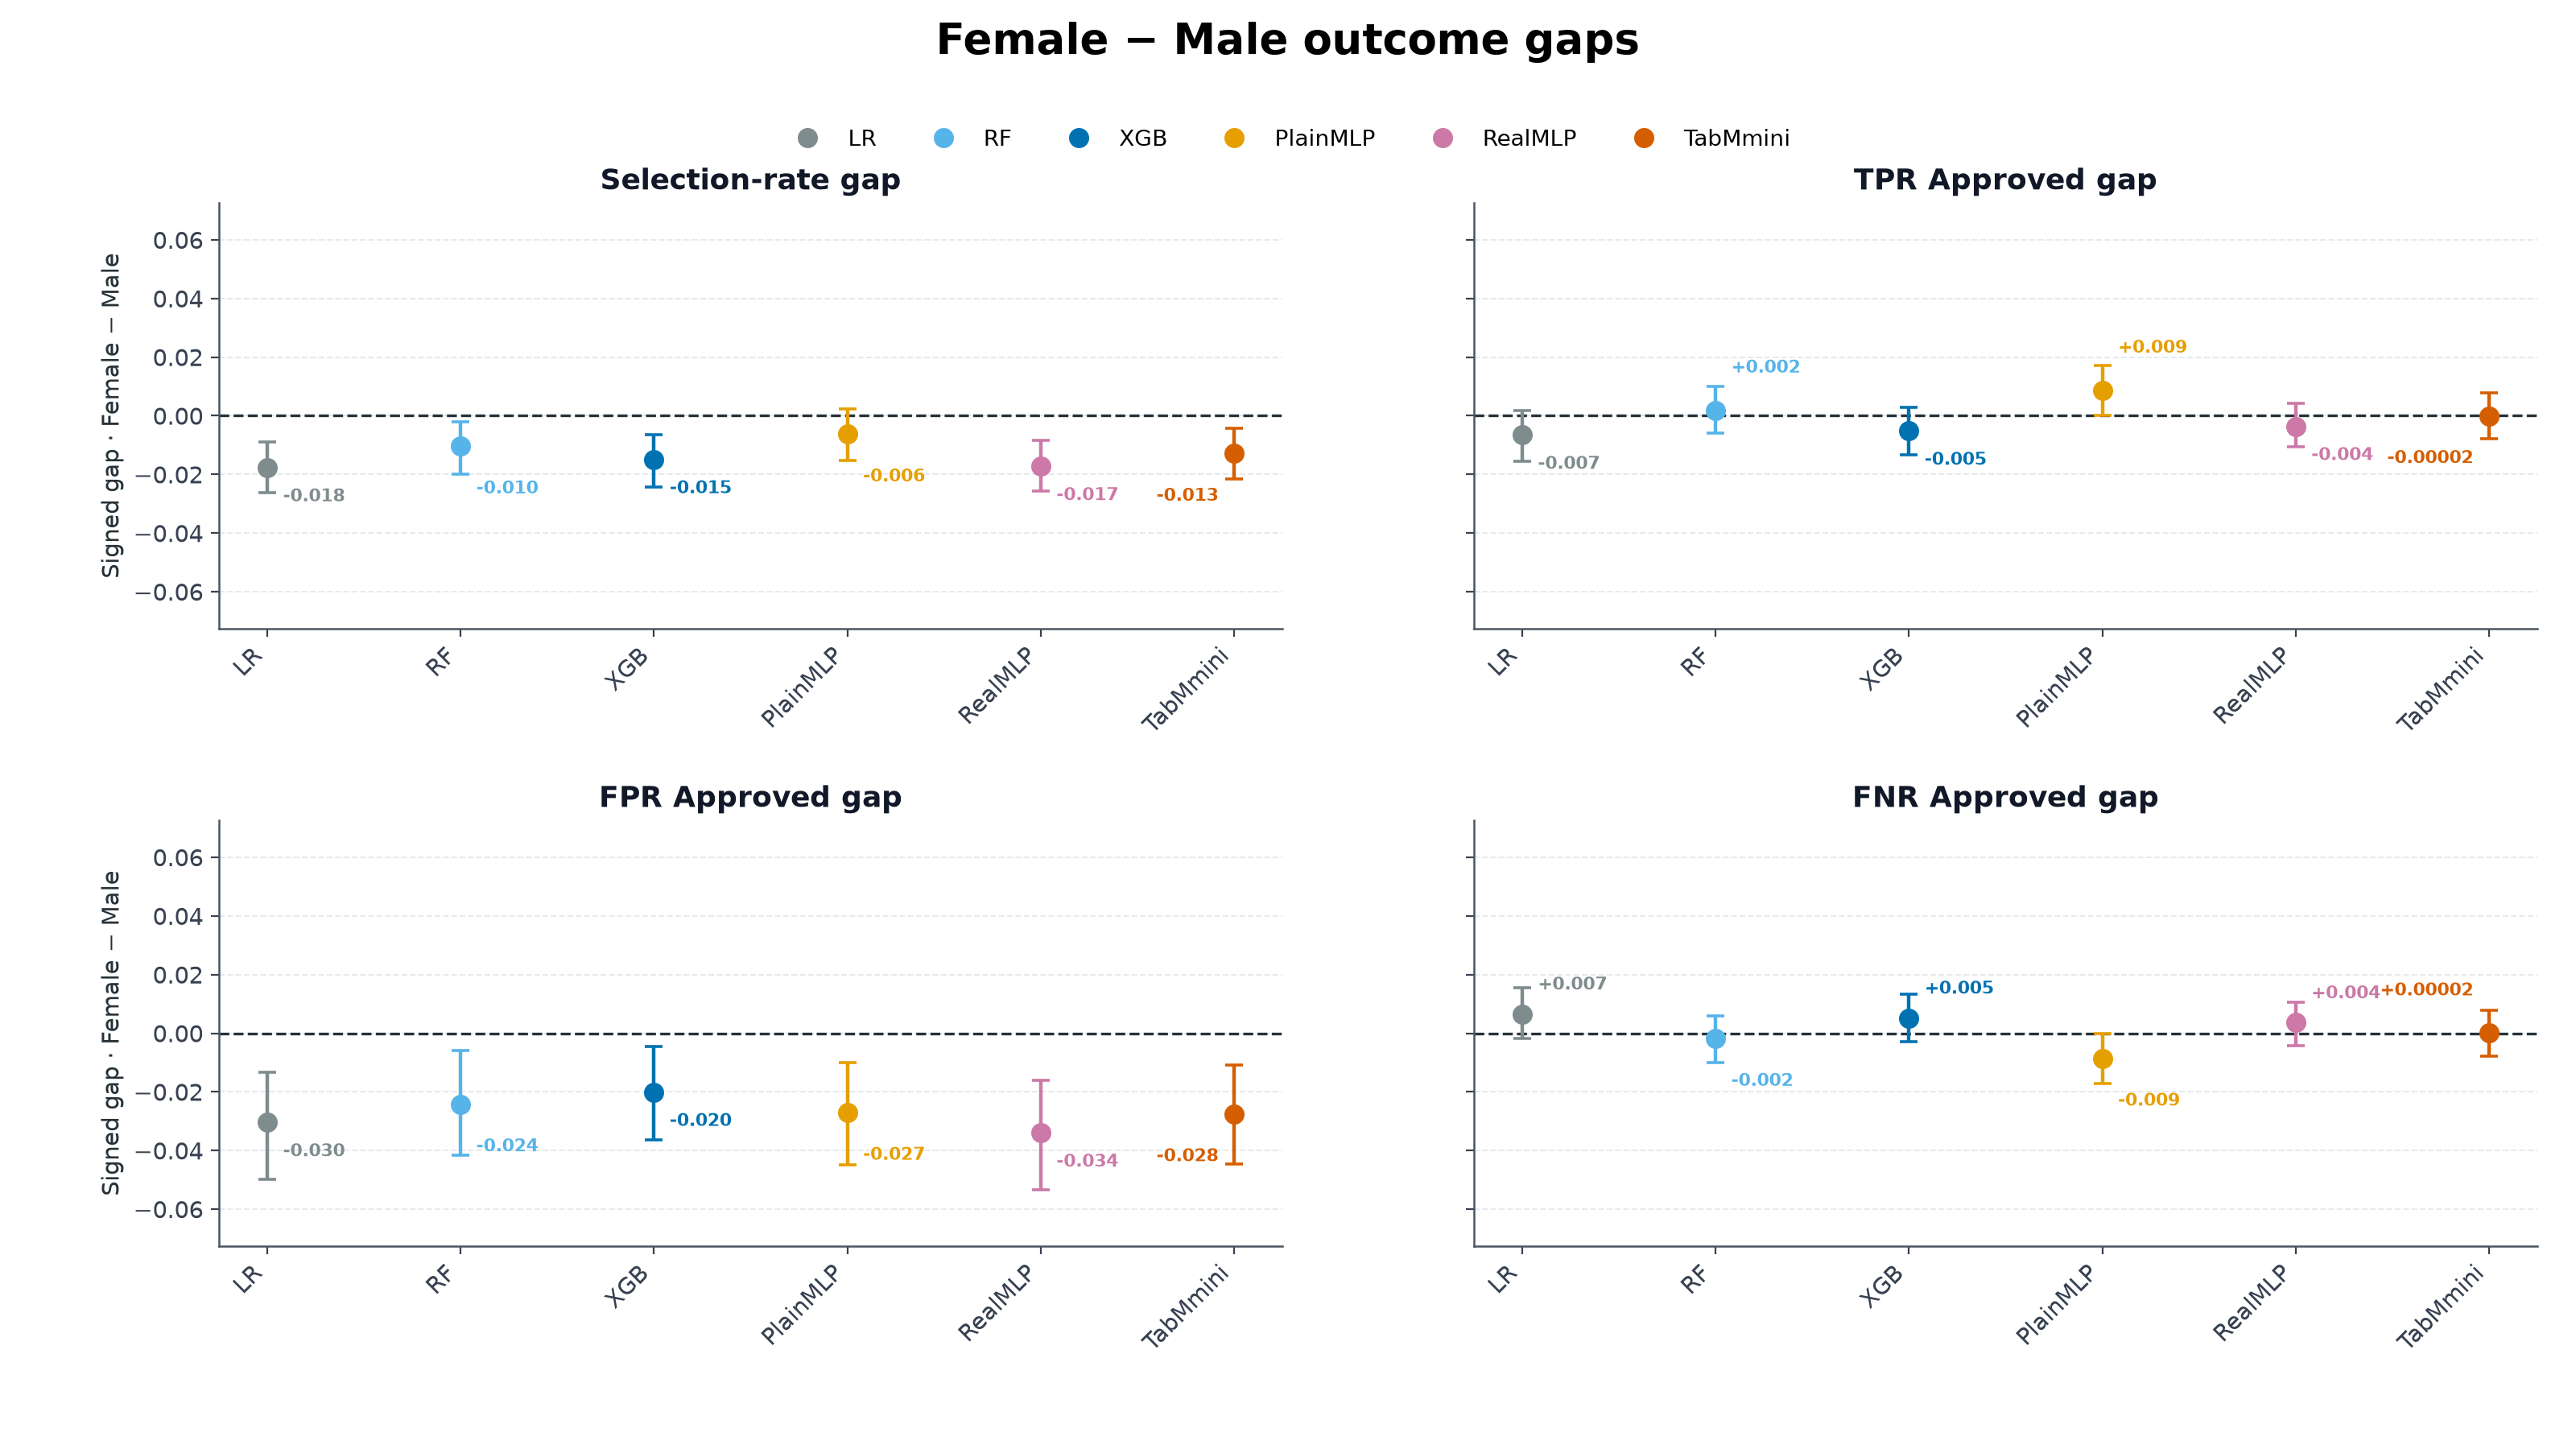

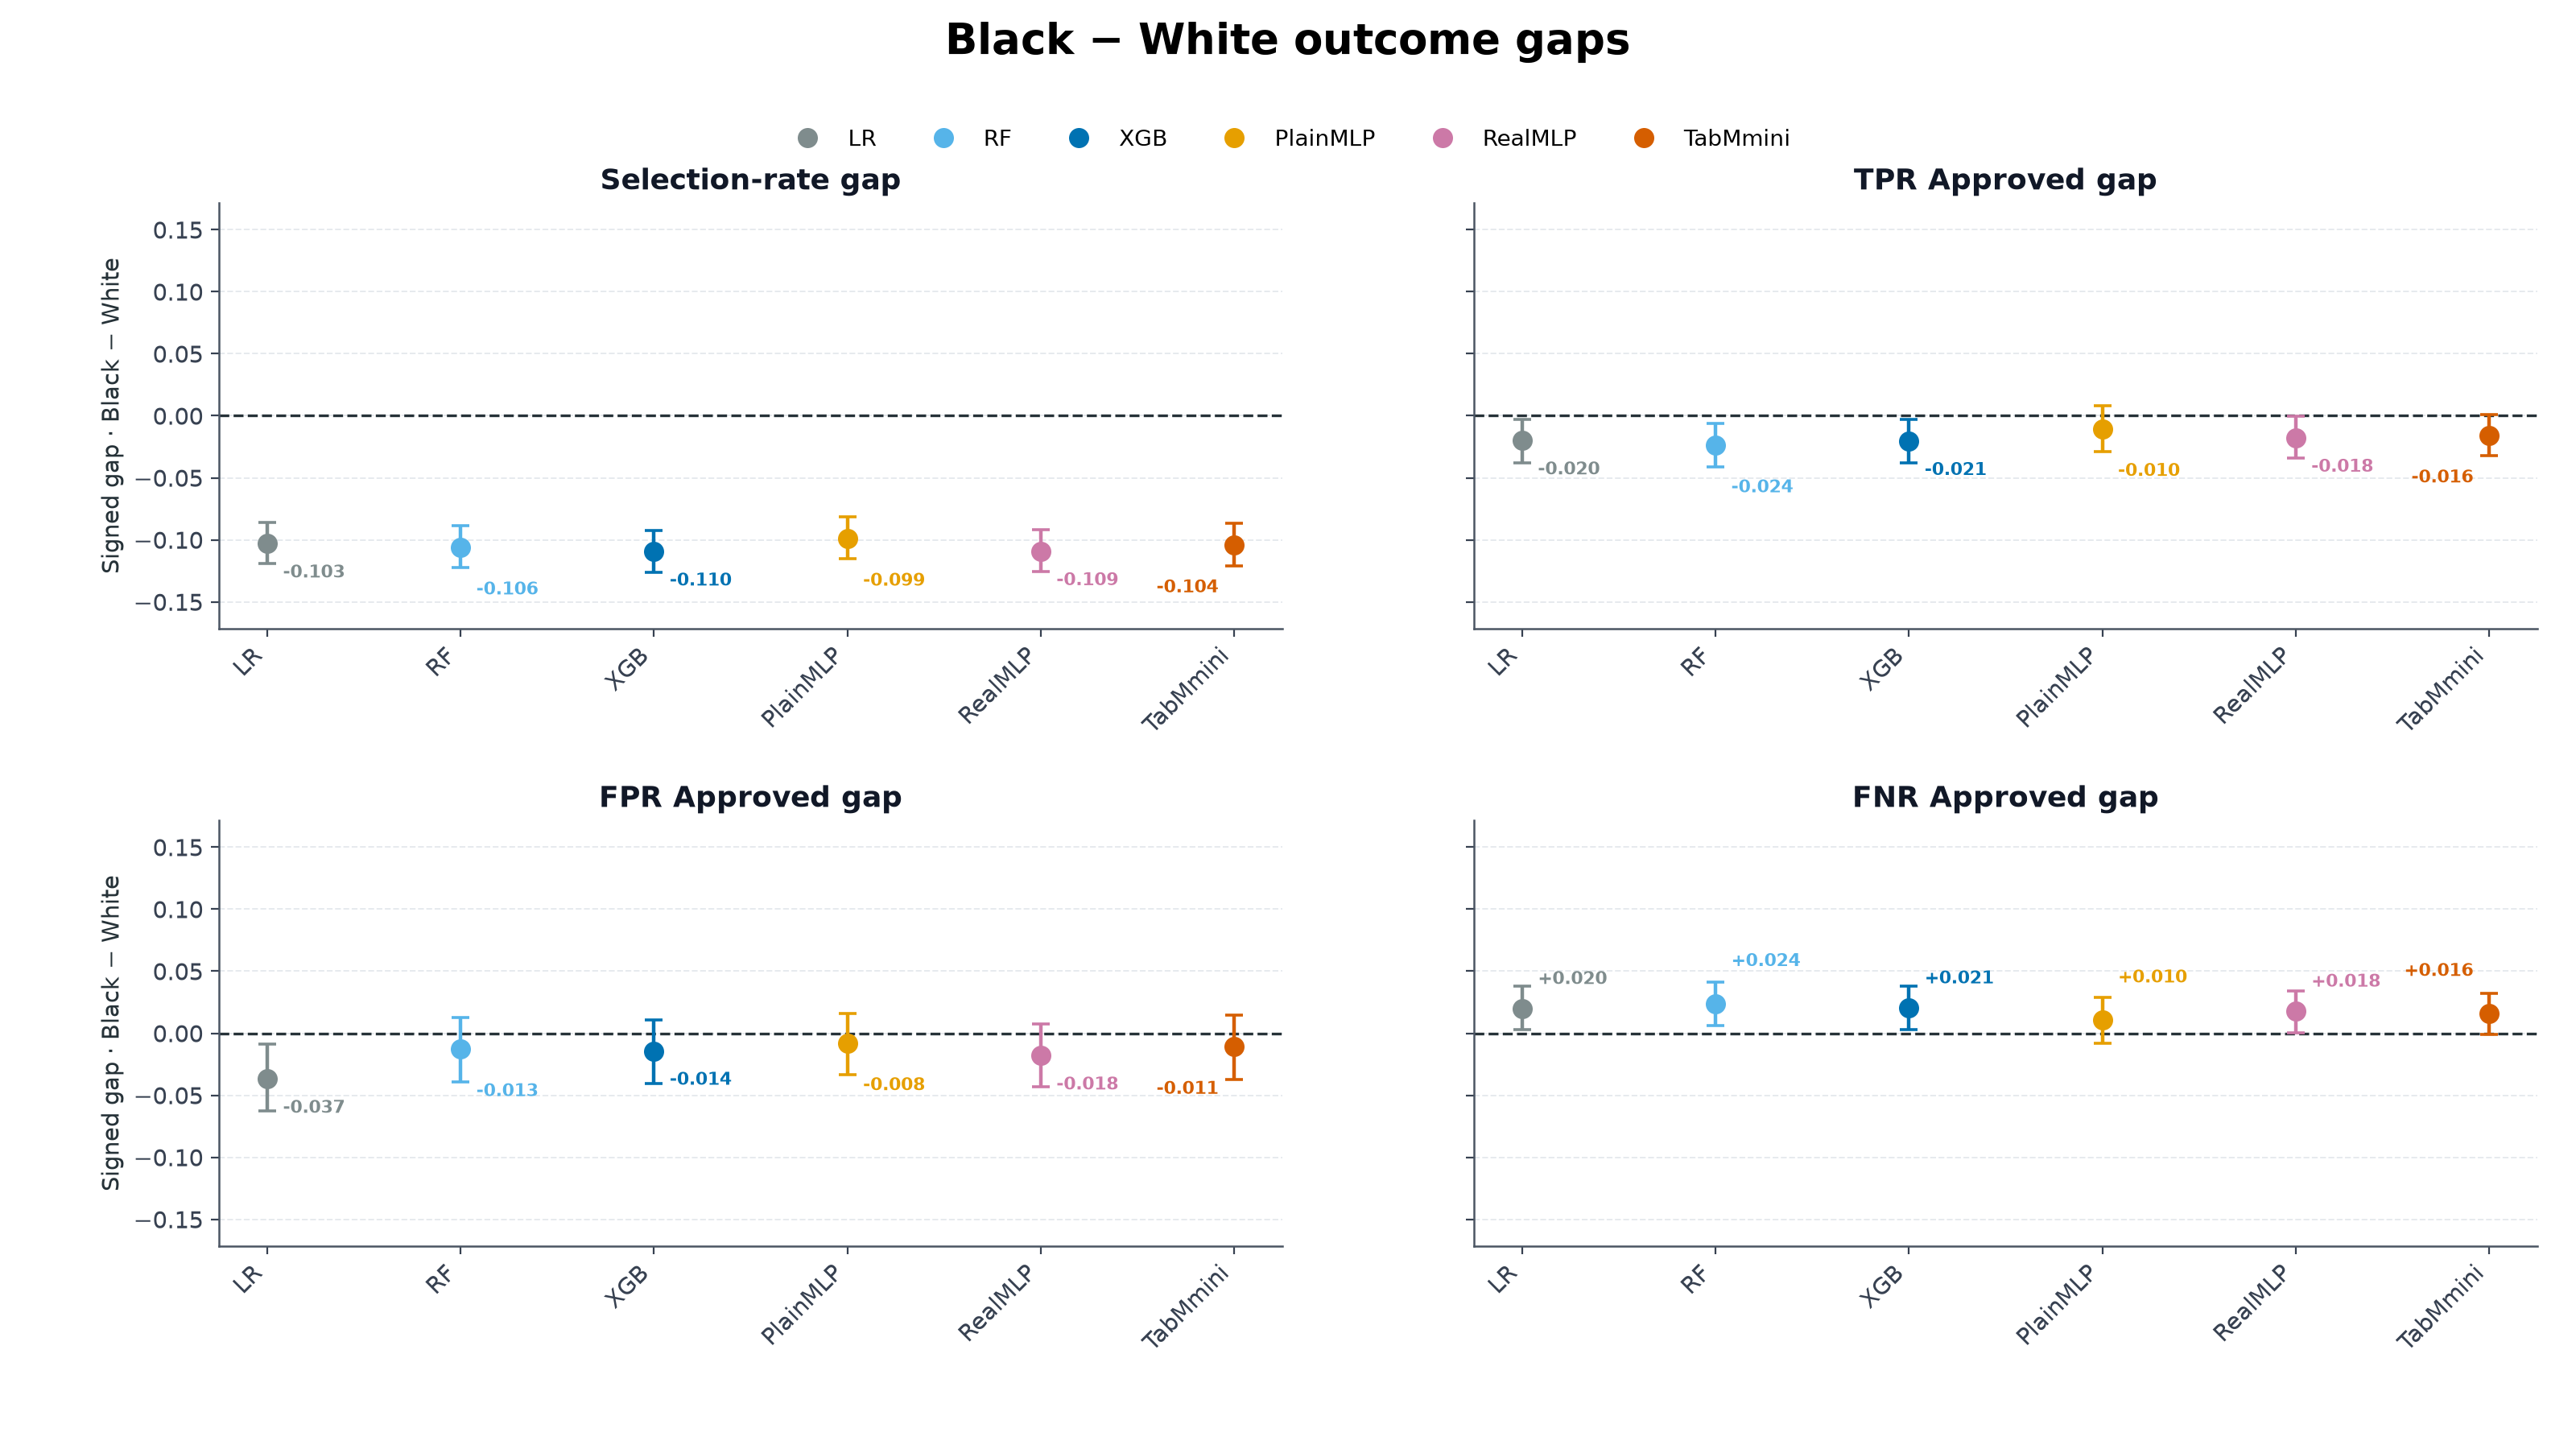

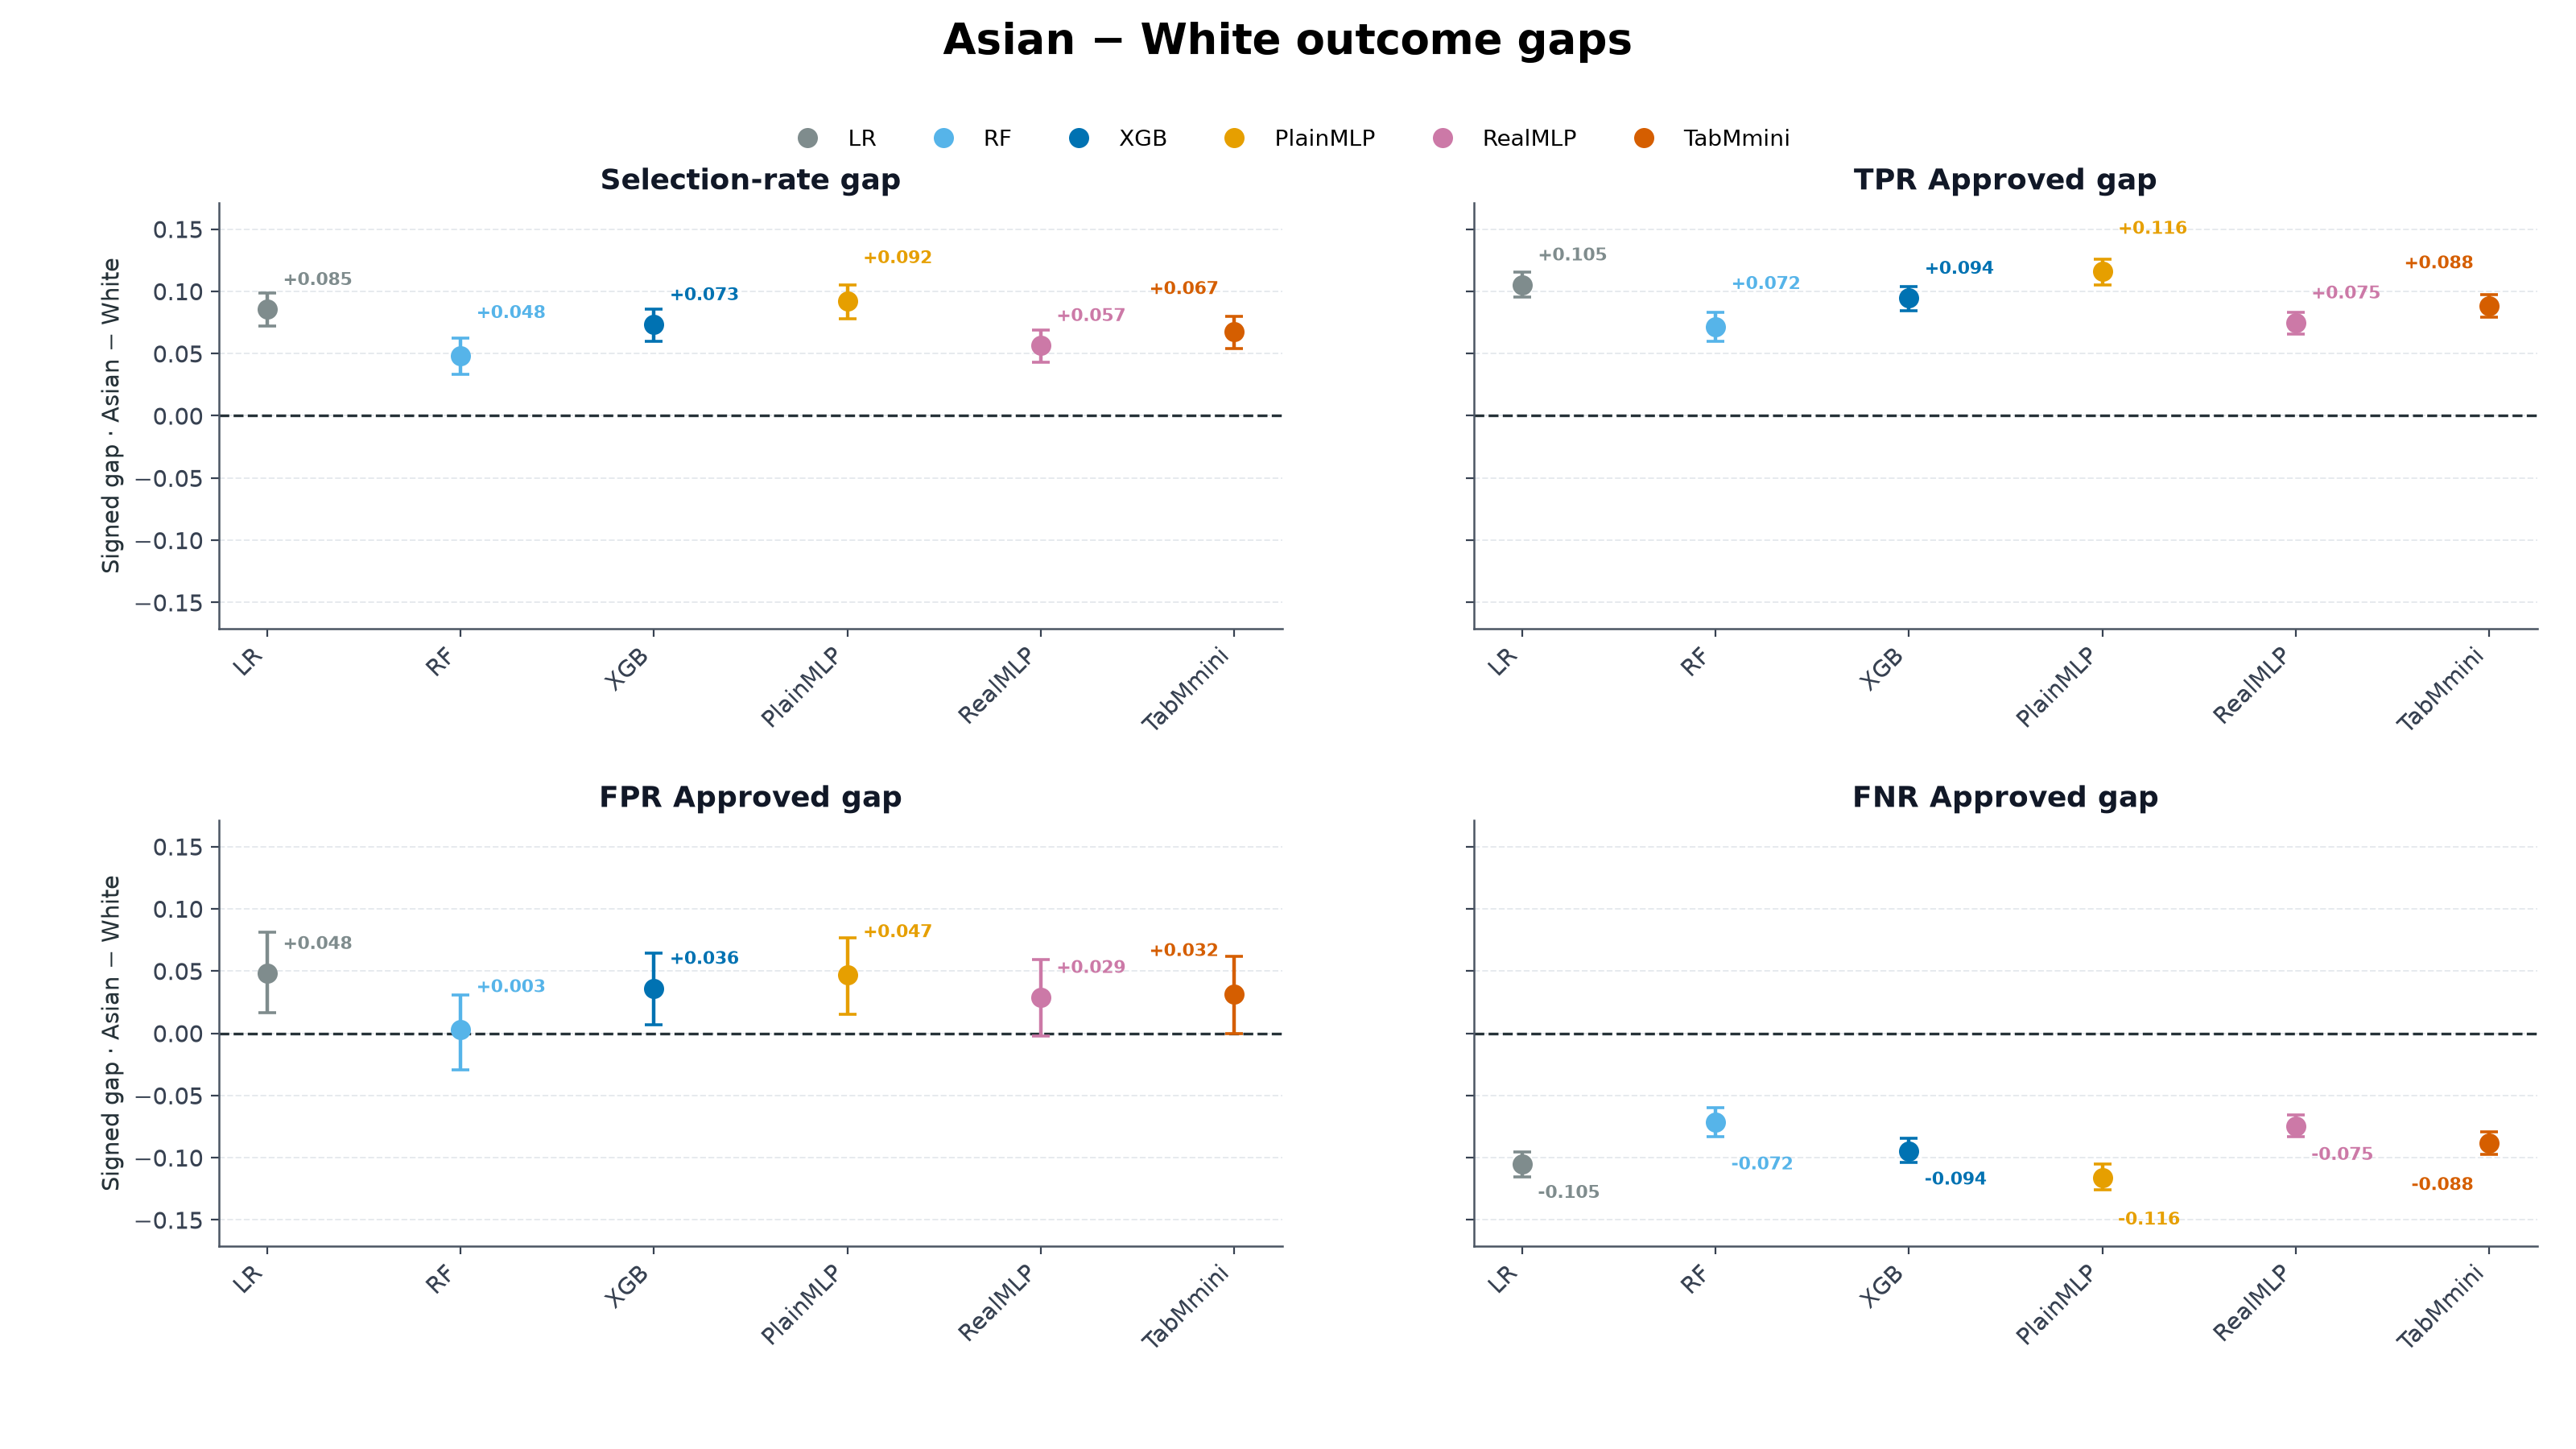

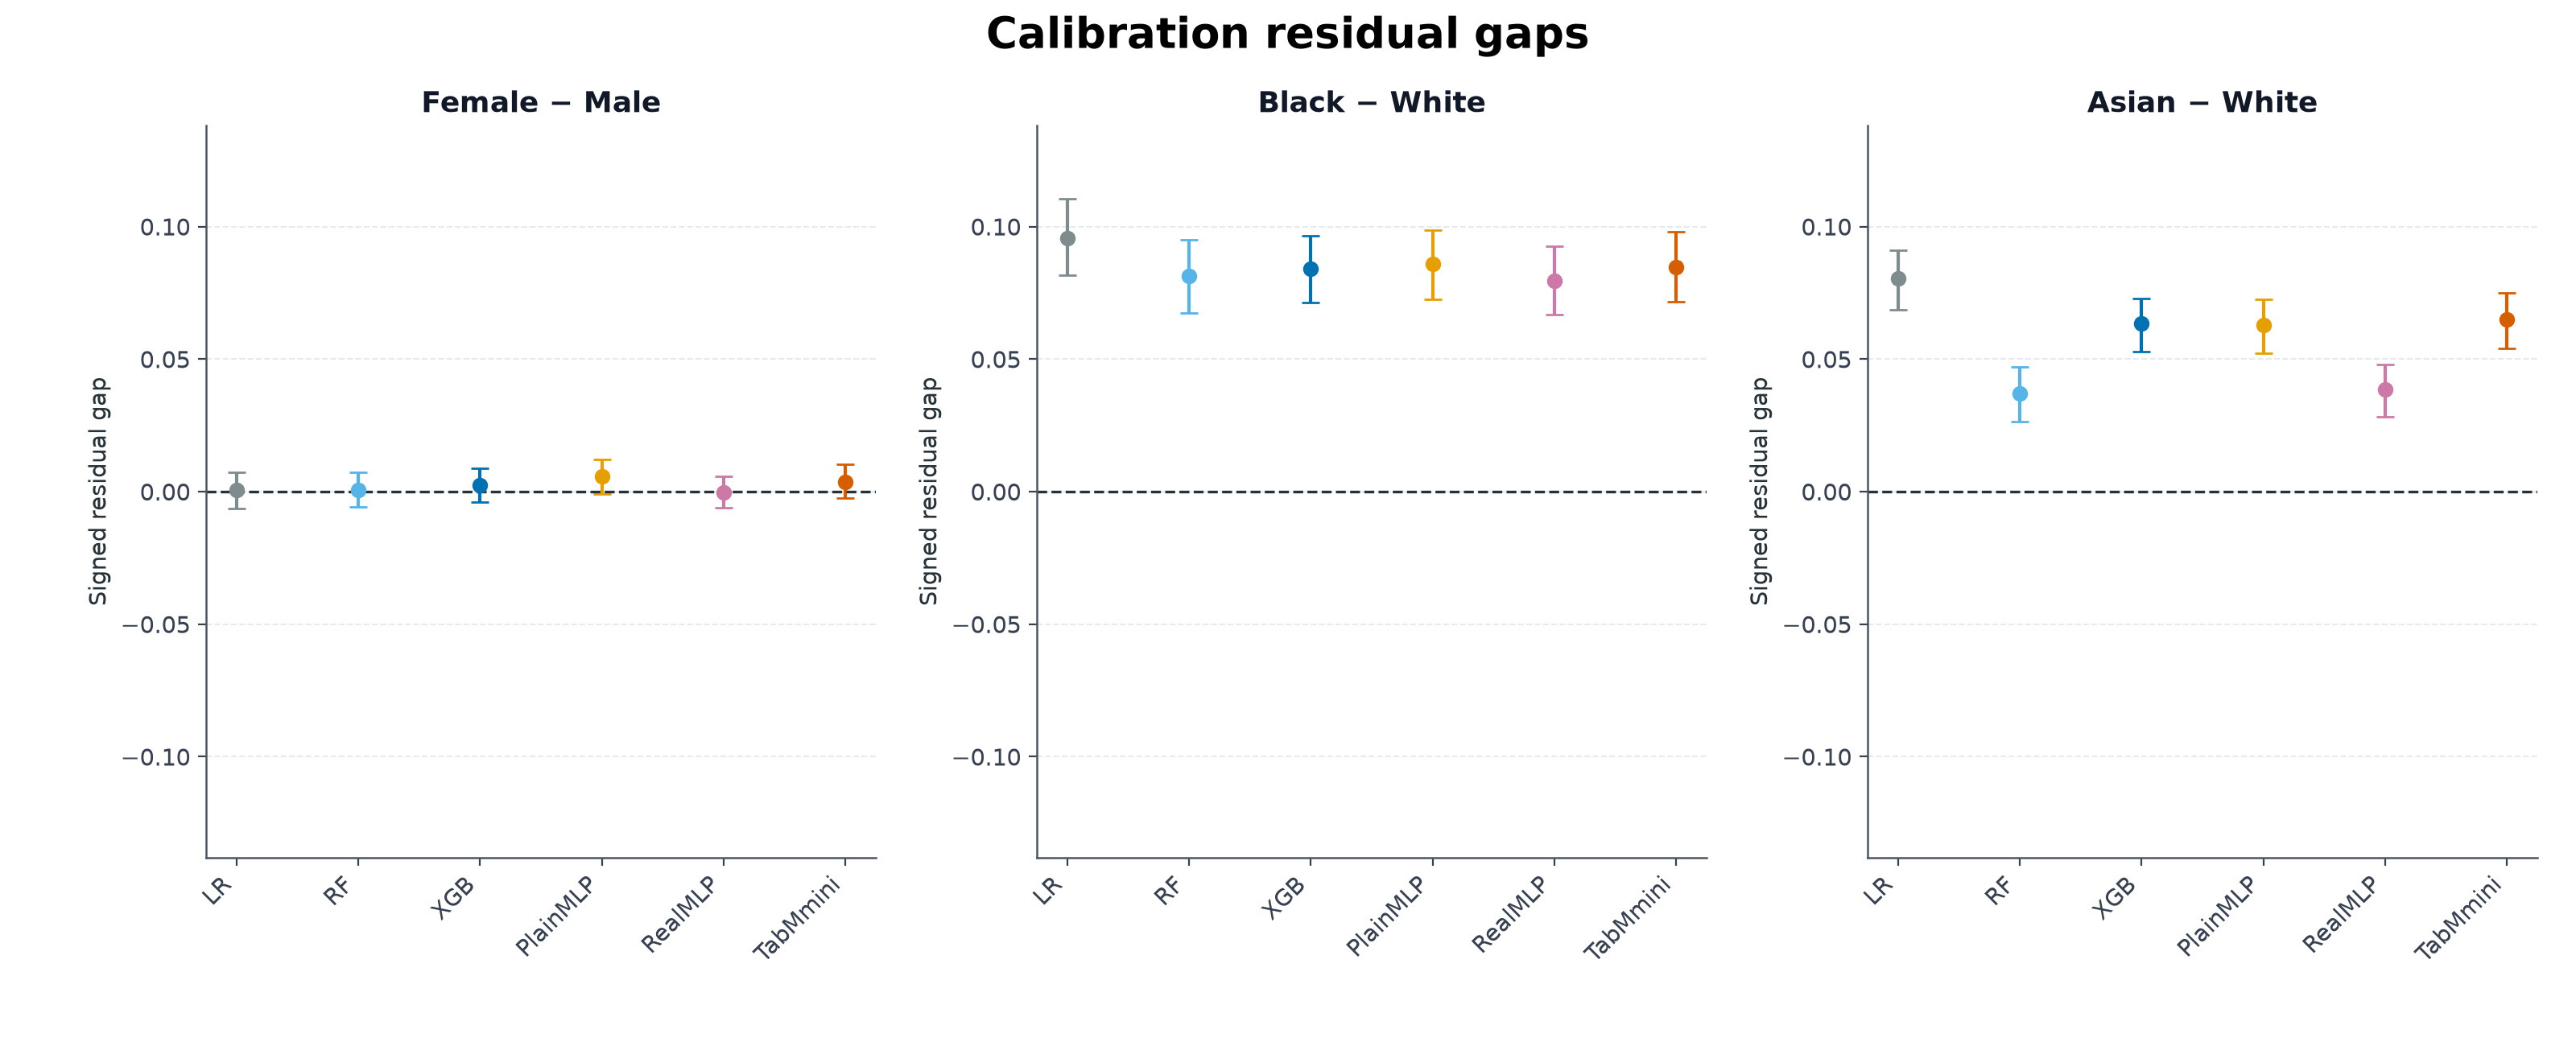

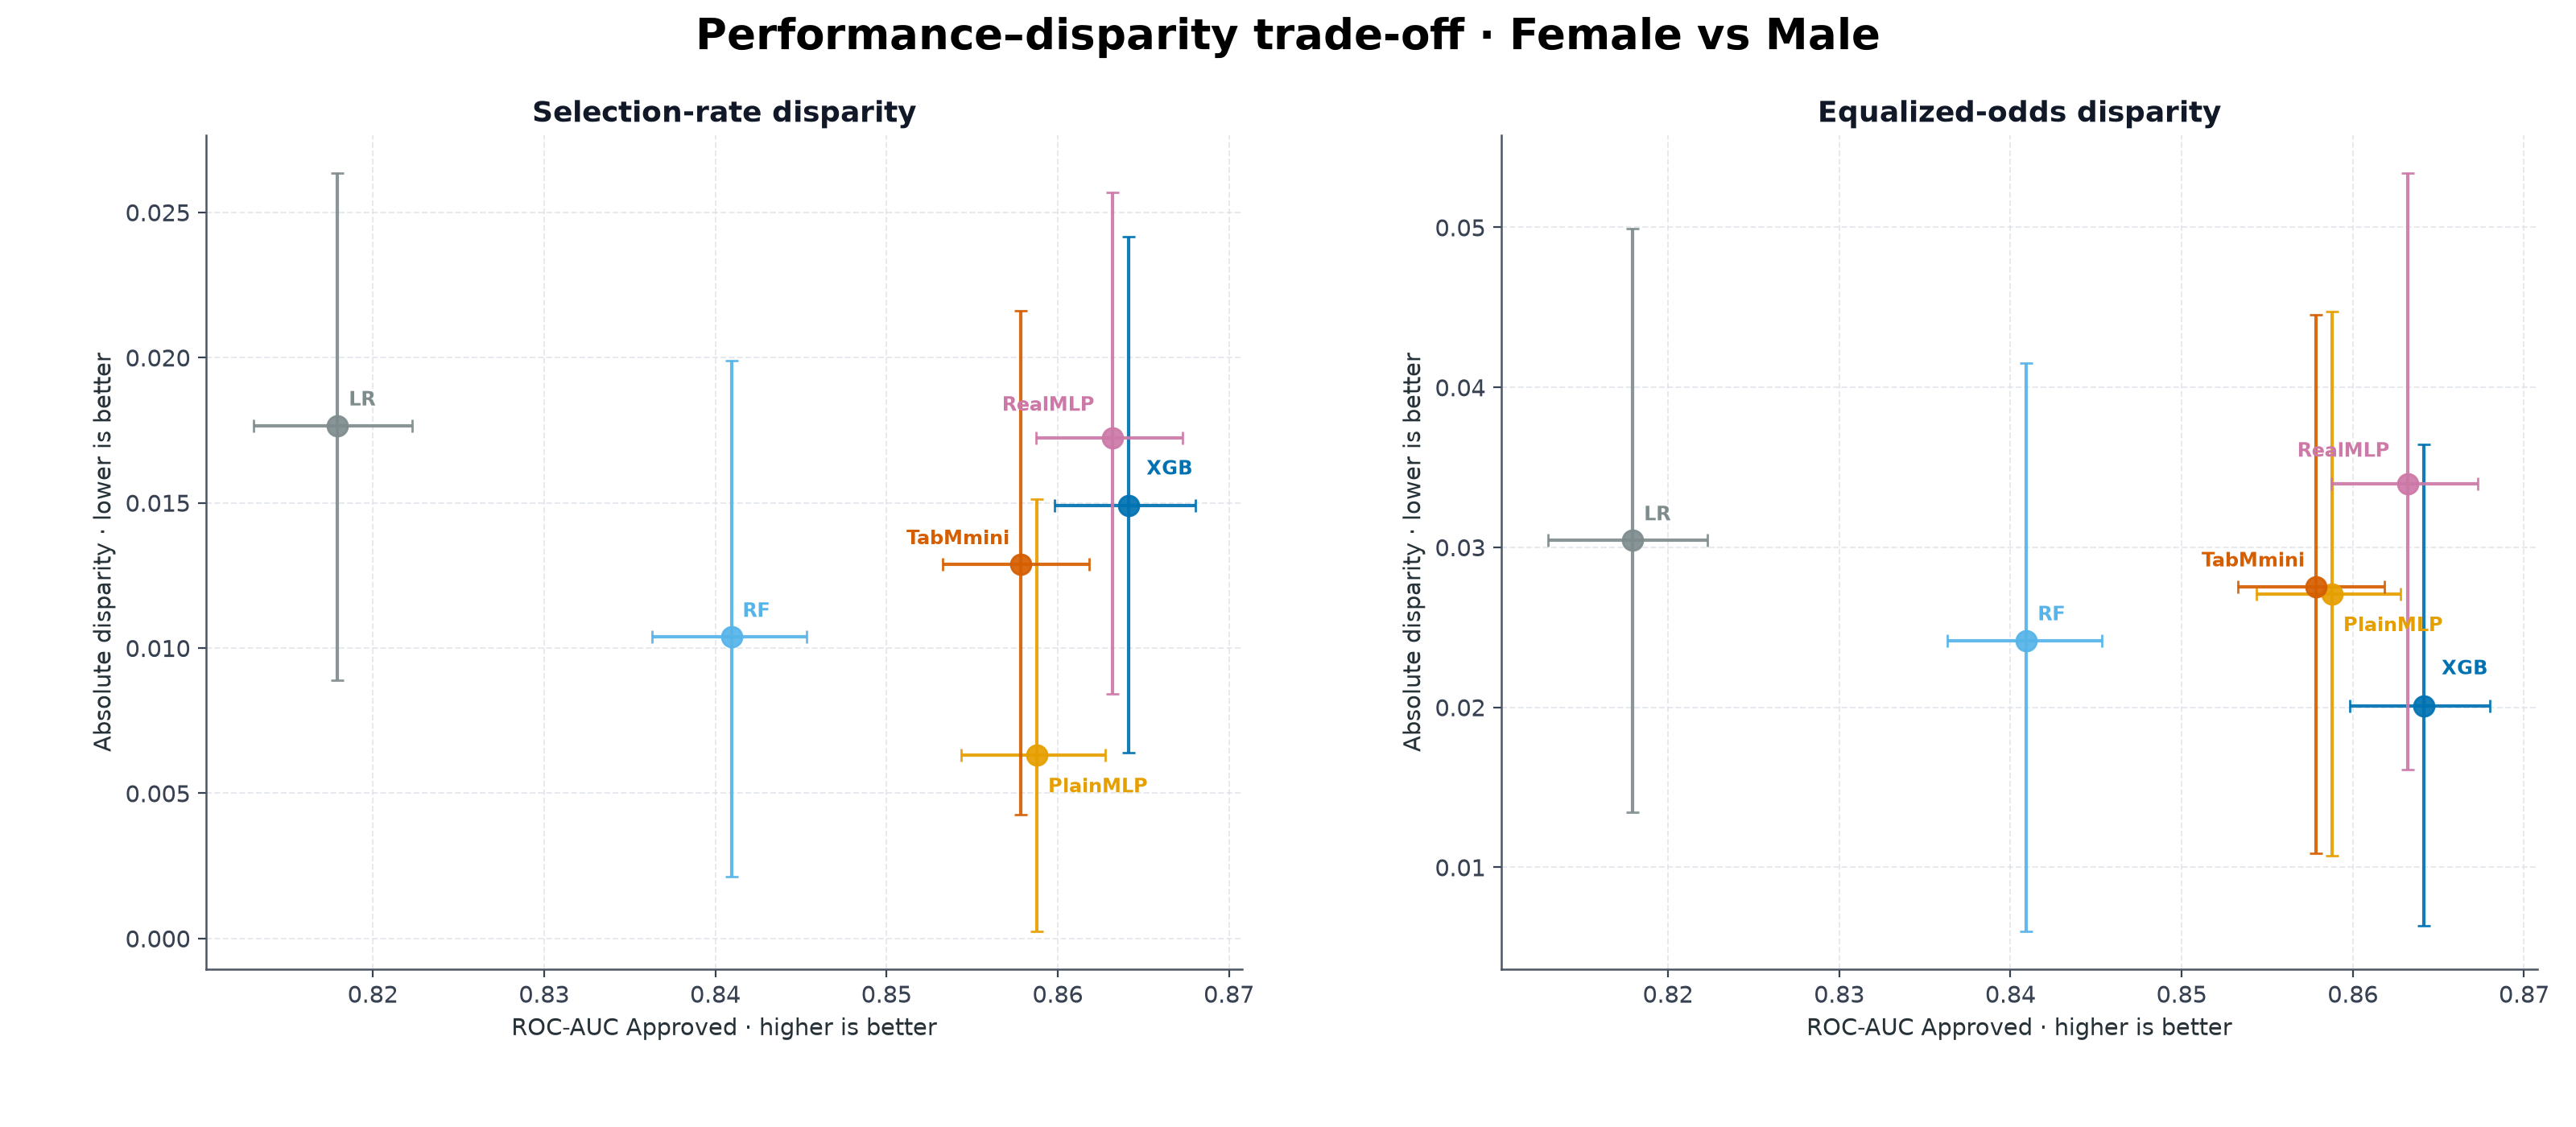

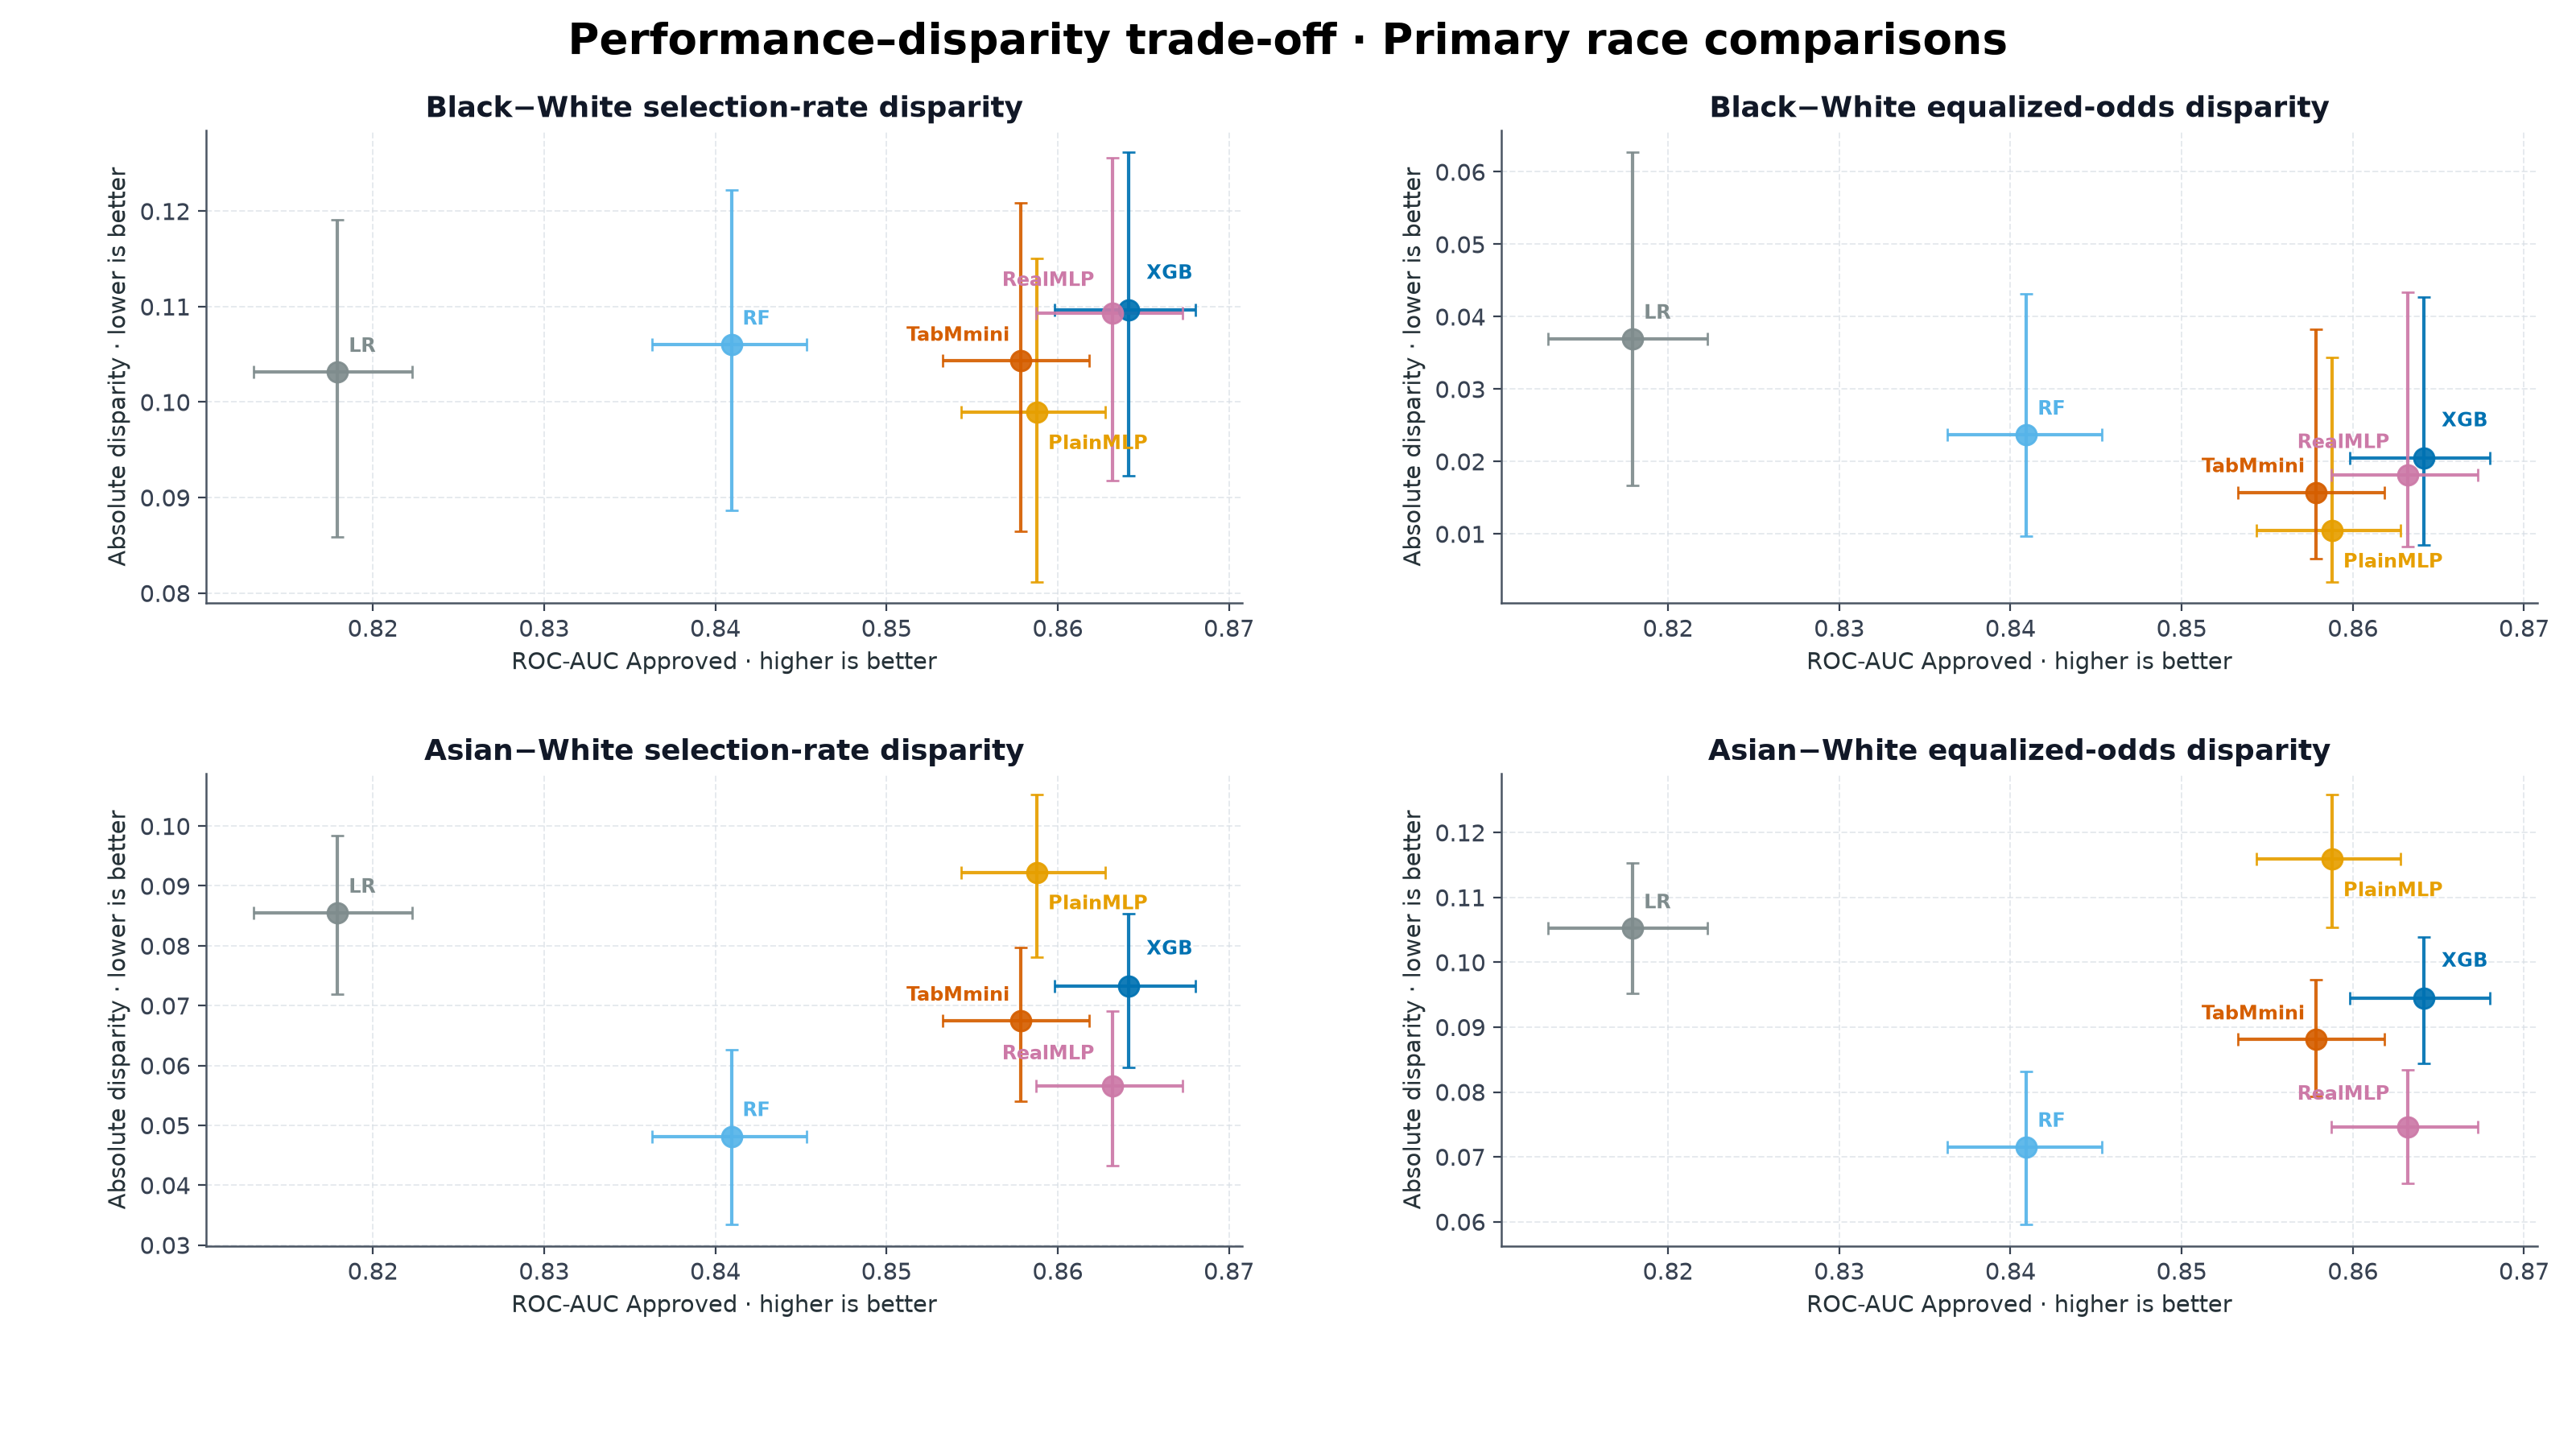

In [12]:
RQ3_COMPARISONS = [
    ('sex','applicant_sex','Female','Male','Female − Male'),
    ('black_white','derived_race','Black or African American','White','Black − White'),
    ('asian_white','derived_race','Asian','White','Asian − White'),
]

def signed_text(value):
    return f'{value:+.5f}' if abs(value) < 0.001 else f'{value:+.3f}'

def comparison_block(attribute,target,reference,metrics):
    block=rq3_all.loc[rq3_all['result_type'].eq('pairwise') & rq3_all['attribute'].eq(attribute)
        & rq3_all['target_group'].eq(target) & rq3_all['reference_group'].eq(reference)
        & rq3_all['metric'].isin(metrics)].copy()
    expected={(m,metric) for m in MODEL_ORDER for metric in metrics}
    assert set(zip(block['model'],block['metric'])) == expected
    assert block['ci_status'].eq('defined').all()
    return block

def plot_gap_grid(profile,attribute,target,reference,label):
    is_slide=profile=='slide'; block=comparison_block(attribute,target,reference,[m for m,_ in RQ3_METRICS])
    fig,axes=plt.subplots(2,2,figsize=(16,9) if is_slide else (7.2,7.8),sharex=True,sharey=True); x=np.arange(6)
    limit=float(np.nanmax(np.abs(block[['ci_lower','ci_upper']].to_numpy(float))))*1.36
    for ax,(metric,title) in zip(axes.flat,RQ3_METRICS):
        panel=block.loc[block['metric'].eq(metric)].set_index('model').loc[MODEL_ORDER]
        values=panel['point_estimate'].to_numpy(float); lower=panel['ci_lower'].to_numpy(float); upper=panel['ci_upper'].to_numpy(float)
        for i,model in enumerate(MODEL_ORDER):
            err=np.array([[values[i]-lower[i]],[upper[i]-values[i]]])
            ax.errorbar(i,values[i],yerr=err,fmt='o',markersize=8 if is_slide else 6.5,color=MODEL_COLORS[model],
                        ecolor=MODEL_COLORS[model],elinewidth=1.6,capsize=4,capthick=1.3,zorder=3)
            if is_slide:
                direction=1 if values[i]>=0 else -1; vertical=direction*(9+6*(i%2)); horizontal=-7 if i==5 else 7
                ax.annotate(signed_text(values[i]),(i,values[i]),xytext=(horizontal,vertical),textcoords='offset points',
                            ha='right' if i==5 else 'left',va='bottom' if values[i]>=0 else 'top',
                            fontsize=8,fontweight='bold',color=MODEL_COLORS[model])
        ax.axhline(0,color='#263238',linewidth=1.2,linestyle='--',zorder=1); ax.set_title(title,fontsize=PROFILES[profile]['panel'])
        ax.set_ylim(-limit,limit); ax.set_xticks(x,[MODEL_LABELS[m] for m in MODEL_ORDER],rotation=45,ha='right'); ax.tick_params(axis='x',labelbottom=True); polish_axis(ax,'y')
    for ax in axes[:,0]: ax.set_ylabel(f'Signed gap · {label}')
    fig.legend(handles=model_legend(),loc='upper center',bbox_to_anchor=(0.5,0.925 if is_slide else 0.94),ncol=6,frameon=False,fontsize=9 if not is_slide else 10)
    fig.suptitle(f'{label} outcome gaps',fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.085 if is_slide else 0.13,right=0.985,top=0.86 if is_slide else 0.88,bottom=0.14,wspace=0.18,hspace=0.45)
    return fig

def plot_calibration_gap(profile):
    is_slide=profile=='slide'; fig,axes=plt.subplots(1,3,figsize=(16,6.5)) if is_slide else plt.subplots(3,1,figsize=(7.2,9.3))
    axes=np.atleast_1d(axes); metric='calibration_residual_gap_signed'; x=np.arange(6)
    all_blocks=[]
    for _,attribute,target,reference,label in RQ3_COMPARISONS:
        all_blocks.append((label,comparison_block(attribute,target,reference,[metric])))
    limit=max(float(np.nanmax(np.abs(b[['ci_lower','ci_upper']].to_numpy(float)))) for _,b in all_blocks)*1.25
    for ax,(label,block) in zip(axes,all_blocks):
        panel=block.set_index('model').loc[MODEL_ORDER]; values=panel['point_estimate'].to_numpy(float)
        errors=np.vstack([values-panel['ci_lower'].to_numpy(float),panel['ci_upper'].to_numpy(float)-values])
        for i,m in enumerate(MODEL_ORDER): ax.errorbar(i,values[i],yerr=errors[:,i:i+1],fmt='o',color=MODEL_COLORS[m],ecolor=MODEL_COLORS[m],capsize=4)
        ax.axhline(0,color='#263238',linestyle='--',linewidth=1.2); ax.set_ylim(-limit,limit)
        ax.set_xticks(x,[MODEL_LABELS[m] for m in MODEL_ORDER],rotation=45,ha='right'); ax.set_title(label,fontsize=PROFILES[profile]['panel']); ax.set_ylabel('Signed residual gap'); polish_axis(ax,'y')
    fig.suptitle('Calibration residual gaps',fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.08 if is_slide else 0.14,right=0.985,top=0.88 if is_slide else 0.93,bottom=0.18 if is_slide else 0.09,wspace=0.24,hspace=0.42)
    return fig

def disparity_panel(ax,attribute,target,reference,metric,title,profile):
    auc=ordered_metric(rq1_all,'roc_auc_approved'); gaps=comparison_block(attribute,target,reference,[metric]).set_index('model').loc[MODEL_ORDER]
    xv=auc['estimate'].to_numpy(float); yv=gaps['point_estimate'].to_numpy(float)
    xerr=np.vstack([xv-auc['ci_low'].to_numpy(float),auc['ci_high'].to_numpy(float)-xv])
    yerr=np.vstack([yv-gaps['ci_lower'].to_numpy(float),gaps['ci_upper'].to_numpy(float)-yv])
    for i,m in enumerate(MODEL_ORDER):
        ax.errorbar(xv[i],yv[i],xerr=xerr[:,i:i+1],yerr=yerr[:,i:i+1],fmt='o',markersize=9 if profile=='slide' else 7,
                    color=MODEL_COLORS[m],ecolor=MODEL_COLORS[m],capsize=3,alpha=0.92)
        if m == 'tabmmini': offset_x,offset_y,h_align,v_align = -5,7,'right','bottom'
        elif m == 'realmlp': offset_x,offset_y,h_align,v_align = -8,10,'right','bottom'
        elif m == 'plain_mlp': offset_x,offset_y,h_align,v_align = 5,-10,'left','top'
        elif m == 'xgboost': offset_x,offset_y,h_align,v_align = 8,12,'left','bottom'
        else: offset_x,offset_y,h_align,v_align = 5,7,'left','bottom'
        ax.annotate(MODEL_LABELS[m],(xv[i],yv[i]),xytext=(offset_x,offset_y),textcoords='offset points',
                    ha=h_align,va=v_align,fontsize=8.5 if profile=='slide' else 9,color=MODEL_COLORS[m],fontweight='bold')
    ax.set_title(title,fontsize=PROFILES[profile]['panel']); ax.set_xlabel('ROC-AUC Approved · higher is better')
    ax.set_ylabel('Absolute disparity · lower is better'); polish_axis(ax,'both')

def plot_performance_disparity(profile,race=False):
    is_slide=profile=='slide'
    if not race:
        fig,axes=plt.subplots(1,2,figsize=(16,7) if is_slide else (7.2,4.2))
        specs=[('applicant_sex','Female','Male','selection_rate_gap_absolute','Selection-rate disparity'),
               ('applicant_sex','Female','Male','equalized_odds_gap','Equalized-odds disparity')]
        title='Performance–disparity trade-off · Female vs Male'
    else:
        fig,axes=plt.subplots(2,2,figsize=(16,9) if is_slide else (7.2,7.8))
        specs=[('derived_race','Black or African American','White','selection_rate_gap_absolute','Black−White selection-rate disparity'),
               ('derived_race','Black or African American','White','equalized_odds_gap','Black−White equalized-odds disparity'),
               ('derived_race','Asian','White','selection_rate_gap_absolute','Asian−White selection-rate disparity'),
               ('derived_race','Asian','White','equalized_odds_gap','Asian−White equalized-odds disparity')]
        title='Performance–disparity trade-off · Primary race comparisons'
    for ax,spec in zip(np.atleast_1d(axes).flat,specs): disparity_panel(ax,*spec,profile)
    fig.suptitle(title,fontsize=PROFILES[profile]['title'],fontweight='bold',y=0.985)
    fig.subplots_adjust(left=0.08 if is_slide else 0.12,right=0.985,top=0.88 if not race else 0.91,bottom=0.14 if is_slide else 0.12,wspace=0.25,hspace=0.36)
    return fig

for profile in PROFILES:
    for slug,attribute,target,reference,label in RQ3_COMPARISONS:
        stage3_outputs += finish_figure(plot_gap_grid(profile,attribute,target,reference,label),f'rq3_{slug}_gap_ci',profile)
    stage3_outputs += finish_figure(plot_calibration_gap(profile),'rq3_calibration_residual_gap',profile)
    stage3_outputs += finish_figure(plot_performance_disparity(profile,False),'rq3_performance_disparity_sex',profile)
    stage3_outputs += finish_figure(plot_performance_disparity(profile,True),'rq3_performance_disparity_race',profile)


## 10. Export and integrity checks

The table below is the final manifest. Every stem must exist as PNG and SVG in both profiles. The checks also confirm the six-model order, finite source values, CI orientation, signed-gap preservation, and 300 DPI report PNG configuration.

In [13]:
EXPECTED_STEMS = [
    'rq1_performance_overview','rq1_brier_score','rq1_recall_approved','rq1_calibration_curves','rq1_confusion_matrices_appendix',
    'rq2_gsv_sl_importance_classical','rq2_gsv_sl_importance_neural','rq2_rank_heatmaps','rq2_agreement_ci','rq2_rank_dispersion','rq2_runtime_appendix',
    'rq3_sex_gap_ci','rq3_black_white_gap_ci','rq3_asian_white_gap_ci','rq3_calibration_residual_gap',
    'rq3_performance_disparity_sex','rq3_performance_disparity_race',
]
expected_paths=[]
for profile,target in [('slide',SLIDE_DIR),('report',REPORT_DIR)]:
    for stem in EXPECTED_STEMS:
        expected_paths += [target/f'{stem}.png',target/f'{stem}.svg']
missing=[p for p in expected_paths if not p.is_file() or p.stat().st_size == 0]
assert not missing, f'Missing or empty exports: {missing}'
assert set(stage3_outputs) == set(expected_paths)
assert MODEL_ORDER == ['lr','rf','xgboost','plain_mlp','realmlp','tabmmini']
assert np.isfinite(rq1_all.loc[rq1_all['metric'].isin(required_rq1),['estimate','ci_low','ci_high']].to_numpy(float)).all()
assert np.isfinite(rq2[['normalized_importance']].to_numpy(float)).all()
assert np.isfinite(rq3_all.loc[rq3_all['ci_status'].eq('defined'),['point_estimate','ci_lower','ci_upper']].to_numpy(float)).all()
manifest=pd.DataFrame({'profile':[p.parent.name for p in expected_paths],'format':[p.suffix[1:].upper() for p in expected_paths],
                       'figure':[p.stem for p in expected_paths],'bytes':[p.stat().st_size for p in expected_paths],
                       'path':[str(p.relative_to(REPO_ROOT)) for p in expected_paths]})
print(f'Stage 3 export validation: PASS · {len(expected_paths)} files · {len(EXPECTED_STEMS)} figures × 2 profiles × 2 formats')
manifest


Stage 3 export validation: PASS · 68 files · 17 figures × 2 profiles × 2 formats


,profile,format,figure,bytes,path
0,slide,PNG,rq1_performance_overview,248185,reports\figures\publication\slide\rq1_performa...
1,slide,SVG,rq1_performance_overview,141087,reports\figures\publication\slide\rq1_performa...
2,slide,PNG,rq1_brier_score,73263,reports\figures\publication\slide\rq1_brier_sc...
3,slide,SVG,rq1_brier_score,43942,reports\figures\publication\slide\rq1_brier_sc...
4,slide,PNG,rq1_recall_approved,73845,reports\figures\publication\slide\rq1_recall_a...
...,...,...,...,...,...
63,report,SVG,rq3_calibration_residual_gap,82178,reports\figures\publication\report\rq3_calibra...
64,report,PNG,rq3_performance_disparity_sex,174782,reports\figures\publication\report\rq3_perform...
65,report,SVG,rq3_performance_disparity_sex,96773,reports\figures\publication\report\rq3_perform...
66,report,PNG,rq3_performance_disparity_race,343302,reports\figures\publication\report\rq3_perform...
